# Листок № 3: решения по отдельным заданиям

Каждый пункт 3.1-3.5 расположен в отдельном блоке. В каждом блоке приведены аналитическое решение, статический рисунок и анимация.

Для запуска нужны `numpy`, `sympy`, `matplotlib`, `scipy`, `pillow` и Jupyter Notebook. Выполните ячейки сверху вниз; код каждого задания также можно запускать отдельно. Рисунки сохраняются в `figures/`, анимации с управлением — в `animations/*.html`, а GIF-превью — в `animations/*.gif`. В Jupyter под каждой ячейкой доступны кнопки воспроизведения, паузы и выбора кадра. GitHub показывает сохранённые графики; GIF-превью всех анимаций находятся в README.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, HTML
sp.init_printing()

## 3.1

**Задача о равномерном спуске.** Ищем гладкую неподвижную направляющую без трения. Ось $x$ направлена вправо, ось $y$ вверх; ускорение тяжести равно $(0,-g)$. Следуем детализации условия: постоянна вертикальная составляющая скорости $\dot y=-u$, где $u>0$, а не модуль полной скорости.

**Составление уравнения.** Пусть $y=f(x)$ и $\dot x>0$. Реакция $\mathbf N$ перпендикулярна касательной $(1,y')$. Проецируем второй закон Ньютона
$$m(\ddot x,\ddot y)=(0,-mg)+\mathbf N$$
на эту касательную; реакция исключается:
$$\ddot x+y'\ddot y=-gy'.$$
Из $\dot y=y'\dot x=-u$ получаем $\ddot y=0$, $\dot x=-u/y'$ и
$$\ddot x=-\frac{u^2y''}{(y')^3}.$$
Следовательно,
$$\boxed{y''=\frac{g}{u^2}(y')^4},\qquad y'<0.$$

**Решение.** Обозначим $p=y'$. Разделяем переменные:
$$p^{-4}dp=\frac{g}{u^2}dx,\qquad
-\frac{1}{3p^3}=\frac{g}{u^2}(x-x_c).$$
На правой ветви $x>x_c$:
$$p=-\left(\frac{u^2}{3g(x-x_c)}\right)^{1/3},$$
$$\boxed{y=y_c-\frac32\left(\frac{u^2}{3g}\right)^{1/3}(x-x_c)^{2/3}}.$$
Эквивалентное неявное уравнение
$$\boxed{(x-x_c)^2=\frac{8g}{9u^2}(y_c-y)^3}$$
задаёт полукубическую параболу. Левая ветвь получается отражением $x\mapsto-x$.

Для начальных данных $x(0)=x_0$, $y(0)=y_0$, $\dot x(0)=w_0>0$, $\dot y(0)=-u$ удобна параметризация. Из $\ddot x\dot x=gu$:
$$\dot x=\sqrt{w_0^2+2gut},\qquad
\boxed{x(t)=x_0+\frac{(w_0^2+2gut)^{3/2}-w_0^3}{3gu},\quad y(t)=y_0-ut}.$$
Отсюда явная форма с начальными условиями:
$$\boxed{y(x)=y_0+\frac{w_0^2-[w_0^3+3gu(x-x_0)]^{2/3}}{2g}}.$$
Здесь $x_c=x_0-w_0^3/(3gu)$, $y_c=y_0+w_0^2/(2g)$. Для движения после старта достаточно $x\ge x_0$ и $t\ge0$. Вершина $x=x_c$ имеет особенность; на графиках берём регулярные участки с $w_0>0$.

**Проверка физического смысла.** Скорость и энергия удовлетворяют
$$v^2=w_0^2+u^2+2gut,\qquad
\frac{mv^2}{2}+mgy=\mathrm{const}.$$
Вертикальная скорость постоянна, но полная скорость растёт. Реакция равна $\mathbf N=m(gu/\dot x,g)$, и $\mathbf N\cdot\mathbf v=0$. Направляющая должна удерживать точку с нужной стороны. Ни трение, ни дополнительная движущая сила не требуются.

Ниже построены три траектории с разными $u,w_0$, отмечены начальные положения; в анимации выводятся $t,y,v_y,|\mathbf v|$.


3.1: подстановка найденной кривой в ОДУ даёт 0


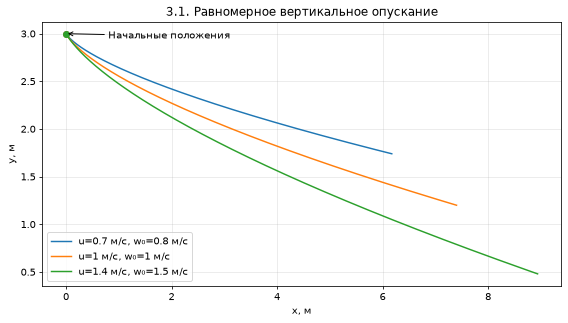


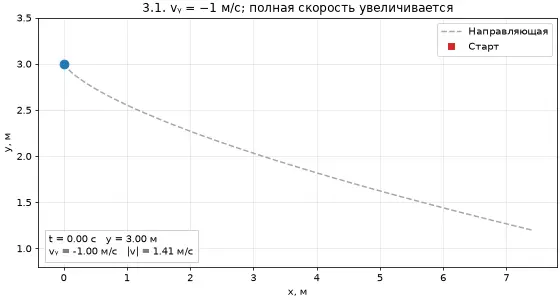
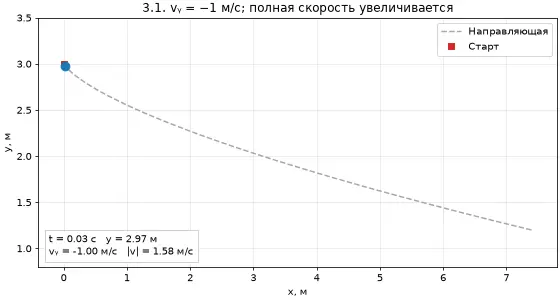
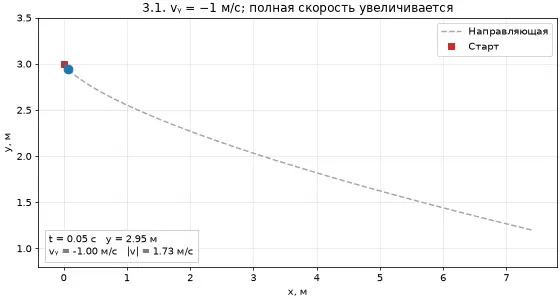
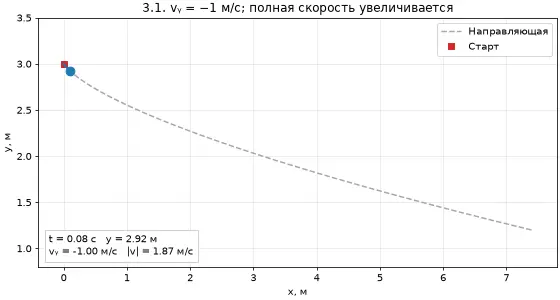
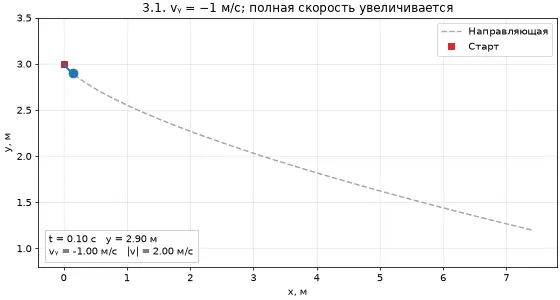
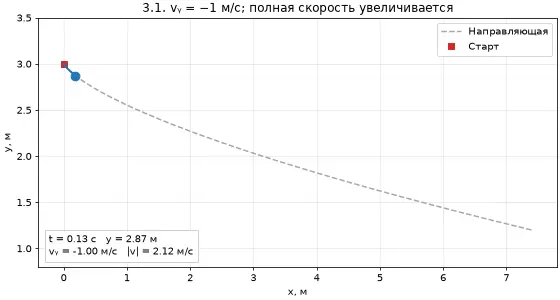
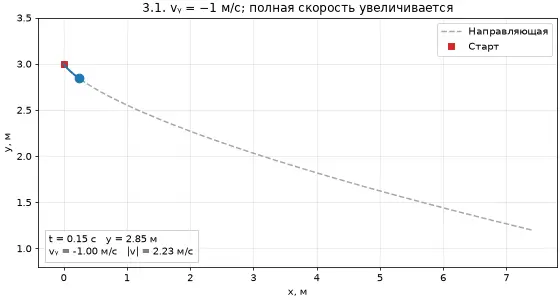
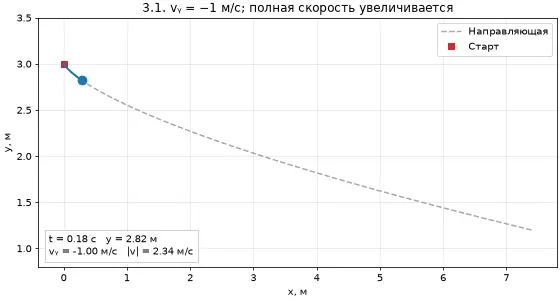
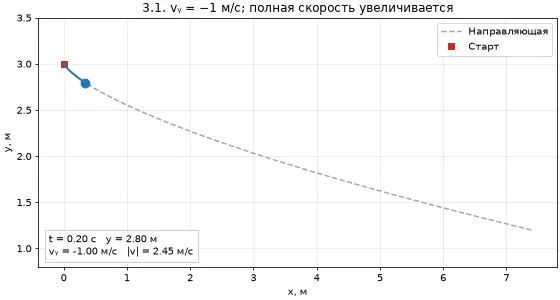
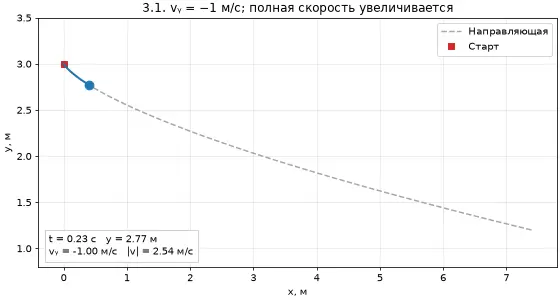
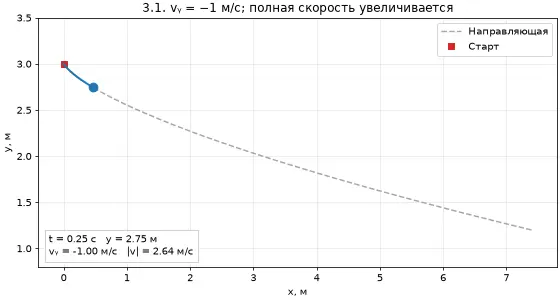
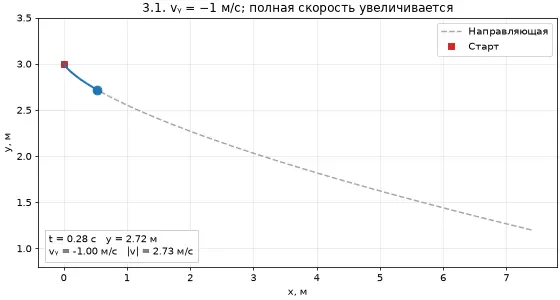
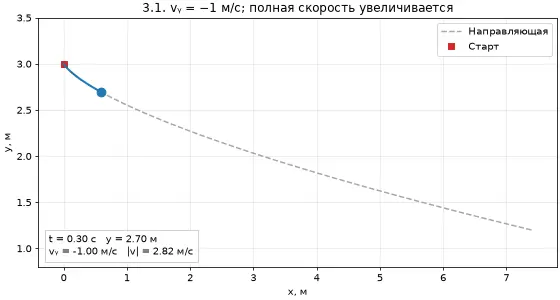
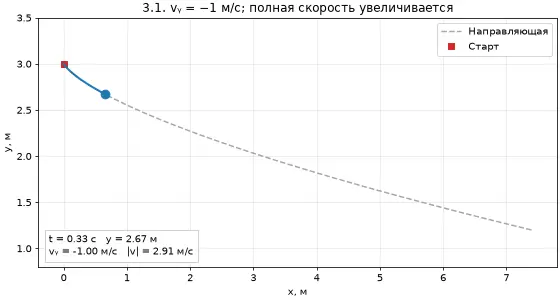
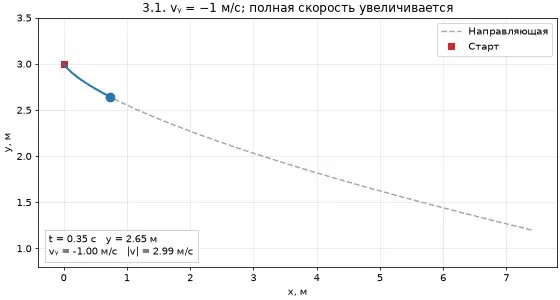
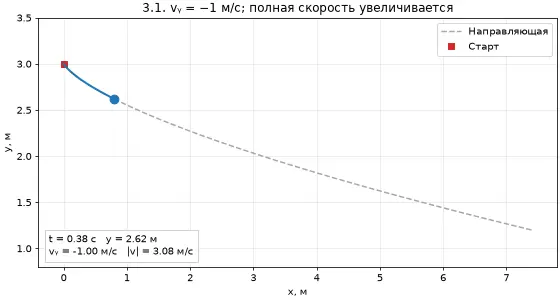
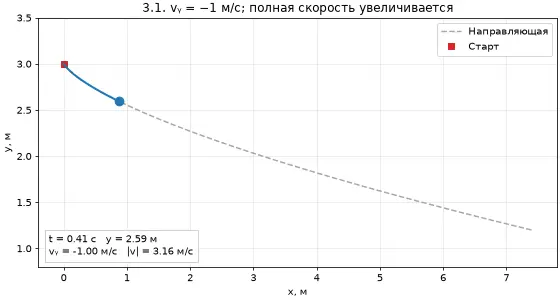
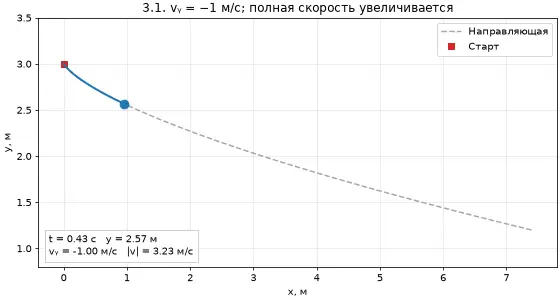
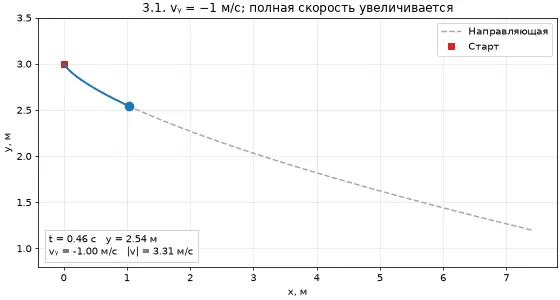
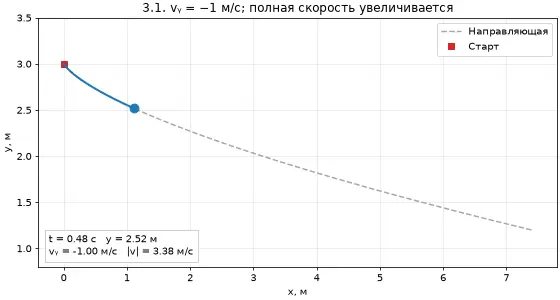
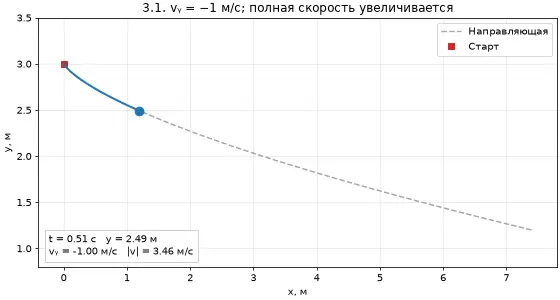
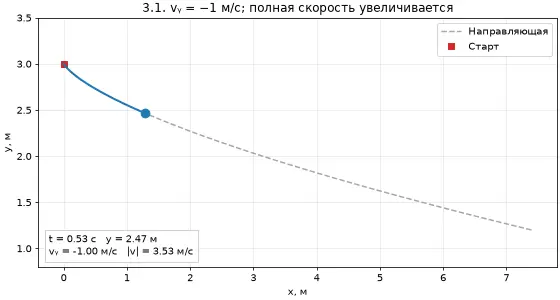
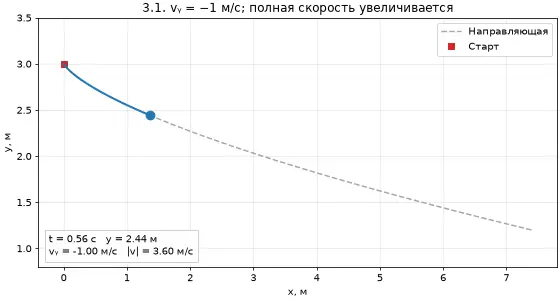
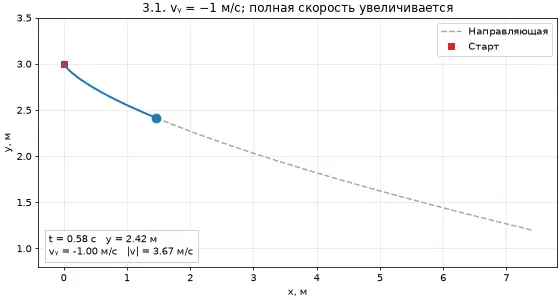
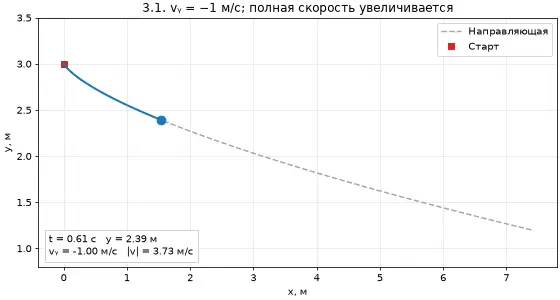
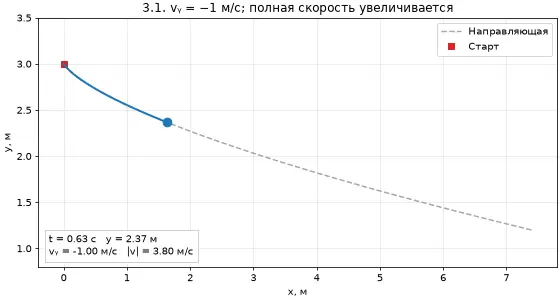
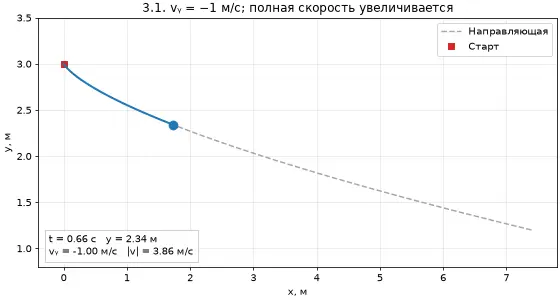
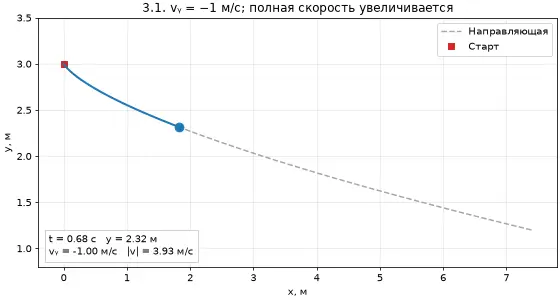
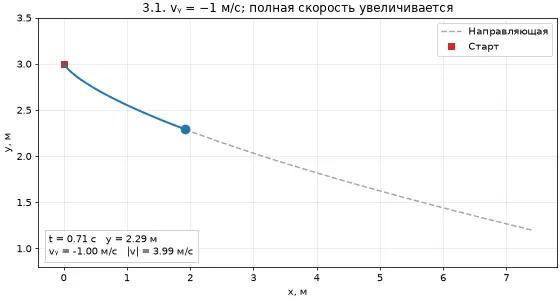
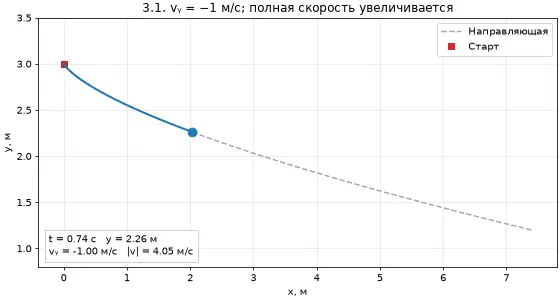
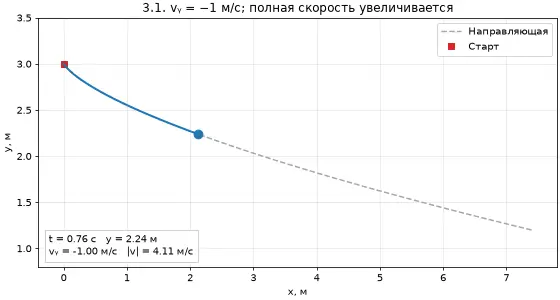
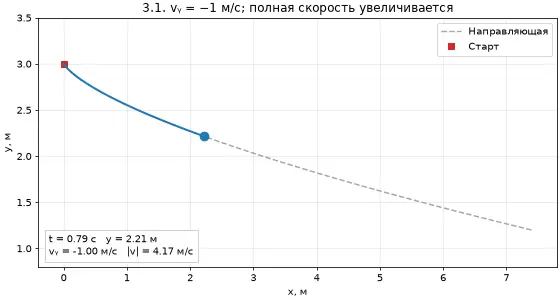
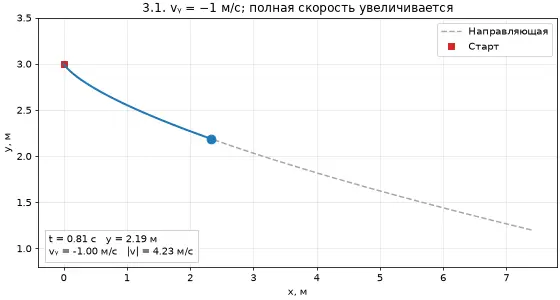
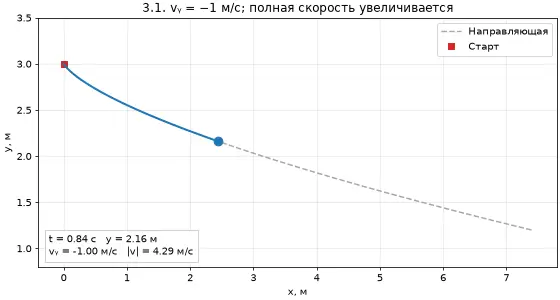
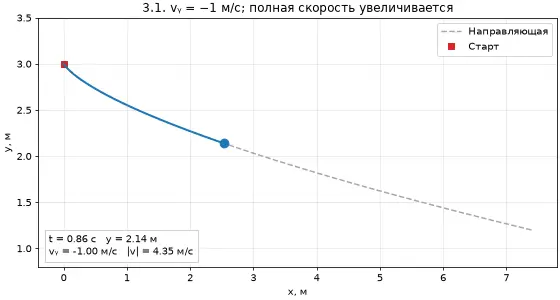
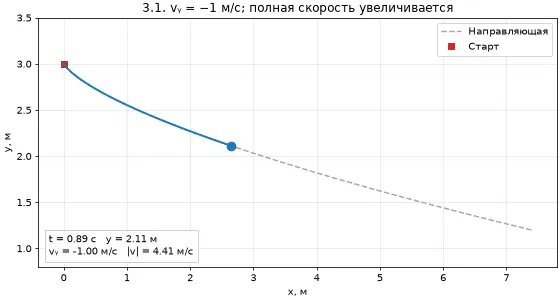
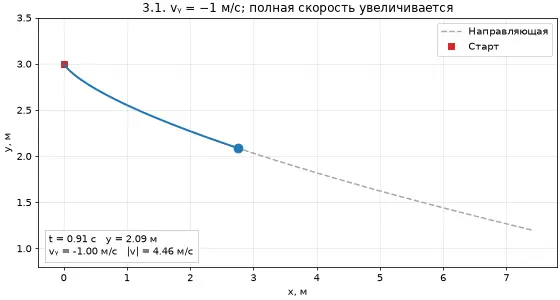
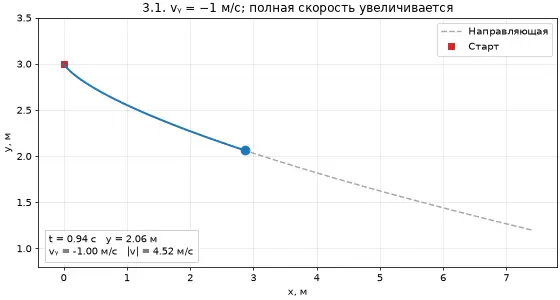
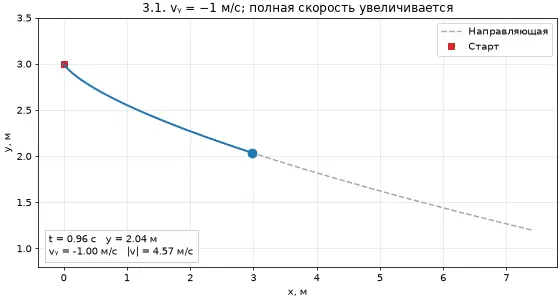
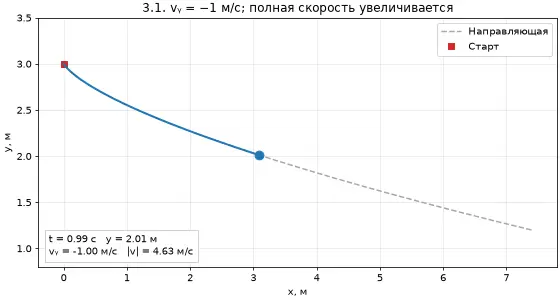
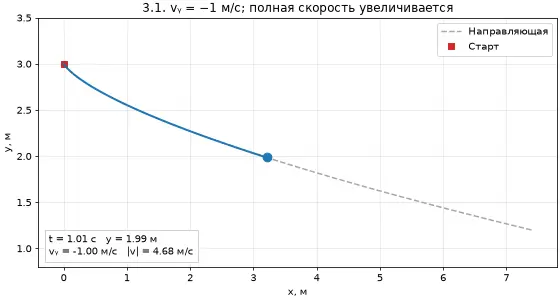
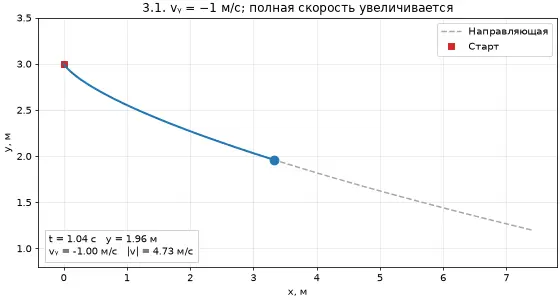
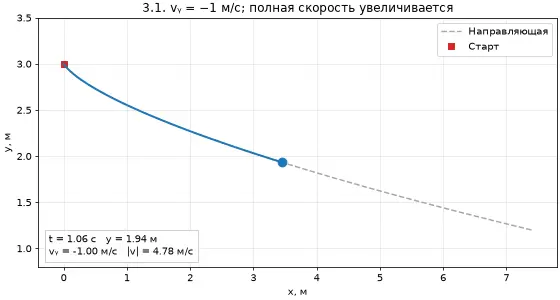
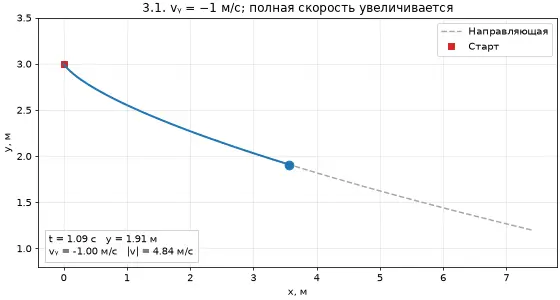
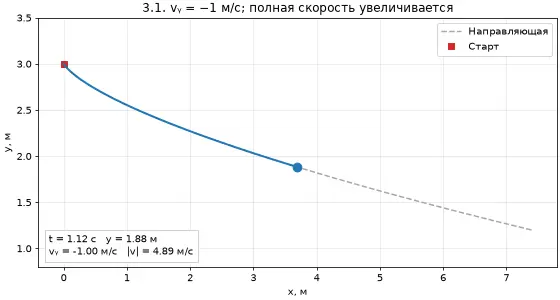
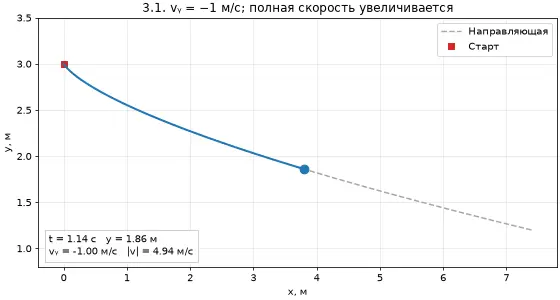
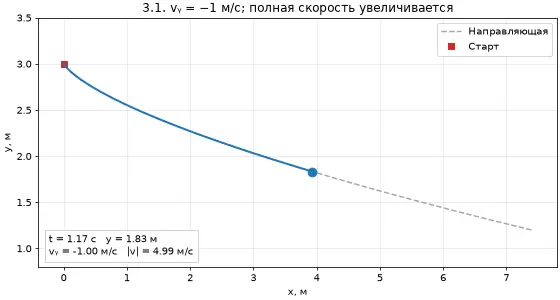
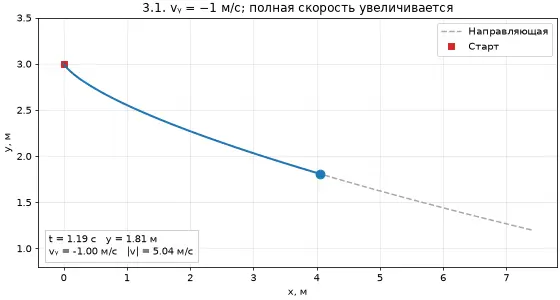
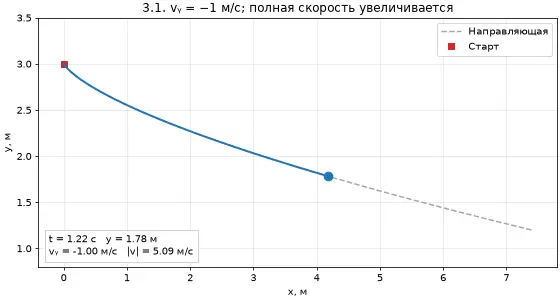
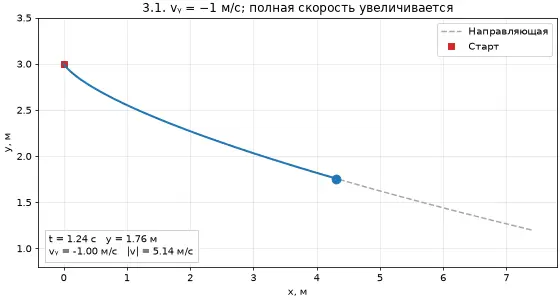
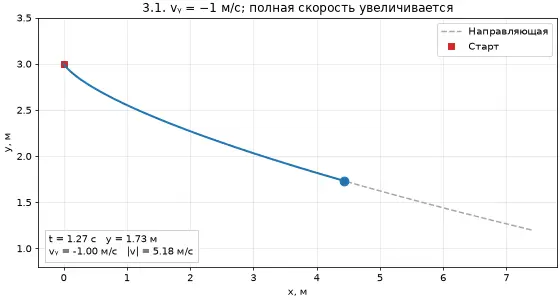
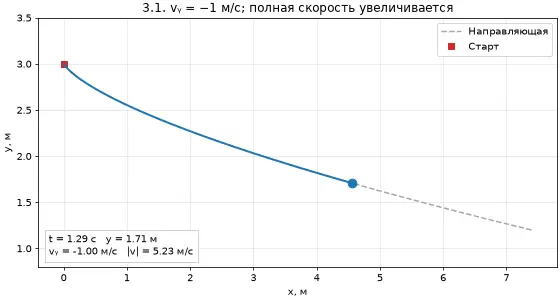
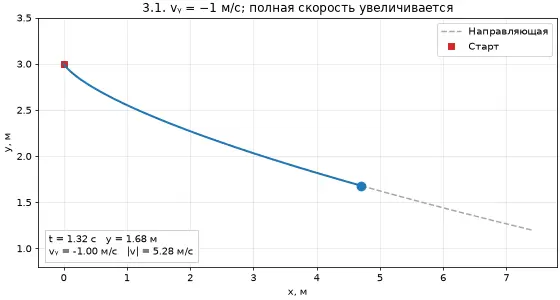
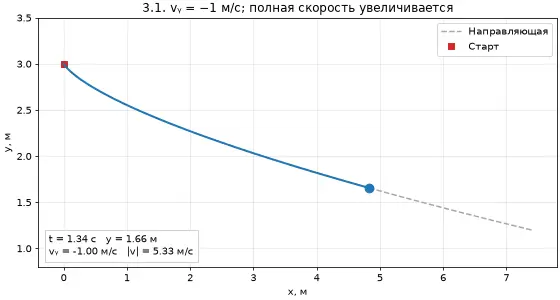
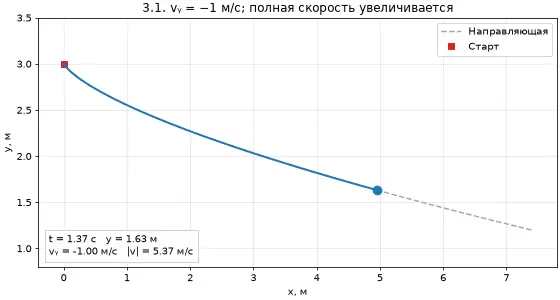
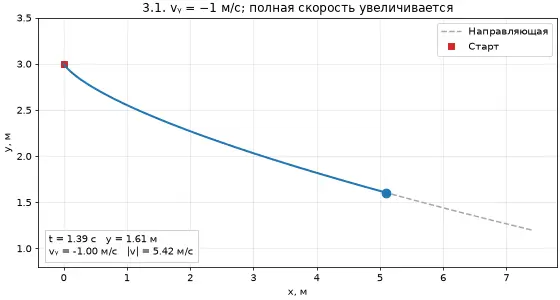
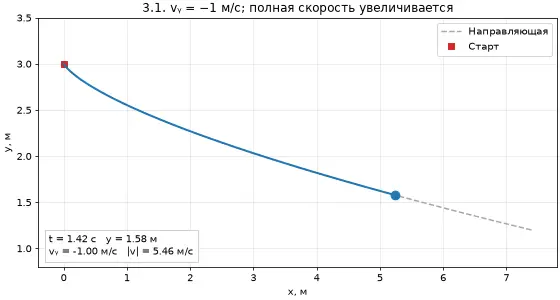
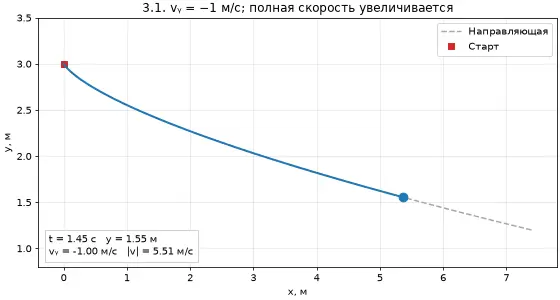
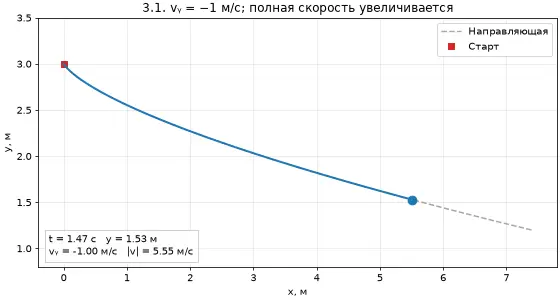
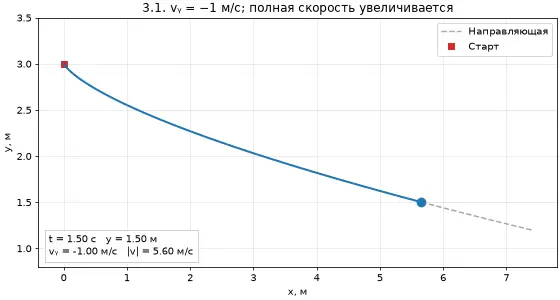
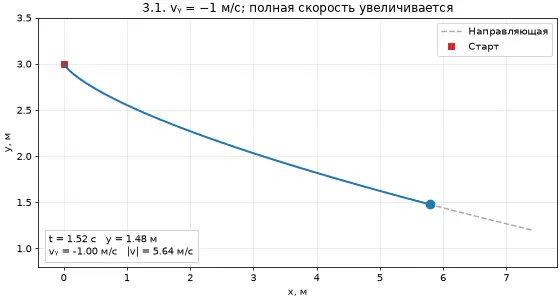
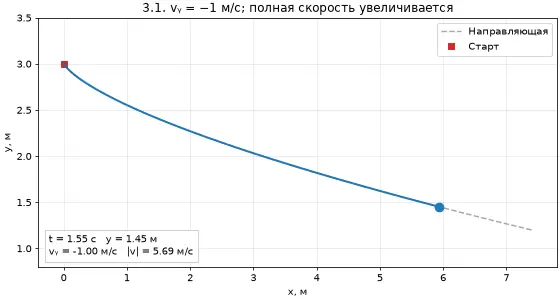
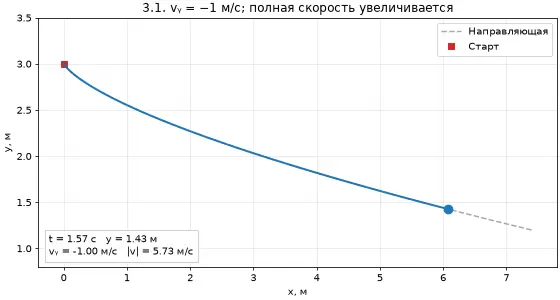
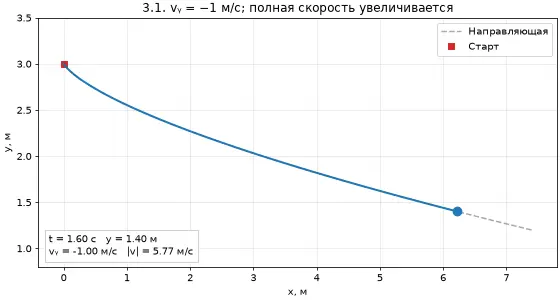
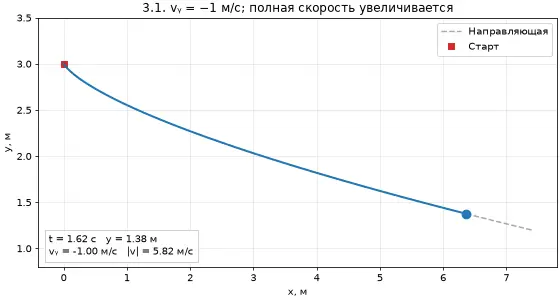
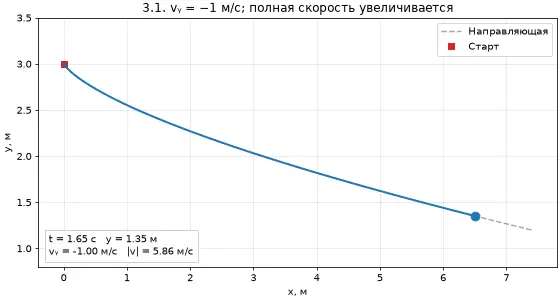
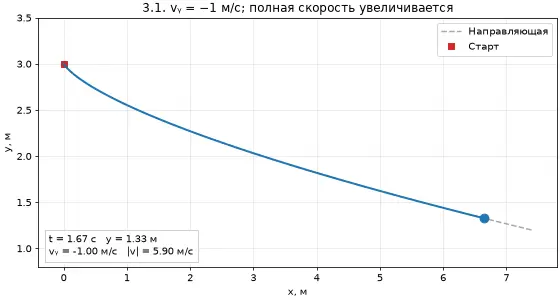
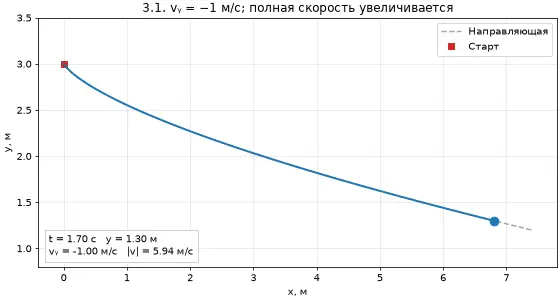
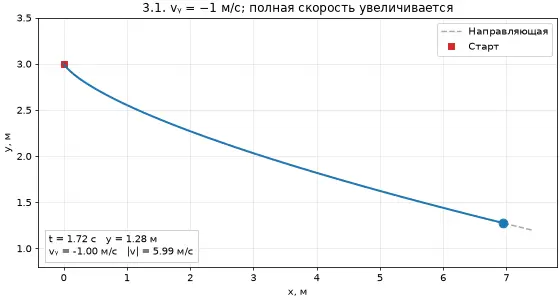
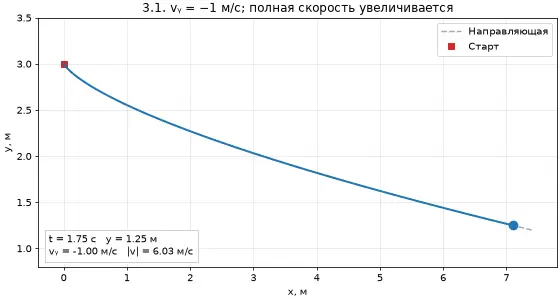
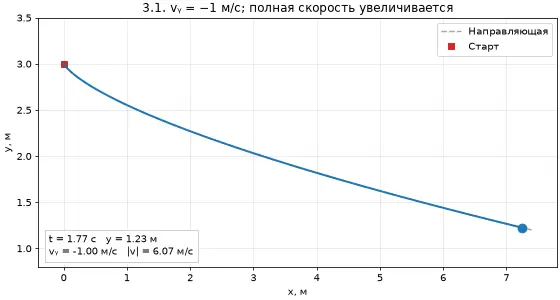
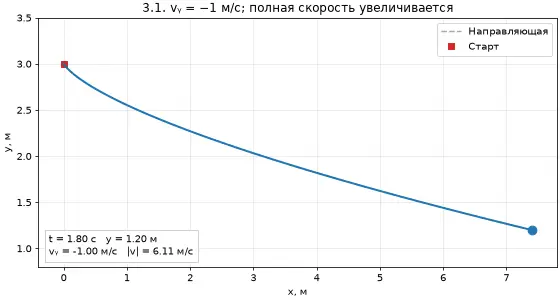

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, HTML
from pathlib import Path
from IPython import get_ipython
from PIL import Image as PILImage
import base64
import io
import re

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 70, 'animation.embed_limit': 100})
Path('figures').mkdir(exist_ok=True)
Path('animations').mkdir(exist_ok=True)


def export_animation(fig, update, name, frames=72):
    # HTML содержит штатные кнопки воспроизведения, паузы и выбора кадра.
    animation = FuncAnimation(fig, update, frames=frames, interval=50,
                              blit=False, repeat=False)
    html = animation.to_jshtml(fps=20, default_mode='once')
    # Компактные кадры сохраняют автономность HTML и уменьшают размер ноутбука.
    def compact_frame(match):
        raw = base64.b64decode(match.group(1).replace('\\', '').replace('\n', ''))
        buffer = io.BytesIO()
        with PILImage.open(io.BytesIO(raw)) as image:
            image.convert('RGB').save(buffer, format='WEBP', quality=72, method=4)
        return 'data:image/webp;base64,'+base64.b64encode(buffer.getvalue()).decode('ascii')
    html = re.sub(r'data:image/png;base64,([A-Za-z0-9+/=\\\n]+)', compact_frame, html)
    Path(f'animations/{name}.html').write_text(
        '<!doctype html><html lang="ru"><meta charset="utf-8">'
        f'<title>{name}</title><body>{html}</body></html>', encoding='utf-8')
    # GIF можно посмотреть прямо в README на GitHub без запуска Python.
    animation.save(f'animations/{name}.gif', writer=PillowWriter(fps=20), dpi=70)
    plt.close(fig)
    display(HTML(html))
    return animation


# 3.1: точное движение с постоянной вертикальной скоростью.
import sympy as sp

g = 9.81
x_symbol, u_symbol, g_symbol = sp.symbols('x u g', positive=True)
y_symbol = -sp.Rational(3, 2)*(u_symbol**2/(3*g_symbol))**sp.Rational(1, 3)*x_symbol**sp.Rational(2, 3)
residual = sp.simplify(sp.diff(y_symbol, x_symbol, 2)
                       - g_symbol/u_symbol**2*sp.diff(y_symbol, x_symbol)**4)
assert residual == 0
print('3.1: подстановка найденной кривой в ОДУ даёт', residual)


def descent(t, u=1.0, w0=1.0, x0=0.0, y0=3.0):
    t = np.asarray(t)
    vx = np.sqrt(w0*w0 + 2*g*u*t)
    x = x0 + (vx**3 - w0**3)/(3*g*u)
    y = y0 - u*t
    return x, y, vx


t = np.linspace(0, 1.8, 600)
cases = [(0.7, 0.8), (1.0, 1.0), (1.4, 1.5)]
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for u, w0 in cases:
    xx, yy, vx = descent(t, u, w0)
    line, = ax.plot(xx, yy, label=f'u={u:g} м/с, w₀={w0:g} м/с')
    ax.plot(xx[0], yy[0], 'o', color=line.get_color())
    energy = (vx**2 + u*u)/2 + g*yy
    assert np.ptp(energy) < 1e-10
ax.annotate('Начальные положения', (0, 3), xytext=(0.8, 2.95),
            arrowprops={'arrowstyle': '->'})
ax.set(xlabel='x, м', ylabel='y, м', title='3.1. Равномерное вертикальное опускание')
ax.grid(alpha=0.3); ax.legend(loc='lower left')
fig.savefig('figures/3_1_descent.png', dpi=170)
plt.show()

u, w0 = 1.0, 1.0
times = np.linspace(0, 1.8, 72)
xx, yy, vx = descent(times, u, w0)
fig, ax = plt.subplots(figsize=(8, 4.3), constrained_layout=True)
ax.plot(xx, yy, '--', color='0.65', label='Направляющая')
ax.plot(xx[0], yy[0], 's', color='#d62728', label='Старт')
trail, = ax.plot([], [], color='#1f77b4', lw=2)
point, = ax.plot([], [], 'o', color='#1f77b4', ms=9)
info = ax.text(0.02, 0.05, '', transform=ax.transAxes,
               bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': '0.8'})
ax.set(xlim=(-0.4, xx[-1]+0.4), ylim=(0.8, 3.5), xlabel='x, м', ylabel='y, м',
       title='3.1. vᵧ = −1 м/с; полная скорость увеличивается')
ax.grid(alpha=0.3); ax.legend(loc='upper right')


def update_31(i):
    point.set_data([xx[i]], [yy[i]])
    trail.set_data(xx[:i+1], yy[:i+1])
    info.set_text(f't = {times[i]:.2f} с   y = {yy[i]:.2f} м\n'
                  f'vᵧ = {-u:.2f} м/с   |v| = {np.hypot(vx[i], u):.2f} м/с')
    return point, trail, info


animation_31 = export_animation(fig, update_31, '3_1_descent')


## 3.2

**Бильярд в прямоугольнике.** Пусть область движения $0\le x\le a$, $0\le y\le b$. Между ударами
$$\ddot x=\ddot y=0,\qquad \mathbf v=(v_x,v_y)=\mathrm{const}.$$
На вертикальной стенке $v_x^+=-v_x^-$, $v_y^+=v_y^-$; на горизонтальной $v_x^+=v_x^-$, $v_y^+=-v_y^-$. Скорость и кинетическая энергия сохраняются. Попадания точно в угол исключаем: нормаль там не определена, и обычный закон зеркального отражения не задаёт продолжение однозначно.

**Метод развёртки.** Вместо отражения шара зеркально отражаем прямоугольник. В развёрнутой плоскости
$$X(t)=x_0+v_xt,\qquad Y(t)=y_0+v_yt.$$
Определим треугольную волну
$$F_L(z)=L-\left|(z\bmod 2L)-L\right|.$$
Тогда точное решение исходной задачи:
$$\boxed{x(t)=F_a(X(t)),\qquad y(t)=F_b(Y(t))}.$$
Производная $F_L$ равна $+1$ или $-1$ между точками отражения, поэтому эта формула автоматически реализует упругие удары без численного накопления ошибок.

**Тор и периодичность.** Склейка противоположных сторон развёрнутого прямоугольника $[0,2a)\times[0,2b)$ даёт плоский тор. На нём
$$q_1=X\bmod2a,\qquad q_2=Y\bmod2b.$$
Для возврата и положения, и скорости нужны целые $m,n$ и $T>0$:
$$v_xT=2am,\qquad v_yT=2bn.$$
При $v_xv_y\ne0$ траектория периодична тогда и только тогда, когда
$$\boxed{\alpha=\frac{av_y}{bv_x}=\frac nm\in\mathbb Q}.$$
Если $\alpha=p/q$ в несократимом виде, $v_x>0$, $q>0$, то
$$T=\frac{2aq}{v_x};$$
для произвольного знака $v_x$ используем его модуль. При $v_x=0$ или $v_y=0$ получаются вертикальные или горизонтальные периодические движения, если они не проходят через углы.

При иррациональном $\alpha$ прямолинейный поток плотно и равномерно заполняет тор: его временные средние для непрерывных функций совпадают с пространственными. Складка тора даёт плотную траекторию в прямоугольнике. Это эргодичность **при фиксированном иррациональном направлении** относительно равномерной меры на соответствующем торе. Весь прямоугольный бильярд на полной энергетической поверхности не эргодичен: направление с точностью до отражений является дополнительным интегралом. Конечный рисунок показывает только начальный участок плотной траектории, а не доказательство плотности.

Для изображения тора в $\mathbb R^3$ используем
$$\phi=\pi X/a,\quad\psi=\pi Y/b,$$
$$\mathbf r=((R+r\cos\psi)\cos\phi,\ (R+r\cos\psi)\sin\phi,\ r\sin\psi),\quad R>r>0.$$
Это визуальная модель склейки: физическое движение происходит на плоском торе, а не по геодезическим изображённой поверхности вращения.

**Гамильтонова формулировка.** Внутри области
$$H=\frac{p_x^2+p_y^2}{2m_0},\qquad
\dot x=\frac{p_x}{m_0},\quad\dot y=\frac{p_y}{m_0},\quad\dot p_x=\dot p_y=0.$$
На стенках меняется знак нормального импульса. Можно рассматривать предел бесконечно высоких потенциальных стенок. В развёртке это свободная гамильтонова система на плоском торе; сохраняются $H$, $p_x$, $p_y$. В исходном бильярде сохраняются $p_x^2,p_y^2$, поэтому система интегрируема.

В примерах $a=3$, $b=2$, $(x_0,y_0)=(0.47,0.63)$, $v_x=1$, $v_y=(b/a)\alpha$. Сравниваются $\alpha=1/2$ (период $12$ с) и $\alpha=\sqrt2$. Статическая развёртка показывает несколько отражений, а анимация одновременно показывает прямоугольник, развёртку и тор для обоих направлений.


3.2: α = 1/2, период возврата положения и скорости T = 12 с.
α = √2: непериодическая плотная траектория при фиксированном направлении.


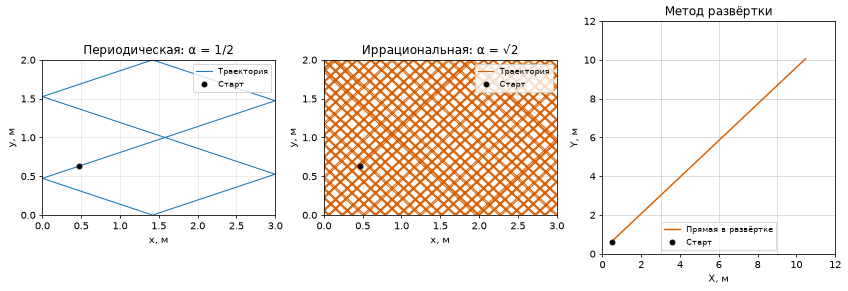


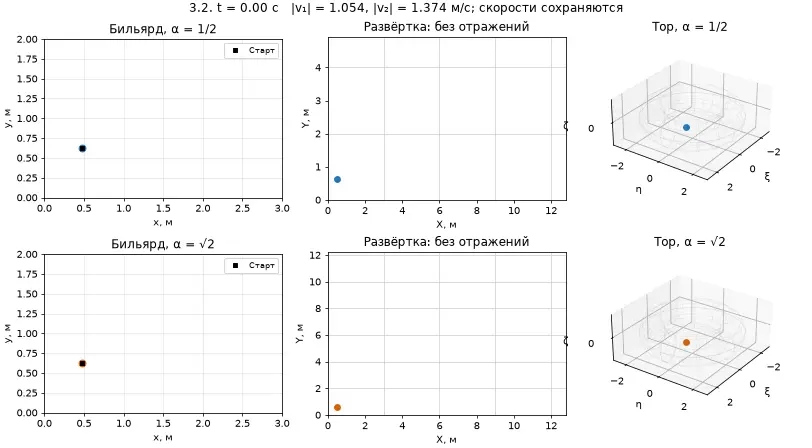
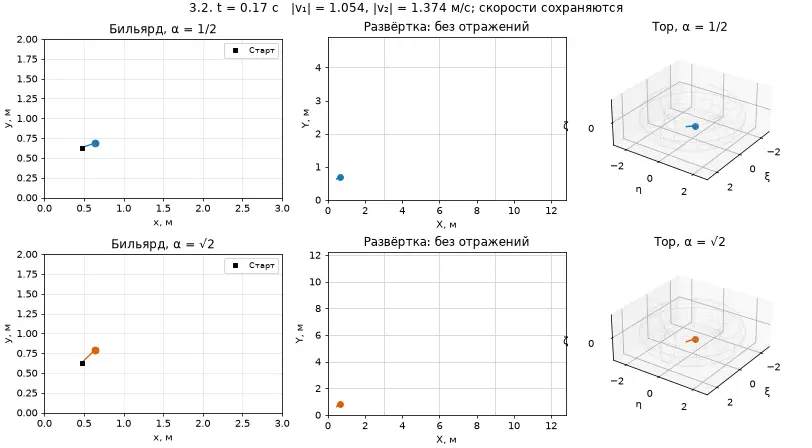
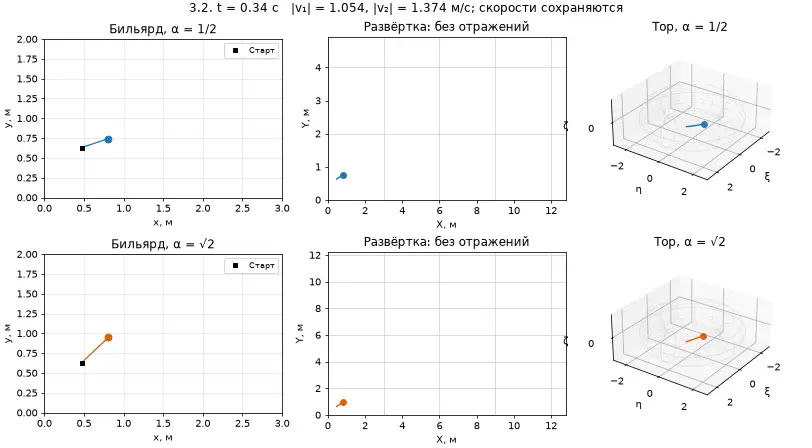
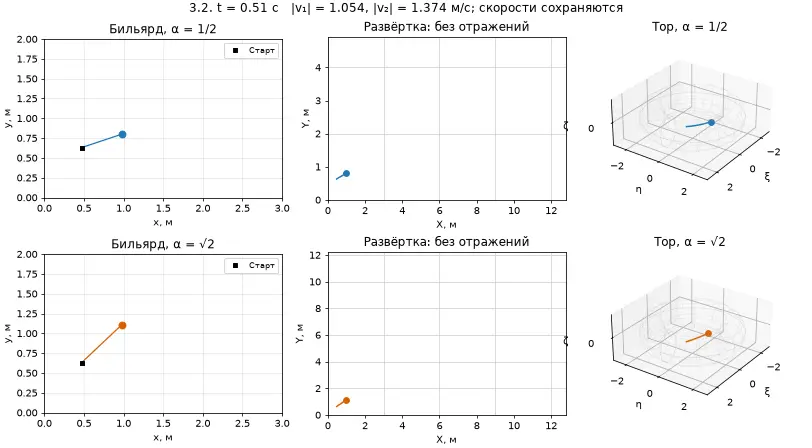
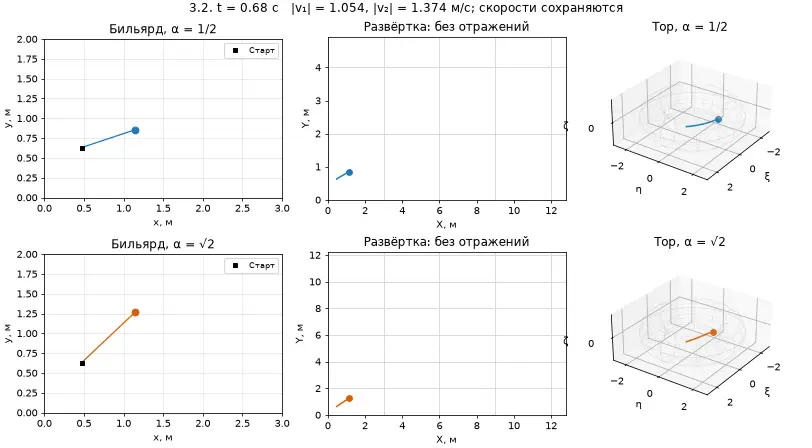
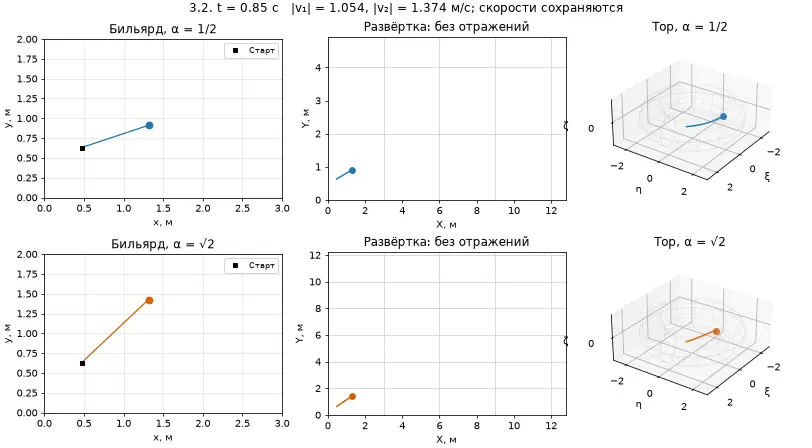
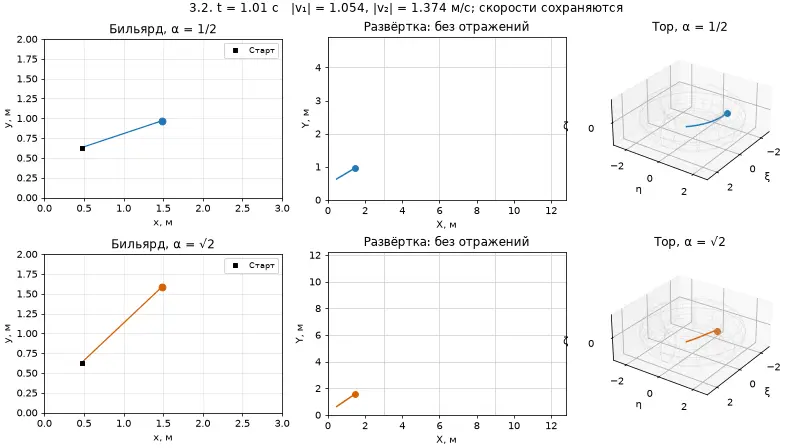
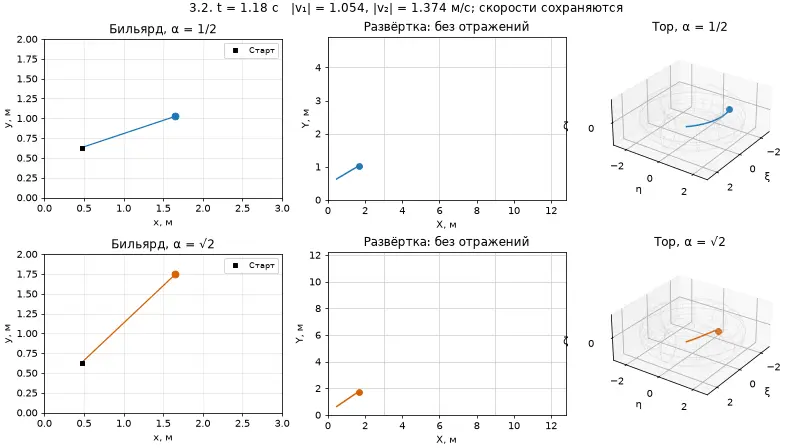
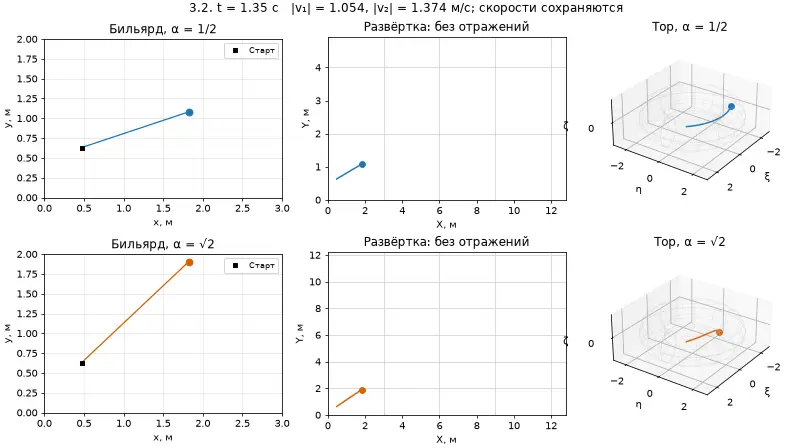
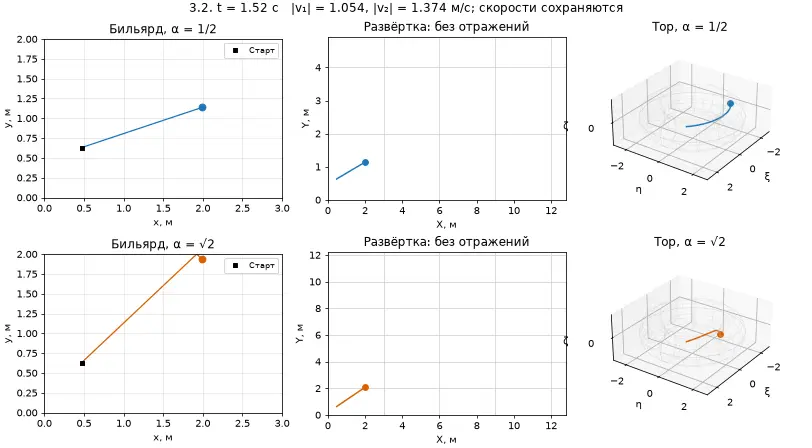
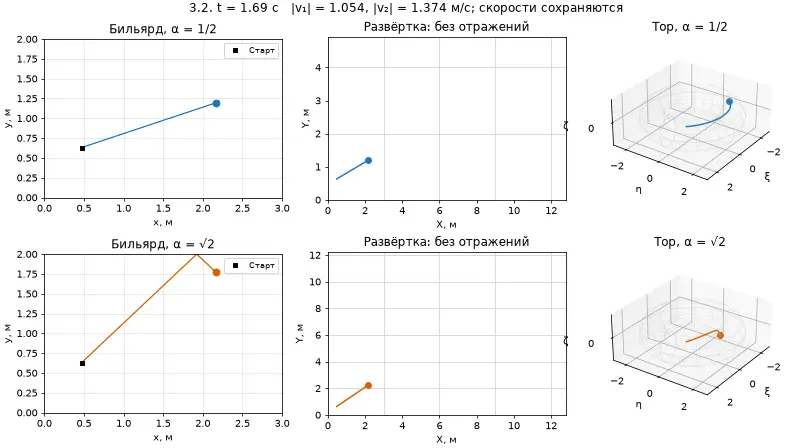
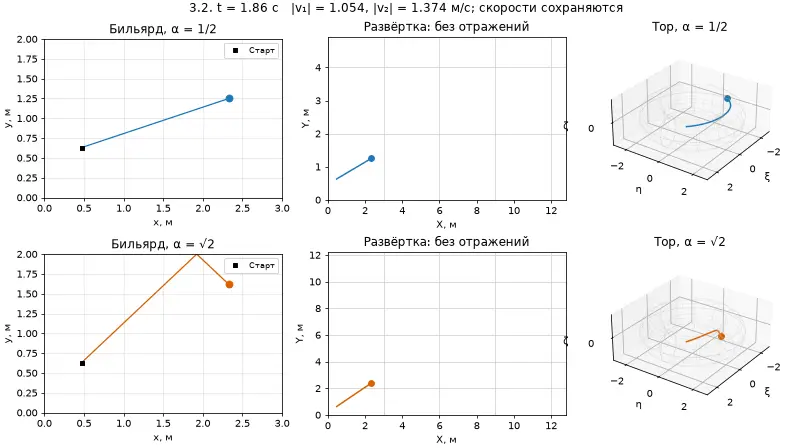
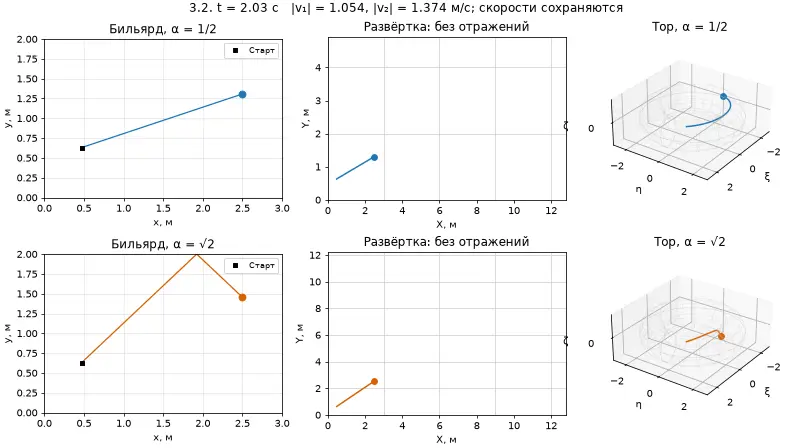
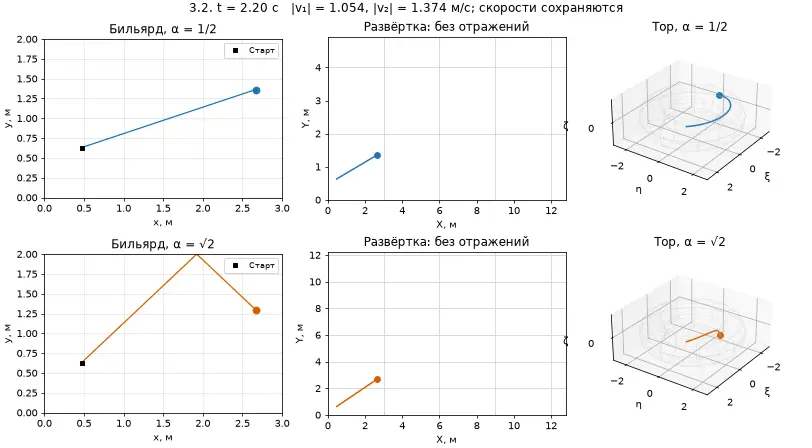
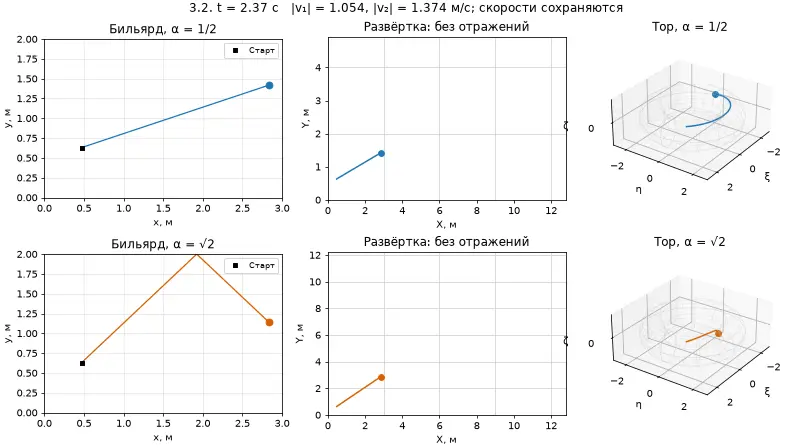
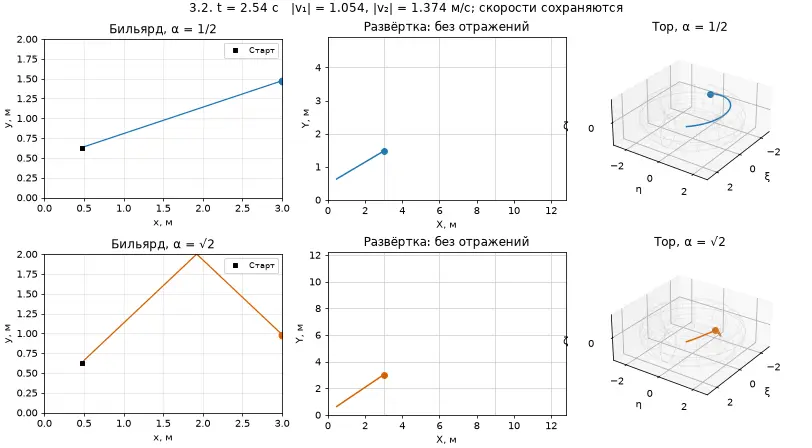
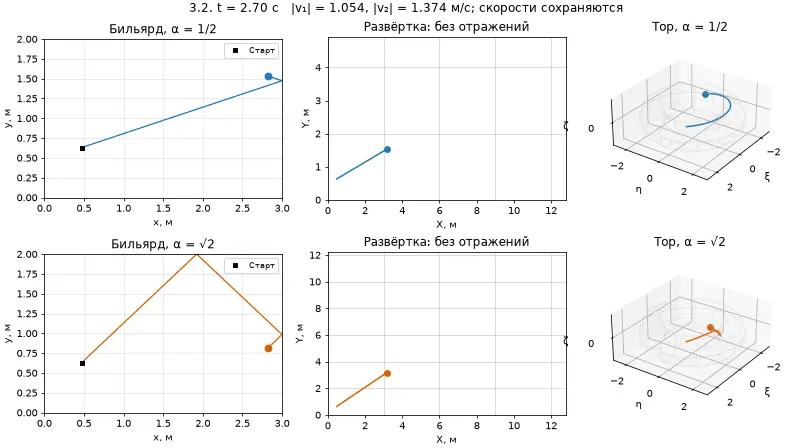
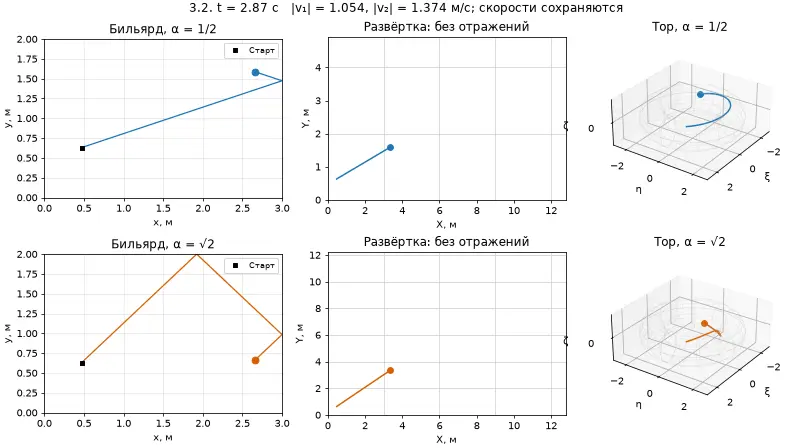
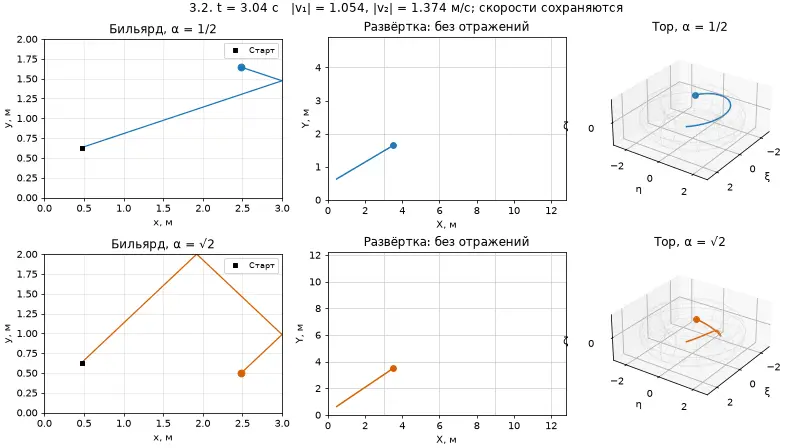
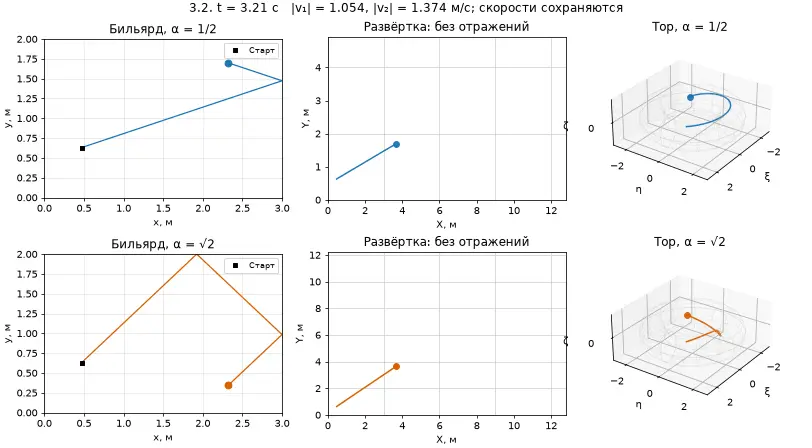
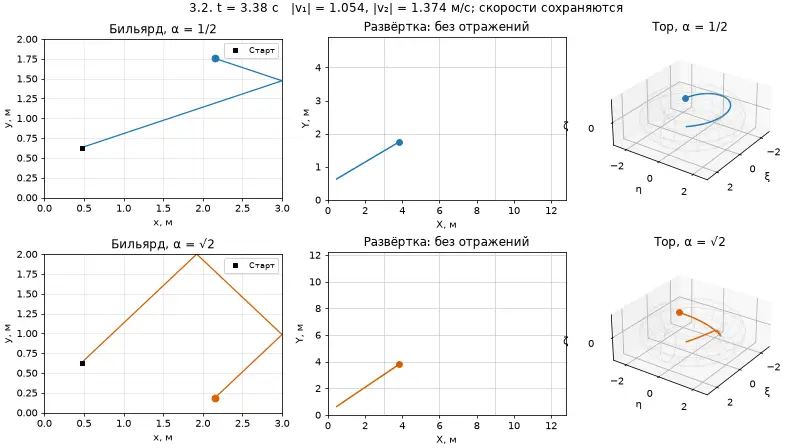
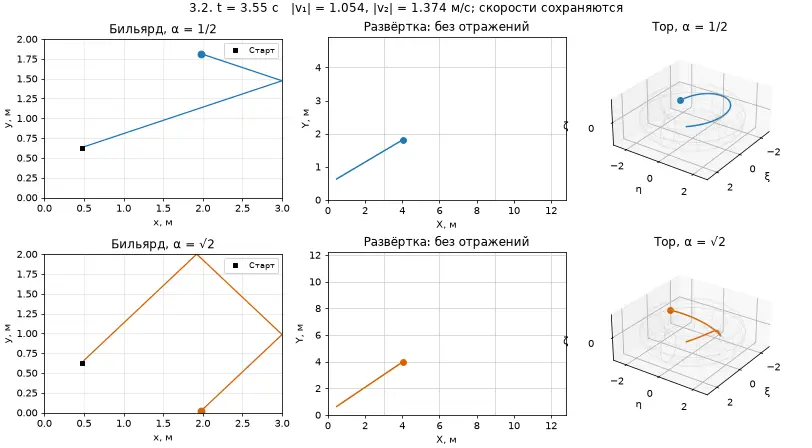
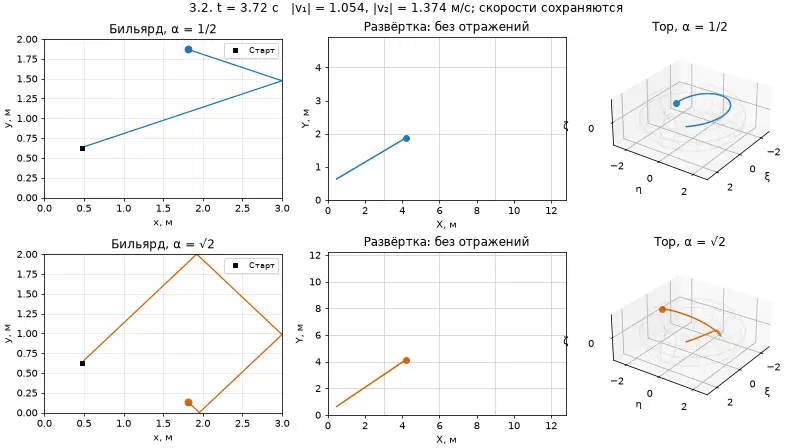
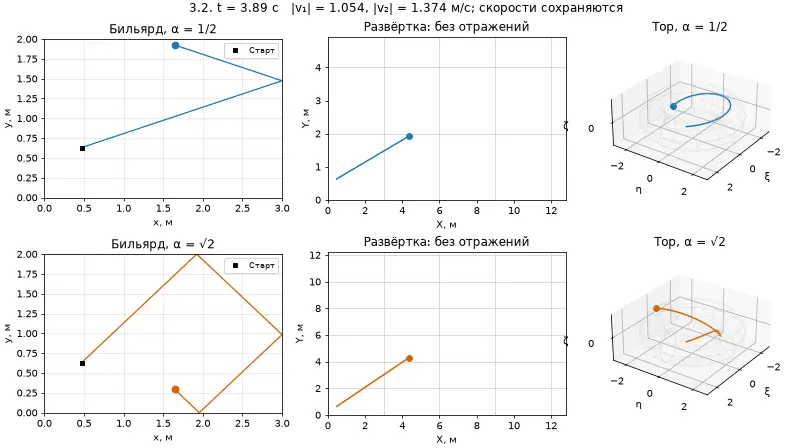
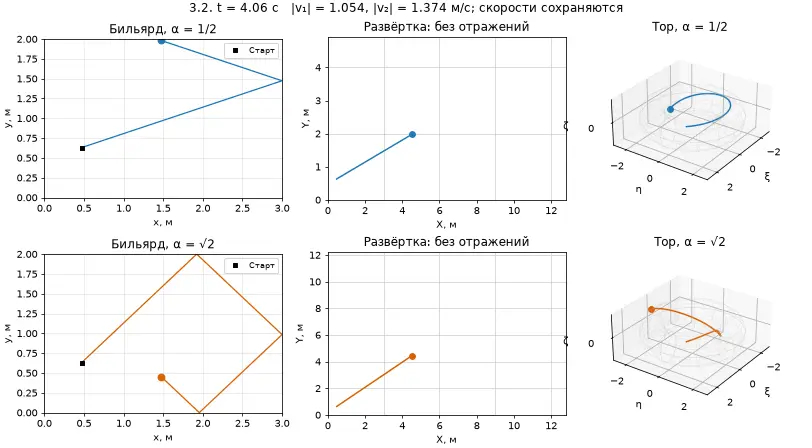
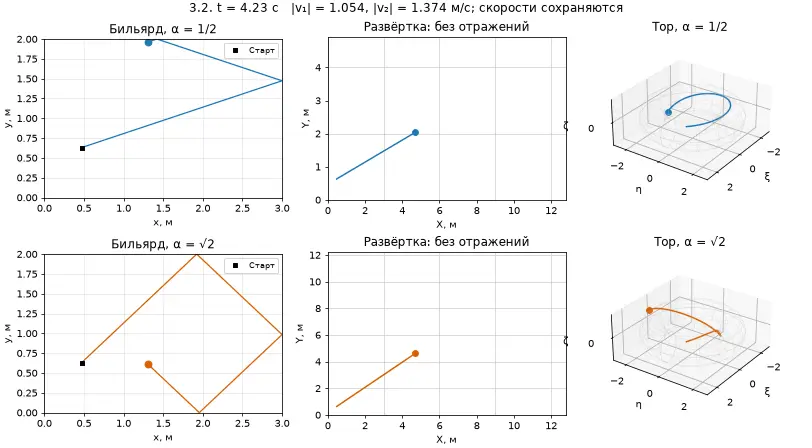
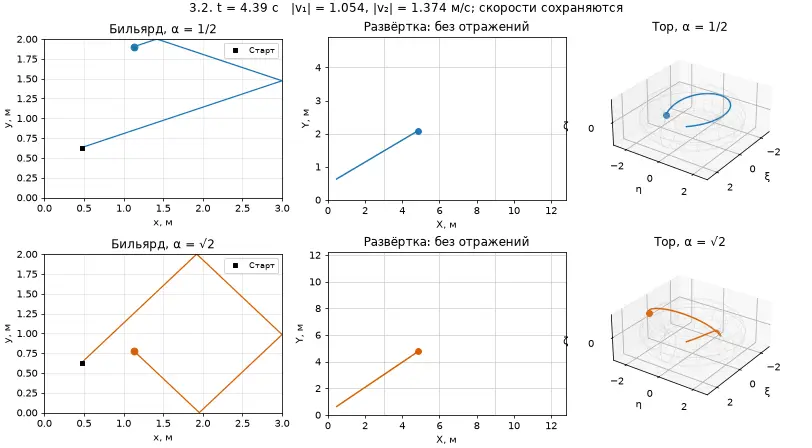
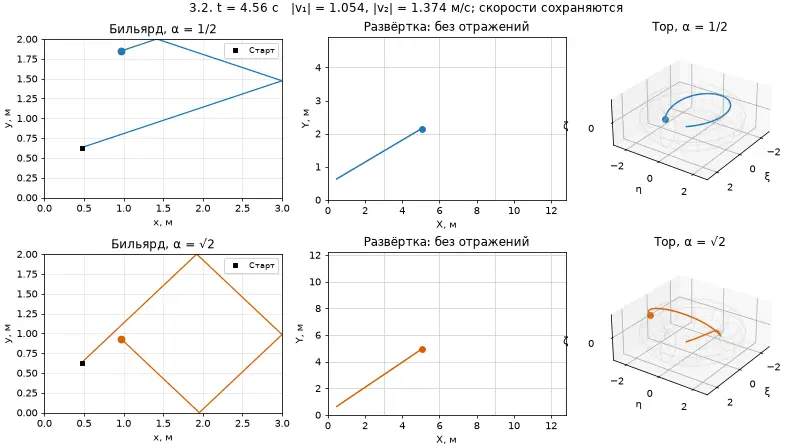
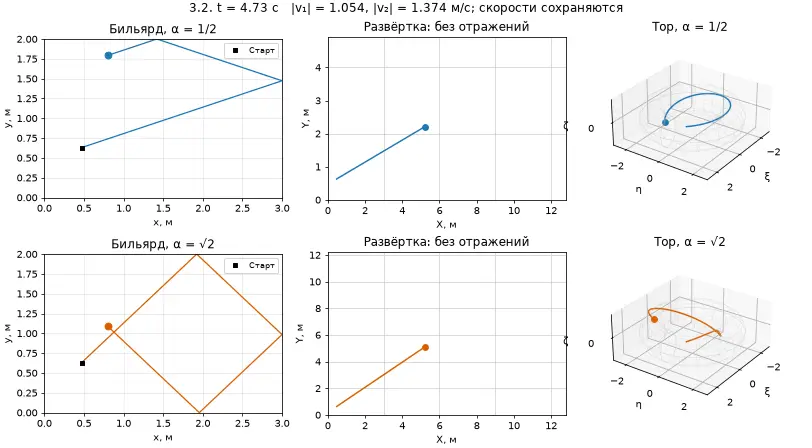
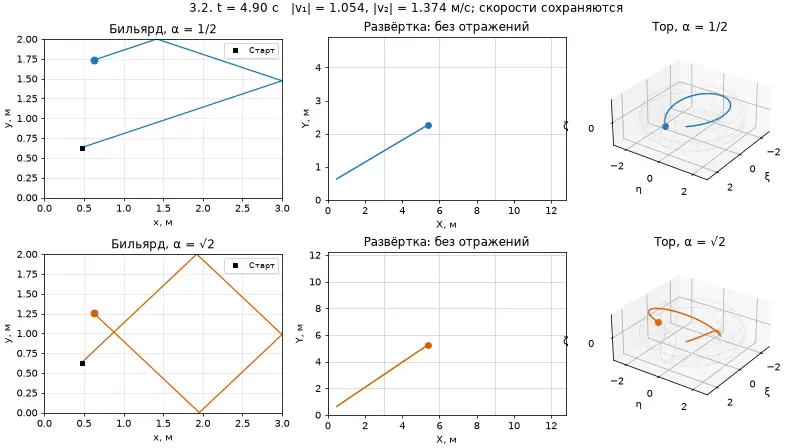
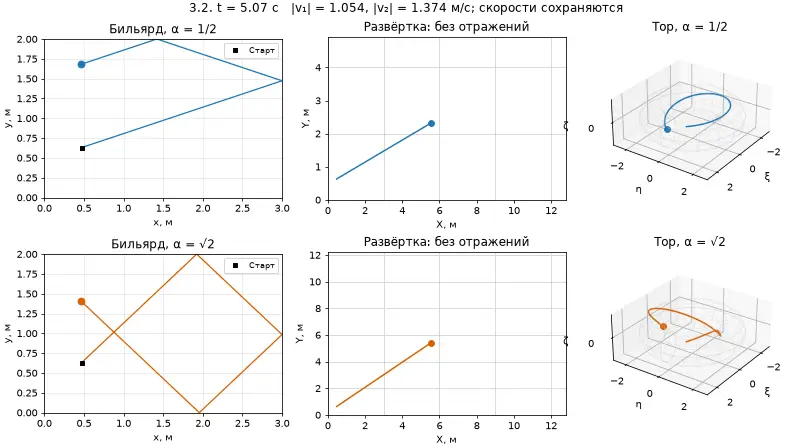
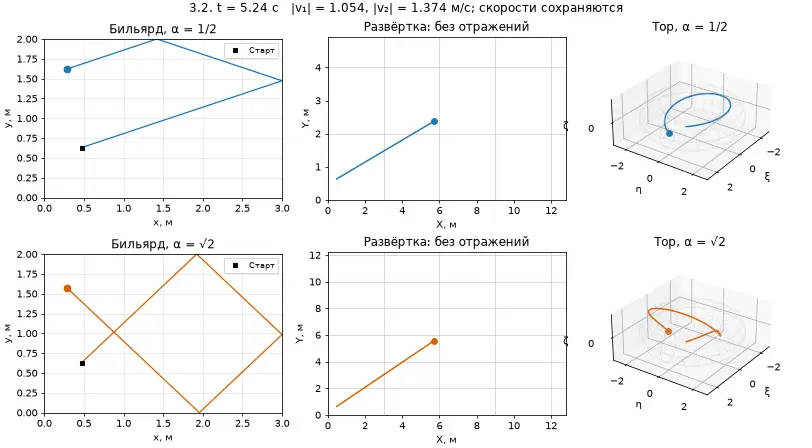
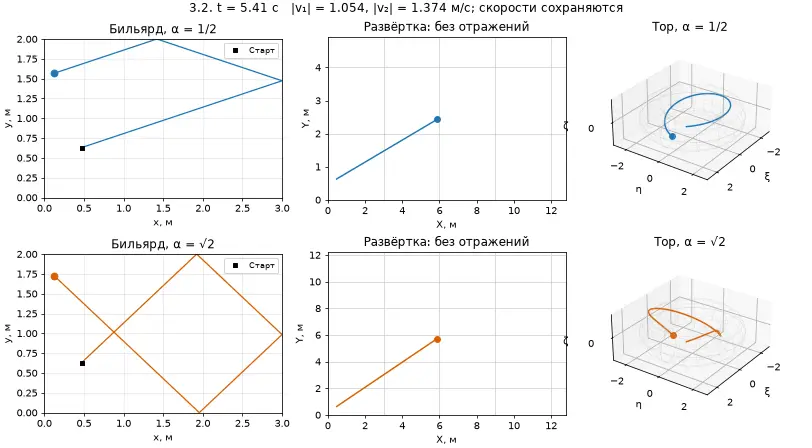
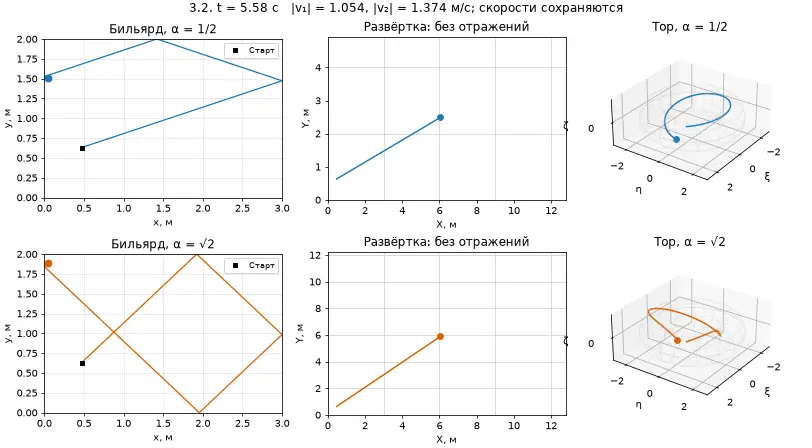
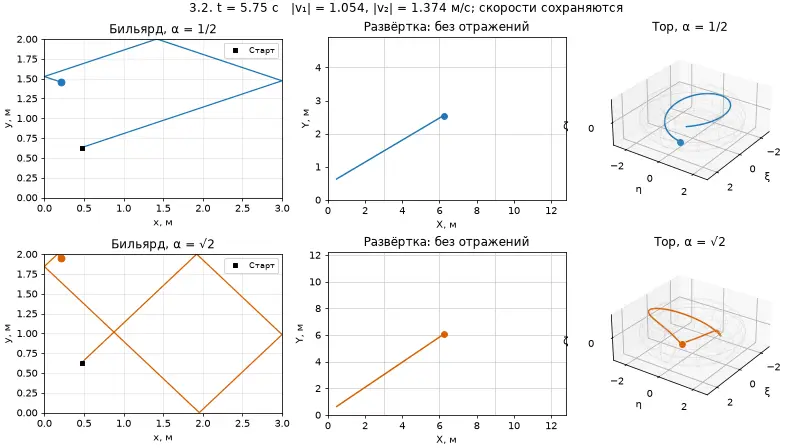
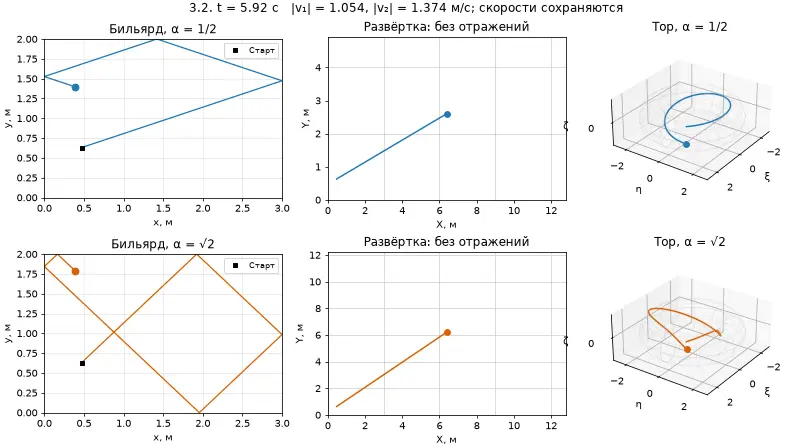
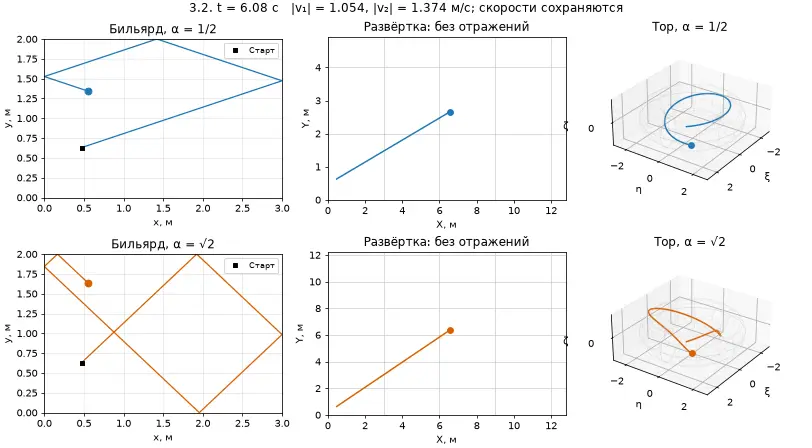
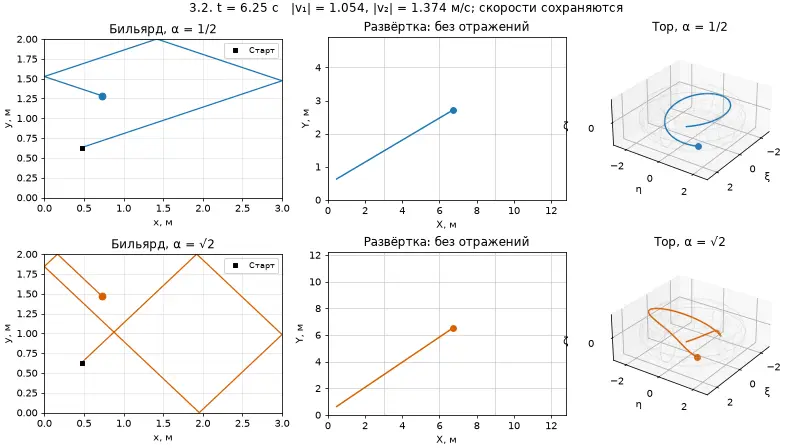
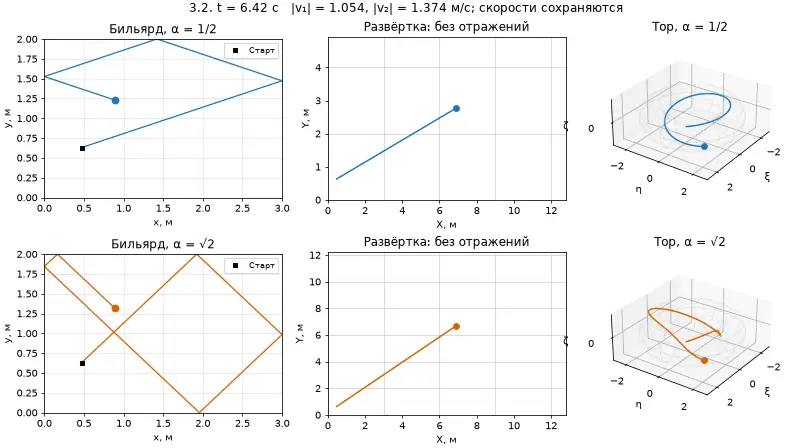
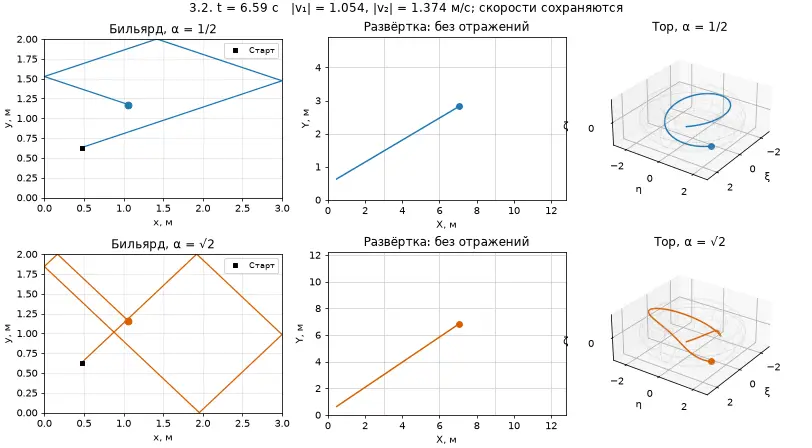
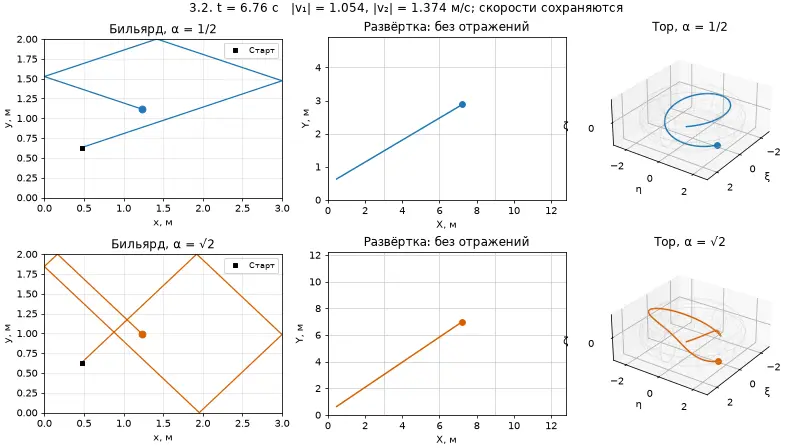
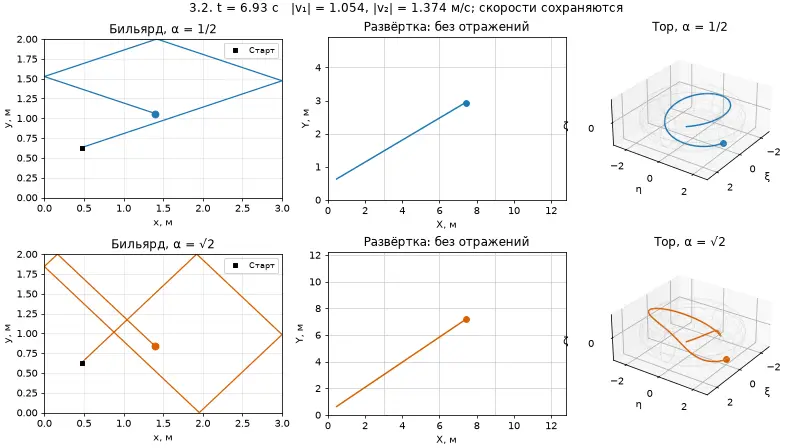
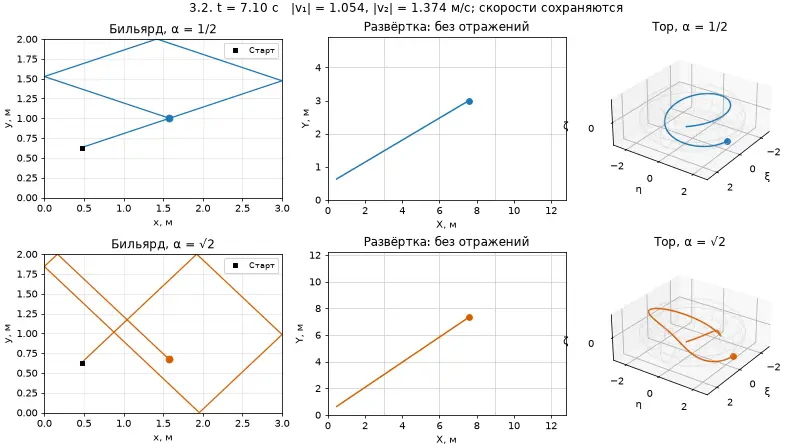
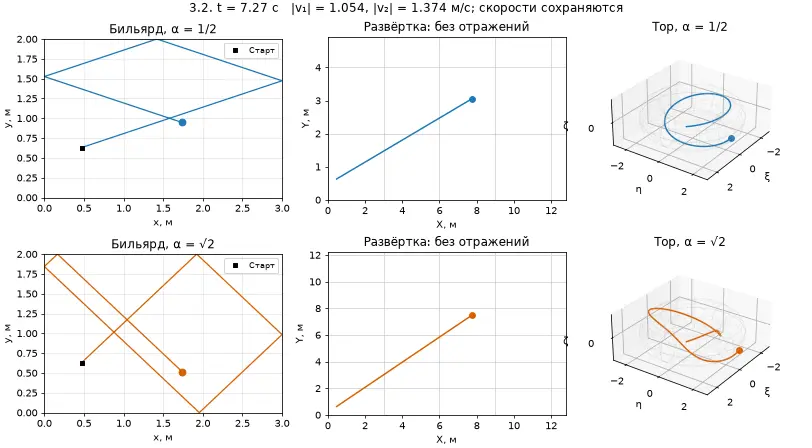
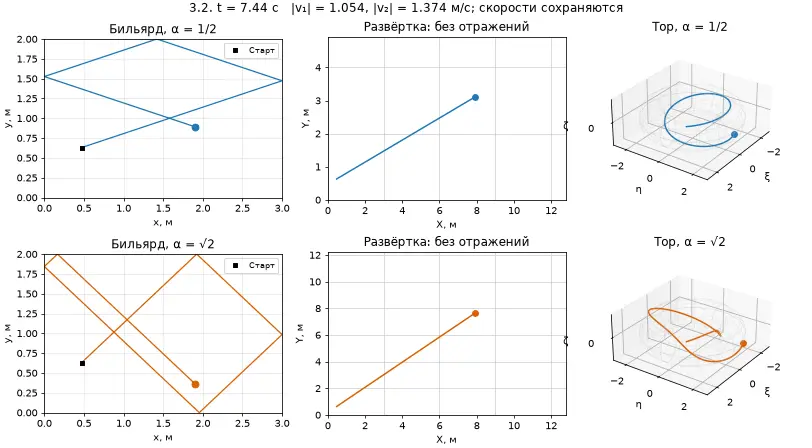
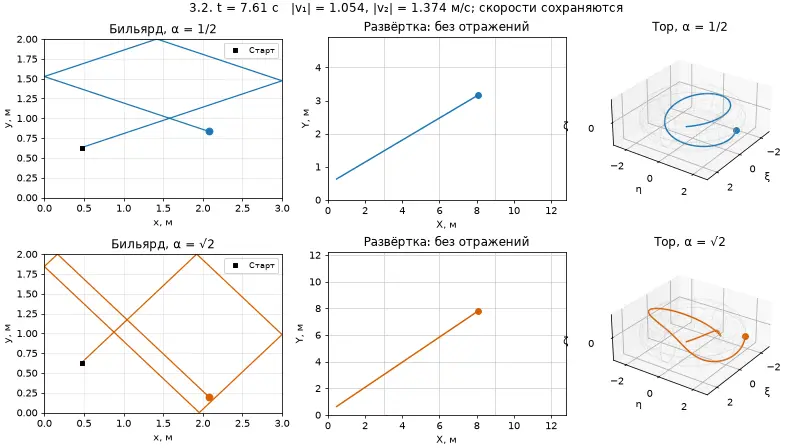
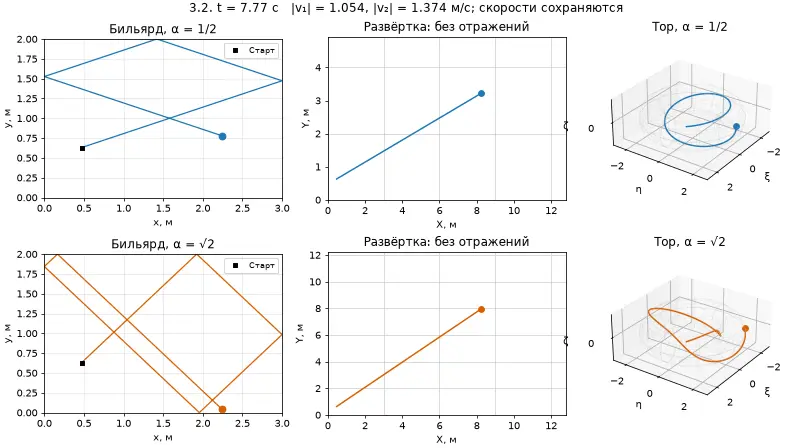
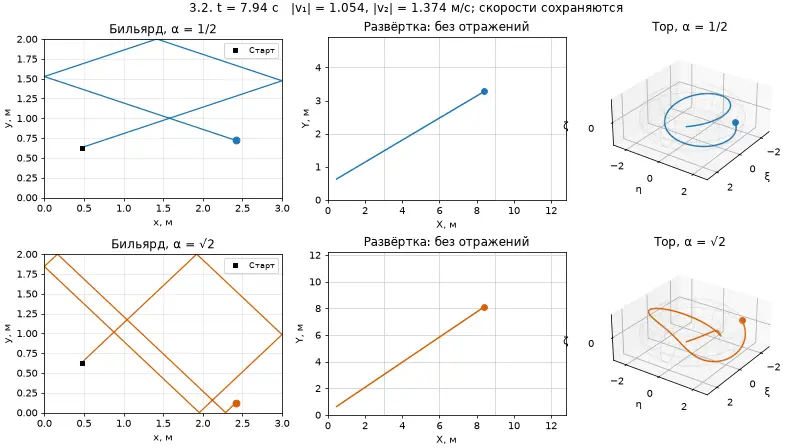
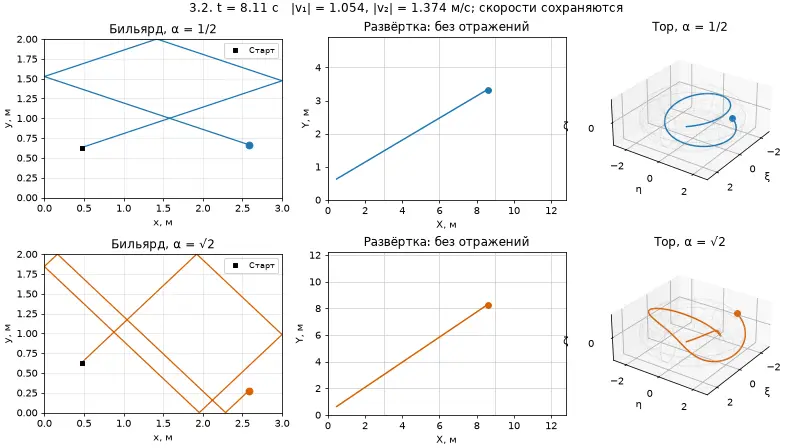
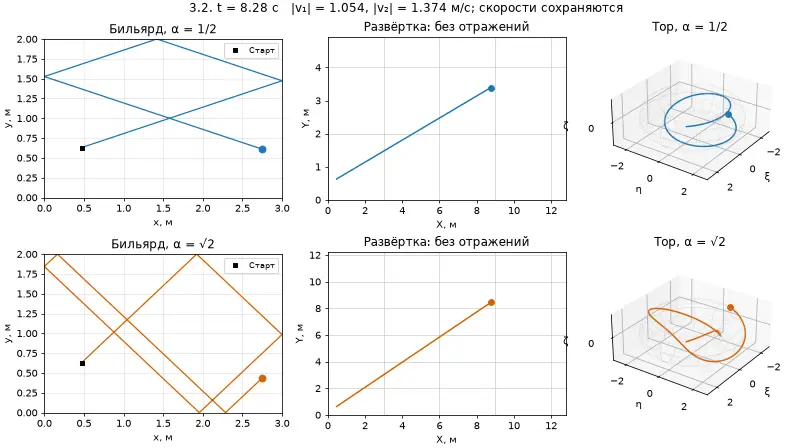
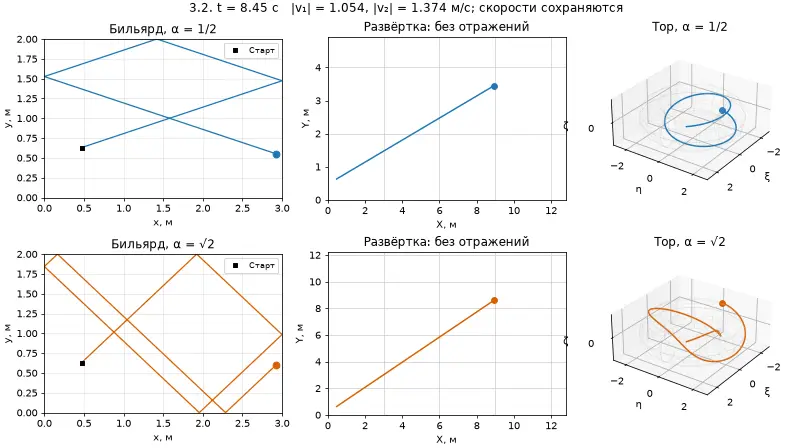
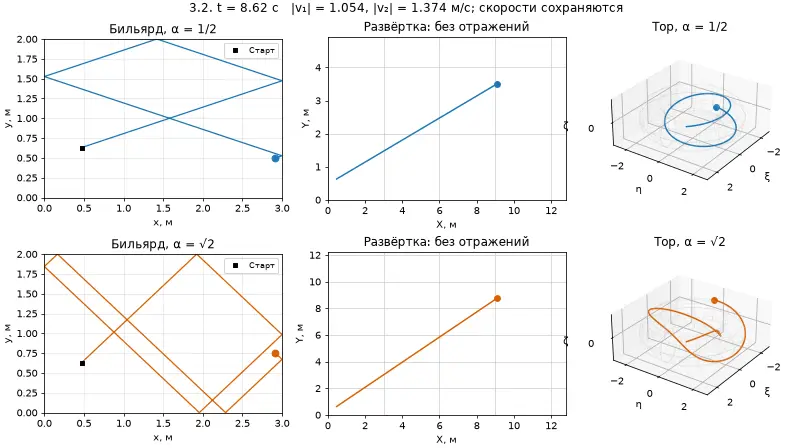
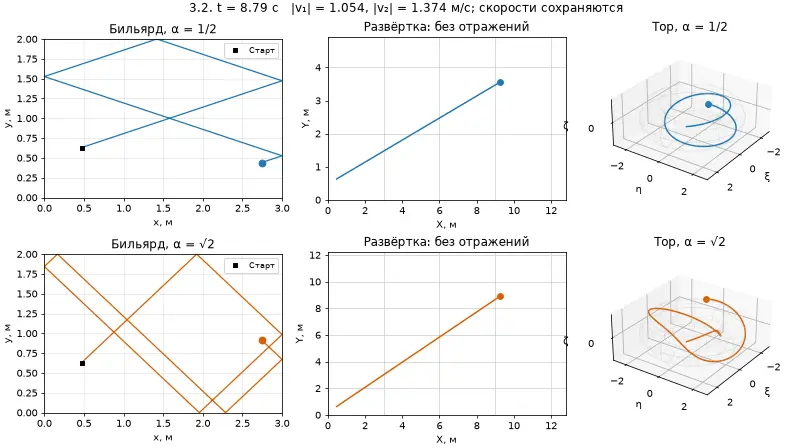
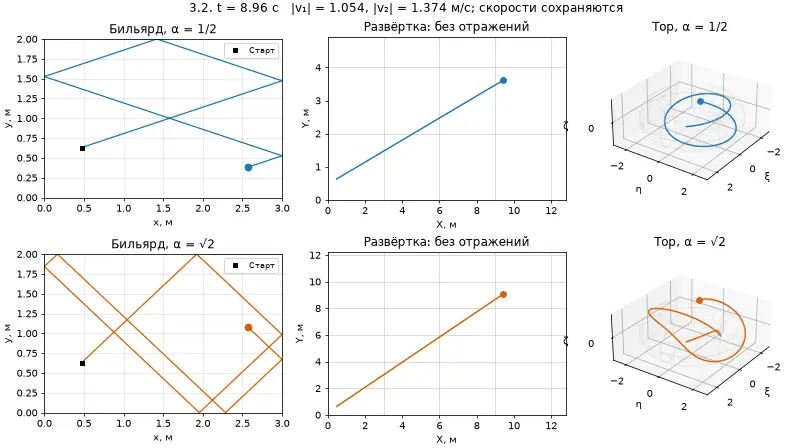
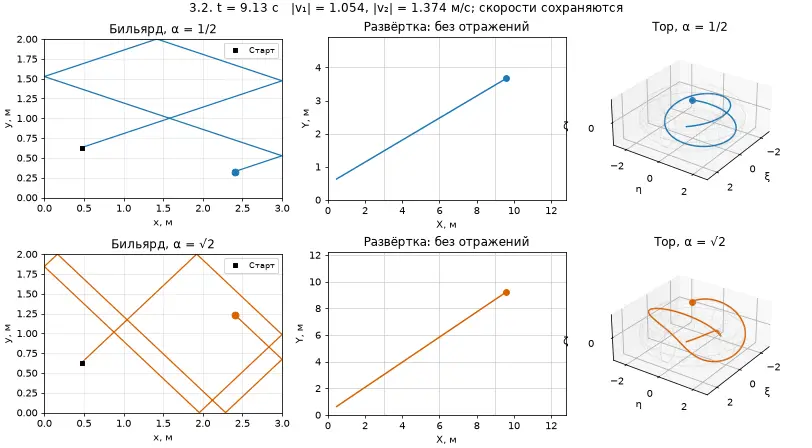
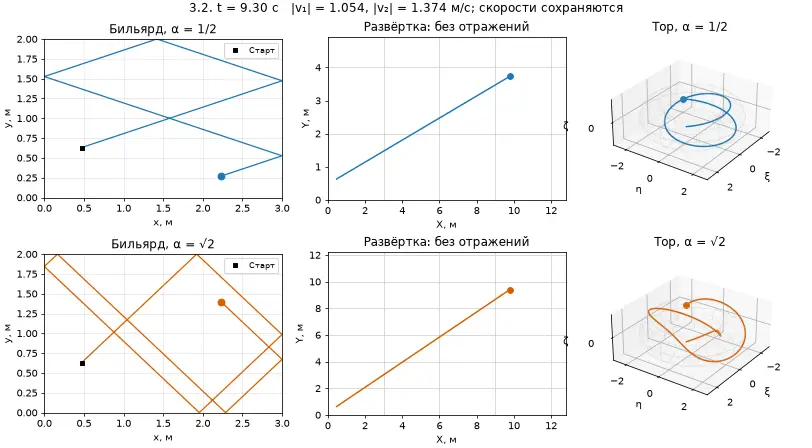
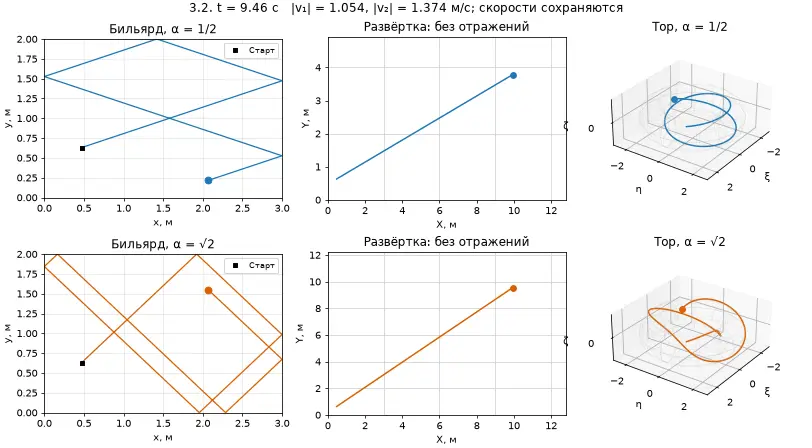
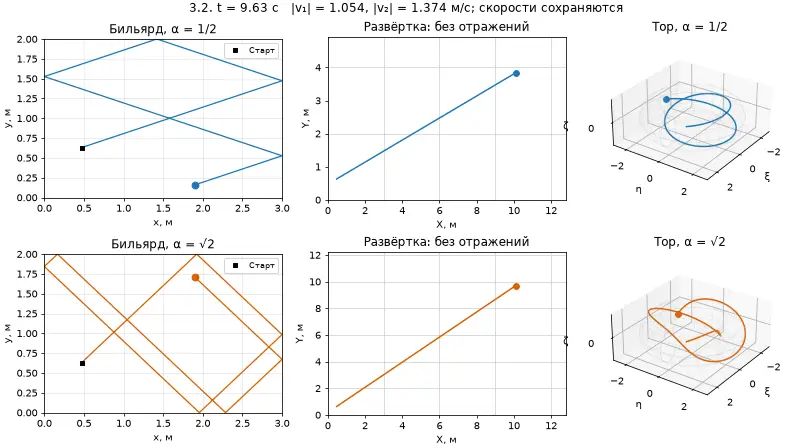
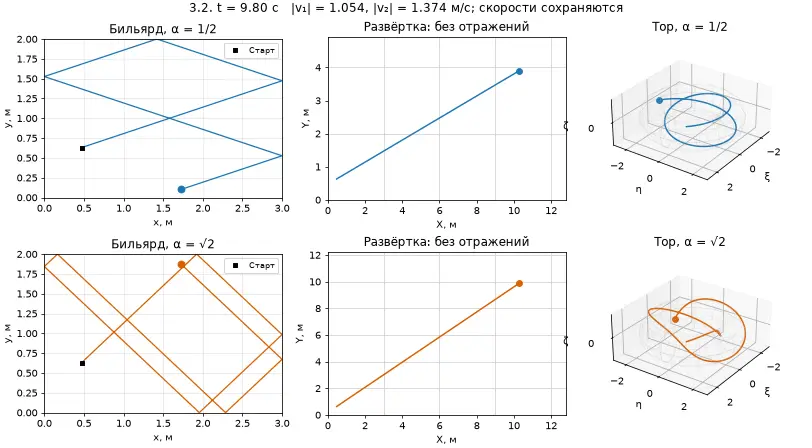
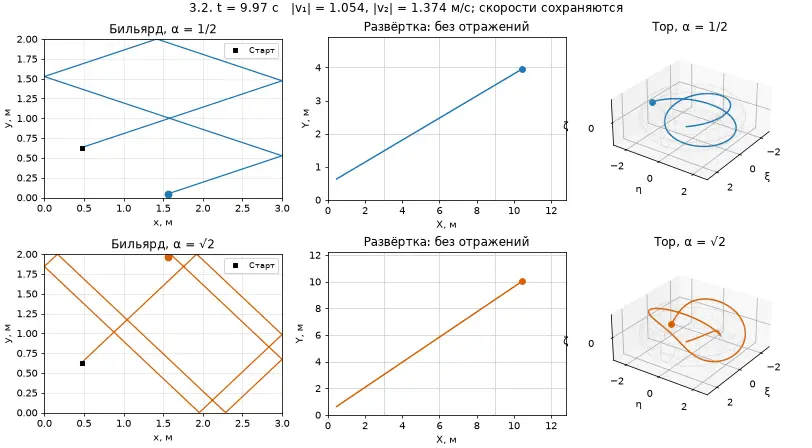
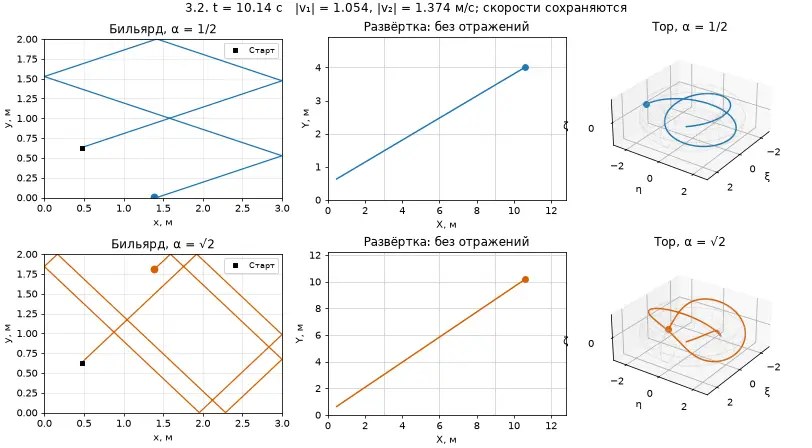
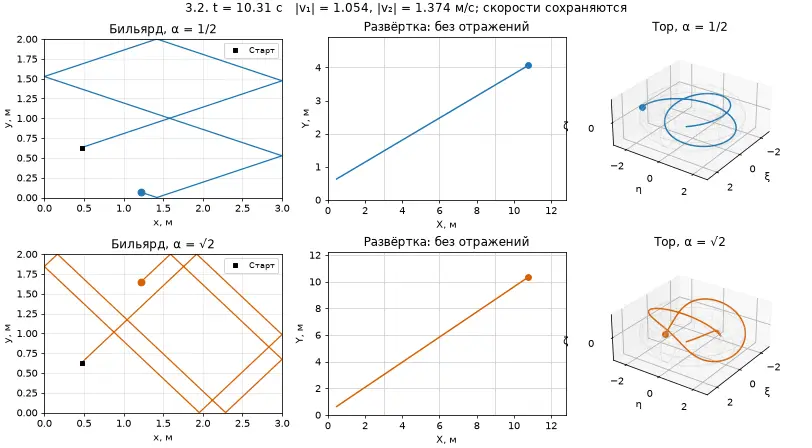
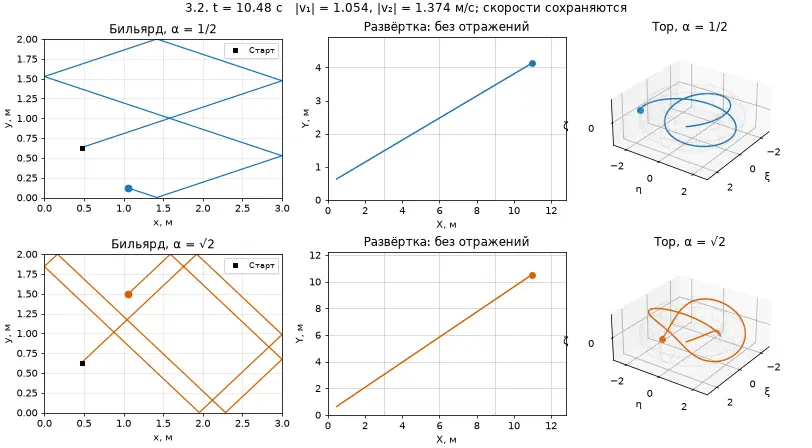
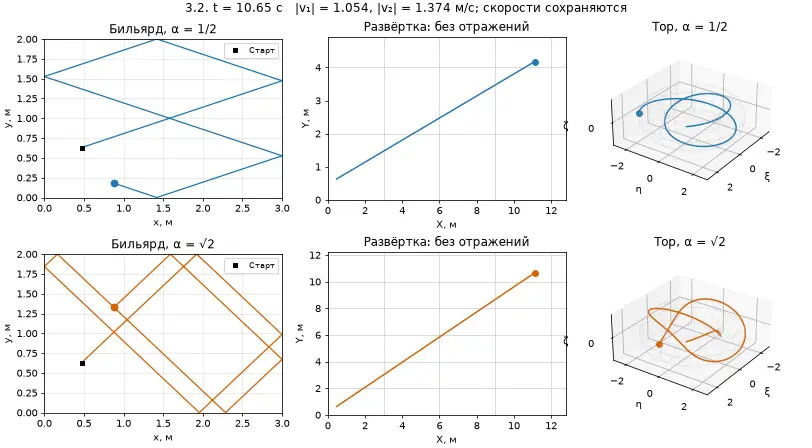
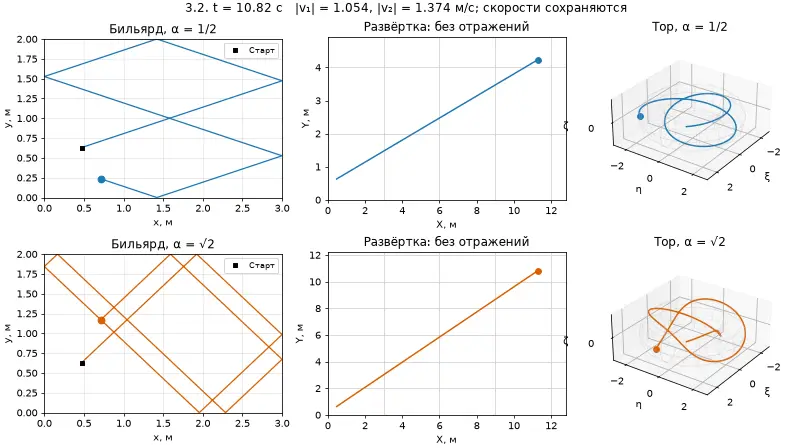
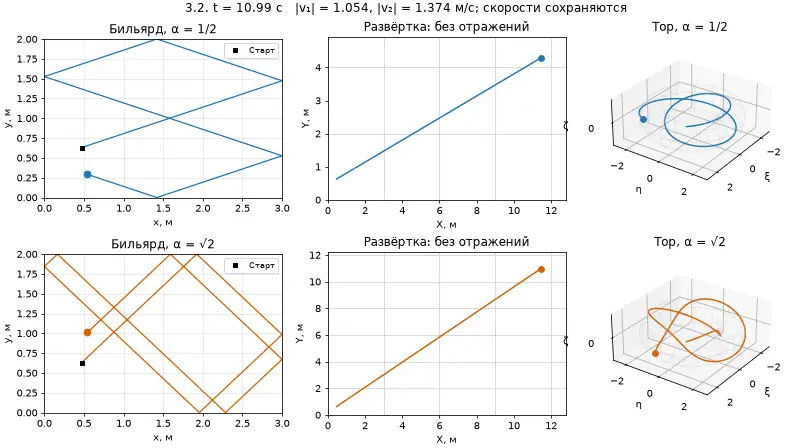
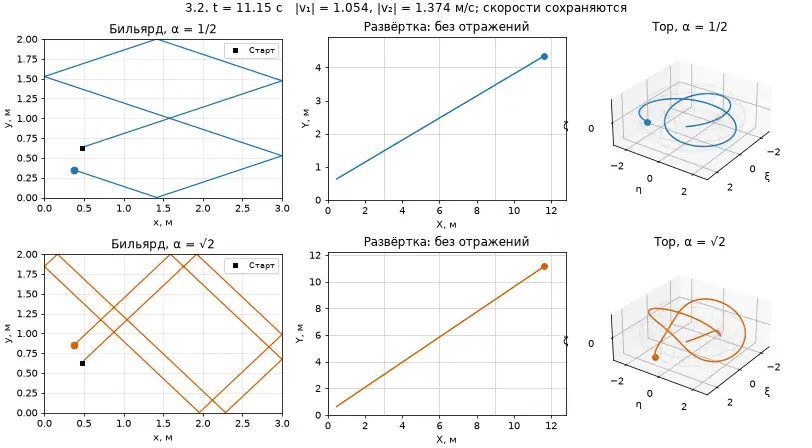
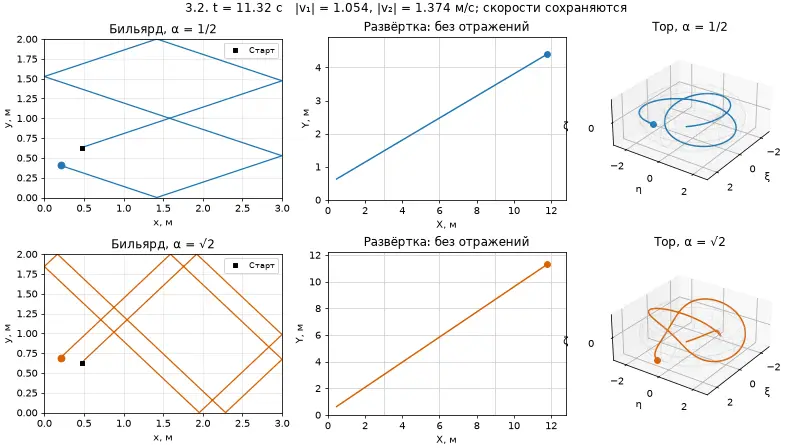
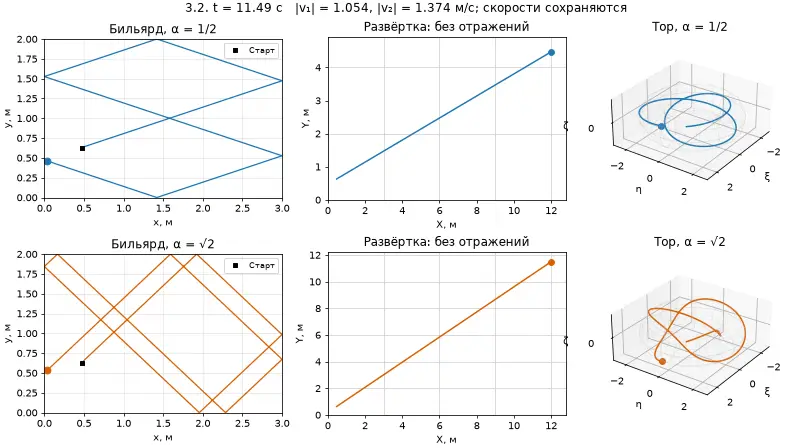
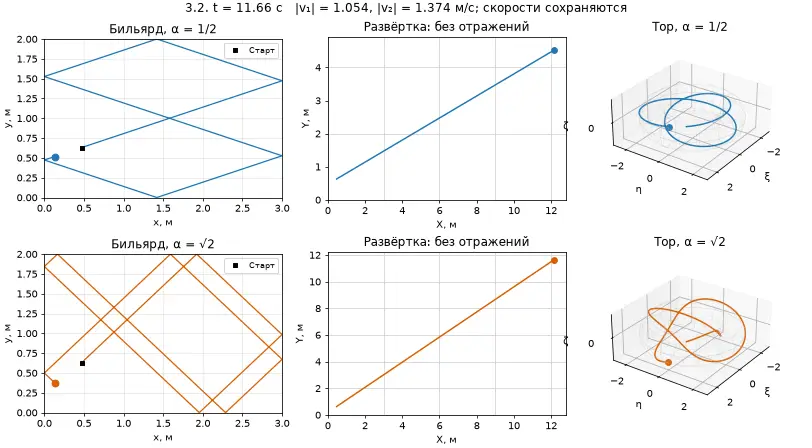
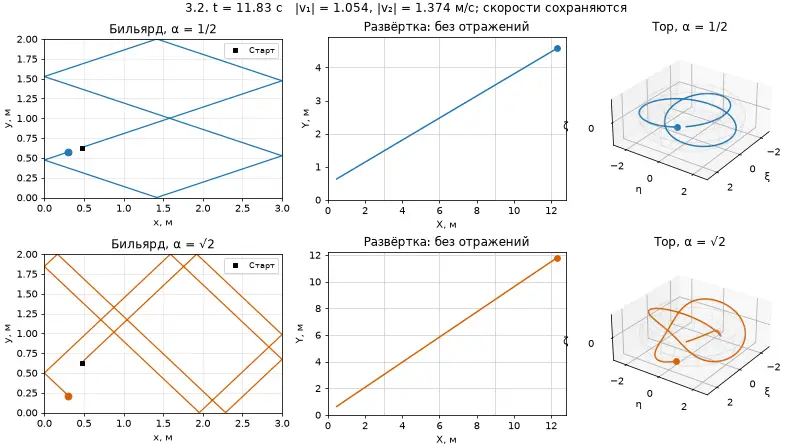
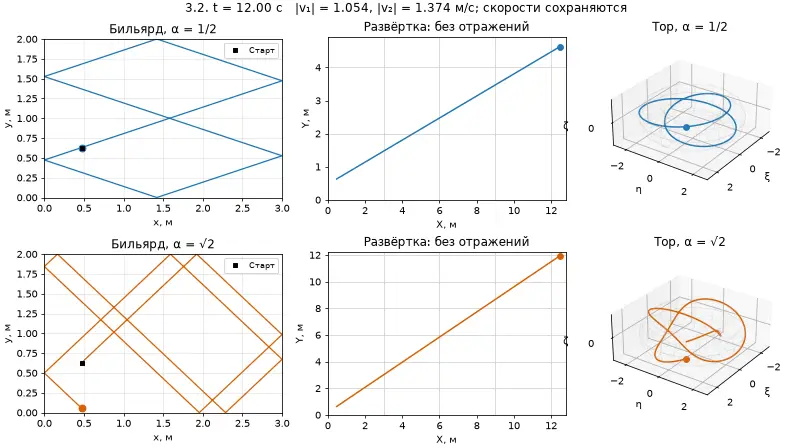

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, HTML
from pathlib import Path
from IPython import get_ipython
from PIL import Image as PILImage
import base64
import io
import re

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 70, 'animation.embed_limit': 100})
Path('figures').mkdir(exist_ok=True)
Path('animations').mkdir(exist_ok=True)


def export_animation(fig, update, name, frames=72):
    # HTML содержит штатные кнопки воспроизведения, паузы и выбора кадра.
    animation = FuncAnimation(fig, update, frames=frames, interval=50,
                              blit=False, repeat=False)
    html = animation.to_jshtml(fps=20, default_mode='once')
    # Компактные кадры сохраняют автономность HTML и уменьшают размер ноутбука.
    def compact_frame(match):
        raw = base64.b64decode(match.group(1).replace('\\', '').replace('\n', ''))
        buffer = io.BytesIO()
        with PILImage.open(io.BytesIO(raw)) as image:
            image.convert('RGB').save(buffer, format='WEBP', quality=72, method=4)
        return 'data:image/webp;base64,'+base64.b64encode(buffer.getvalue()).decode('ascii')
    html = re.sub(r'data:image/png;base64,([A-Za-z0-9+/=\\\n]+)', compact_frame, html)
    Path(f'animations/{name}.html').write_text(
        '<!doctype html><html lang="ru"><meta charset="utf-8">'
        f'<title>{name}</title><body>{html}</body></html>', encoding='utf-8')
    # GIF можно посмотреть прямо в README на GitHub без запуска Python.
    animation.save(f'animations/{name}.gif', writer=PillowWriter(fps=20), dpi=70)
    plt.close(fig)
    display(HTML(html))
    return animation


# 3.2: точная развёртка; узлы траекторий включают все моменты ударов.
a, b = 3.0, 2.0
x0, y0, vx = 0.47, 0.63, 1.0
alphas = [0.5, np.sqrt(2)]
colors = ['#1f77b4', '#d95f02']


def fold(z, length):
    return length - np.abs(np.mod(z, 2*length) - length)


def billiard(t, alpha):
    t = np.asarray(t)
    X, Y = x0 + vx*t, y0 + (b/a)*alpha*vx*t
    return fold(X, a), fold(Y, b), X, Y


def collision_times(stop, alpha):
    # Два положительных компонента скорости в выбранных примерах.
    result = [0.0, float(stop)]
    for z0, speed, length in [(x0, vx, a), (y0, (b/a)*alpha*vx, b)]:
        walls = np.arange(1, int(np.floor((z0 + speed*stop)/length))+1)*length
        result.extend(((walls-z0)/speed).tolist())
    return np.unique(np.array(result))


def torus(t, alpha):
    _, _, X, Y = billiard(t, alpha)
    phi, psi = np.pi*X/a, np.pi*Y/b
    return ((2+0.65*np.cos(psi))*np.cos(phi),
            (2+0.65*np.cos(psi))*np.sin(phi), 0.65*np.sin(psi))


period = 12.0
xp, yp, _, _ = billiard([0, period], 0.5)
assert np.allclose([xp[0], yp[0]], [xp[1], yp[1]])
assert np.allclose(np.array([vx, (b/a)*0.5*vx])*period, [4*a, 2*b])
print('3.2: α = 1/2, период возврата положения и скорости T = 12 с.')
print('α = √2: непериодическая плотная траектория при фиксированном направлении.')

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, alpha, stop, color, title in zip(
        axes[:2], alphas, [period, 180], colors,
        ['Периодическая: α = 1/2', 'Иррациональная: α = √2']):
    ts = collision_times(stop, alpha)
    x, y, _, _ = billiard(ts, alpha)
    ax.plot(x, y, lw=1.1, color=color, label='Траектория')
    ax.plot(x0, y0, 'ko', ms=5, label='Старт')
    ax.set(xlim=(0, a), ylim=(0, b), xlabel='x, м', ylabel='y, м', title=title)
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax = axes[2]
tt = np.linspace(0, 10, 500)
_, _, X, Y = billiard(tt, np.sqrt(2))
for xc in np.arange(0, 13, a): ax.axvline(xc, color='0.8', lw=0.7)
for yc in np.arange(0, 13, b): ax.axhline(yc, color='0.8', lw=0.7)
ax.plot(X, Y, color=colors[1], label='Прямая в развёртке')
ax.plot(x0, y0, 'ko', ms=5, label='Старт')
ax.set(xlim=(0, 12), ylim=(0, 12), xlabel='X, м', ylabel='Y, м', title='Метод развёртки')
ax.set_aspect('equal'); ax.legend(fontsize=8)
fig.savefig('figures/3_2_billiard.png', dpi=170)
plt.show()

frames = 72
times = np.linspace(0, period, frames)
fig = plt.figure(figsize=(11.6, 6.4), layout='constrained')
artists = []
phi, psi = np.meshgrid(np.linspace(0, 2*np.pi, 18), np.linspace(0, 2*np.pi, 10))
for row, (alpha, color, label) in enumerate(zip(alphas, colors, ['α = 1/2', 'α = √2'])):
    ax_box = fig.add_subplot(2, 3, 3*row+1)
    ax_unfold = fig.add_subplot(2, 3, 3*row+2)
    ax_torus = fig.add_subplot(2, 3, 3*row+3, projection='3d')
    box_line, = ax_box.plot([], [], color=color, lw=1.3)
    box_point, = ax_box.plot([], [], 'o', color=color, ms=7)
    ax_box.plot(x0, y0, 'ks', ms=4, label='Старт')
    ax_box.set(xlim=(0, a), ylim=(0, b), xlabel='x, м', ylabel='y, м', title=f'Бильярд, {label}')
    ax_box.set_aspect('equal'); ax_box.grid(alpha=0.3)
    ax_box.legend(loc='upper right', fontsize=8)
    _, _, endX, endY = billiard(period, alpha)
    for xc in np.arange(0, endX+a, a): ax_unfold.axvline(xc, color='0.8', lw=0.7)
    for yc in np.arange(0, endY+b, b): ax_unfold.axhline(yc, color='0.8', lw=0.7)
    unfold_line, = ax_unfold.plot([], [], color=color, lw=1.5)
    unfold_point, = ax_unfold.plot([], [], 'o', color=color)
    ax_unfold.set(xlim=(0, endX+0.3), ylim=(0, endY+0.3),
                  xlabel='X, м', ylabel='Y, м', title='Развёртка: без отражений')
    ax_torus.plot_wireframe((2+.65*np.cos(psi))*np.cos(phi),
                            (2+.65*np.cos(psi))*np.sin(phi), .65*np.sin(psi),
                            color='0.75', alpha=0.35, linewidth=0.4)
    torus_line, = ax_torus.plot([], [], [], color=color, lw=1.5)
    torus_point, = ax_torus.plot([], [], [], 'o', color=color, ms=6)
    ax_torus.set(xlim=(-2.8, 2.8), ylim=(-2.8, 2.8), zlim=(-1, 1),
                 xlabel='ξ', ylabel='η', zlabel='ζ', title=f'Тор, {label}')
    ax_torus.set_box_aspect((1, 1, .45)); ax_torus.view_init(elev=28, azim=35)
    ax_torus.set_xticks([-2, 0, 2]); ax_torus.set_yticks([-2, 0, 2]); ax_torus.set_zticks([0])
    artists.append((alpha, box_line, box_point, unfold_line, unfold_point, torus_line, torus_point))
title = fig.suptitle('')


def update_32(i):
    time = times[i]
    for alpha, box_line, box_point, unfold_line, unfold_point, torus_line, torus_point in artists:
        tc = collision_times(time, alpha)
        x, y, X, Y = billiard(tc, alpha)
        box_line.set_data(x, y); box_point.set_data([x[-1]], [y[-1]])
        unfold_line.set_data(X, Y); unfold_point.set_data([X[-1]], [Y[-1]])
        xyz = torus(np.linspace(0, time, max(2, 6*i+1)), alpha)
        torus_line.set_data_3d(*xyz)
        torus_point.set_data_3d([xyz[0][-1]], [xyz[1][-1]], [xyz[2][-1]])
    v1, v2 = np.hypot(vx, (b/a)*alphas[0]*vx), np.hypot(vx, (b/a)*alphas[1]*vx)
    title.set_text(f'3.2. t = {time:.2f} с   |v₁| = {v1:.3f}, |v₂| = {v2:.3f} м/с; скорости сохраняются')
    return []


animation_32 = export_animation(fig, update_32, '3_2_billiard', frames)


## 3.3

**Цепная линия.** Рассмотрим однородную гибкую нерастяжимую цепь с линейной плотностью $\mu>0$. Ось $y$ направлена вверх. Цепь находится в статическом равновесии, её форма $y=y(x)$. Натяжение в каждой точке направлено по касательной.

**Вывод дифференциального уравнения.** Для малого элемента длины
$$ds=\sqrt{1+(y')^2}\,dx$$
горизонтальная составляющая натяжения постоянна: $T_x=H>0$. Вертикальная составляющая равна $T_y=Hy'$. Равновесие по вертикали даёт
$$dT_y=\mu g\,ds,\qquad H y''dx=\mu g\sqrt{1+(y')^2}\,dx.$$
Введём параметр длины $a=H/(\mu g)>0$:
$$\boxed{y''=\frac1a\sqrt{1+(y')^2}}.$$

**Разделение переменных.** При $p=y'$:
$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a},\qquad
\operatorname{arsinh}p=\frac{x-x_c}{a},\qquad
p=\sinh\frac{x-x_c}{a}.$$
Второе интегрирование даёт
$$\boxed{y=a\cosh\frac{x-x_c}{a}+C}.$$
Выбирая начало координат так, что $x_c=0,C=0$, получаем требуемый вид $\boxed{y=a\,\operatorname{ch}(x/a)}$. Для нижней точки $(x_c,y_{\min})$ удобнее
$$y=y_{\min}+a\left(\cosh\frac{x-x_c}{a}-1\right).$$

**Геометрические и физические свойства.** Отсчитанная от нижней точки знаковая длина дуги, модуль натяжения и радиус кривизны:
$$s=a\sinh\frac{x-x_c}{a},\qquad
T=H\cosh\frac{x-x_c}{a},\qquad
\rho=a\cosh^2\frac{x-x_c}{a}.$$
Минимальное натяжение $T_{\min}=H=\mu ga$, минимальный радиус кривизны $\rho_{\min}=a$. Большое $a$ означает малую кривизну. При фиксированной $\mu$ увеличение $H$ делает цепь более пологой; при фиксированном $H$ увеличение $\mu$ усиливает провисание.

Для опор $(\pm d,h)$:
$$y(x)=h+a\left(\cosh(x/a)-\cosh(d/a)\right),$$
$$\boxed{f=a(\cosh(d/a)-1)},\qquad
\boxed{L=2a\sinh(d/a)}.$$
Если заданы обе опоры и длина $L>2d$, параметр $a$ определяется последним уравнением. Его решение единственно: при $z=d/a>0$ функция $\sinh z/z$ строго возрастает от $1$ до $\infty$.

**Уточнение для анимации нерастяжимой цепи.** При неподвижных опорах и одной фиксированной длине форма равновесия уже определена; менять натяжение независимо нельзя. Поэтому анимация показывает семейство равновесий одной цепи длины $L=6$ м: при изменении $a$ расстояние между опорами согласованно меняется по формуле
$$\boxed{d(a)=a\operatorname{arsinh}\frac{L}{2a}},\quad h=0.$$
Плотность и горизонтальное натяжение выводятся на экран, $H=\mu ga$. Первая половина цикла меняет $H$ при постоянной $\mu$; вторая меняет $\mu$ при постоянном $H$. При изменении плотности сравниваются цепи одной длины с разными $\mu$. Это квазистатическое сравнение, а не решение колебаний цепи.

Для выделенного центрального элемента $[-\delta,\delta]$ показаны две касательные силы
$$\mathbf T_- =(-H,H\sinh(\delta/a)),\quad
\mathbf T_+=(H,H\sinh(\delta/a))$$
и вес $\mathbf W=(0,-2\mu ga\sinh(\delta/a))$. Их сумма точно равна нулю; масштаб всех стрелок одинаков.


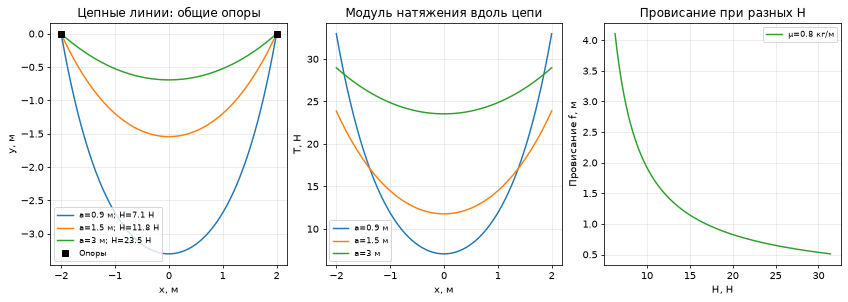

3.3: L = 6 м при всех формах; во второй половине H постоянно.



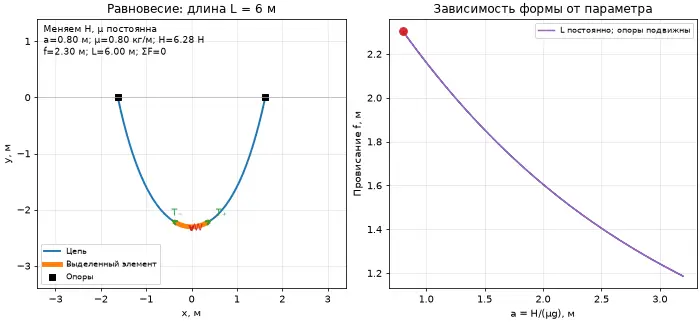
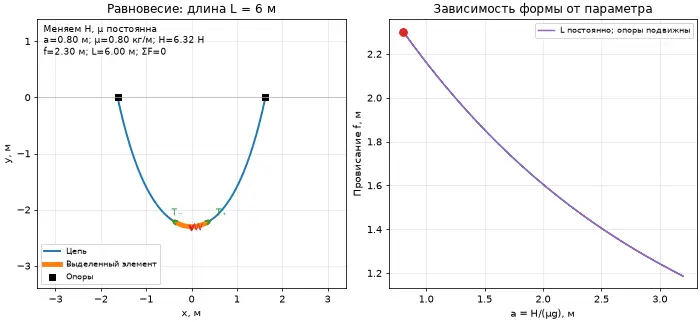
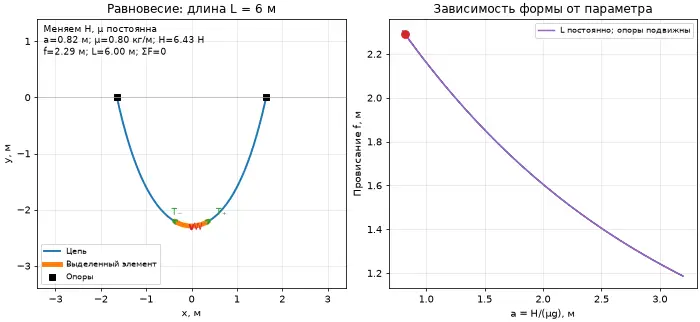
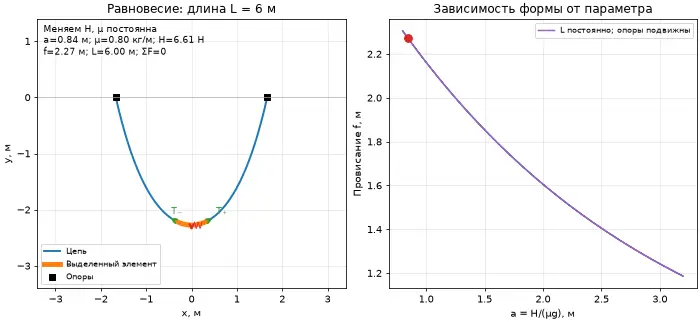
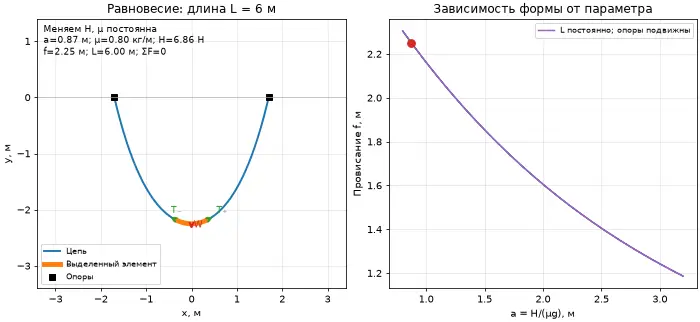
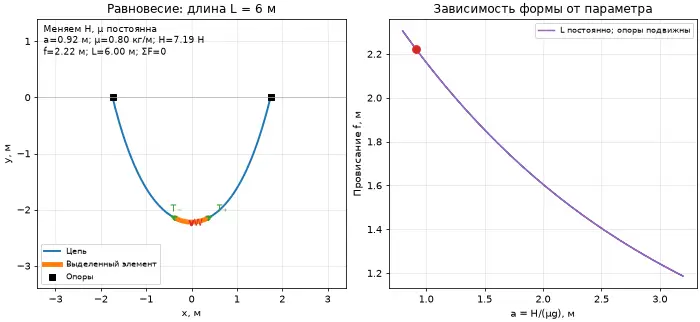
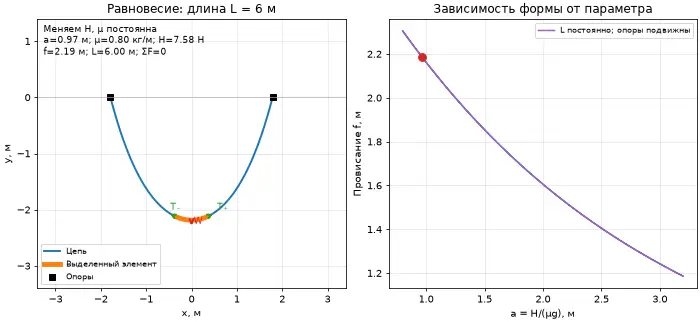
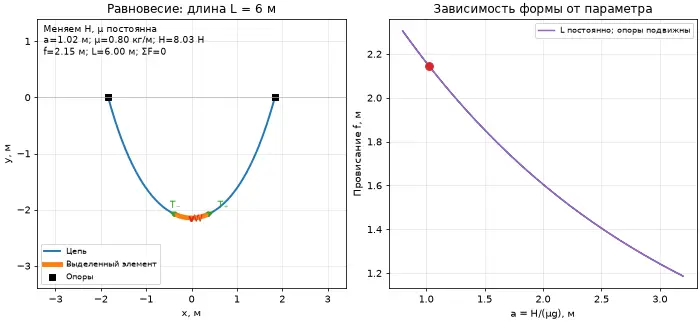
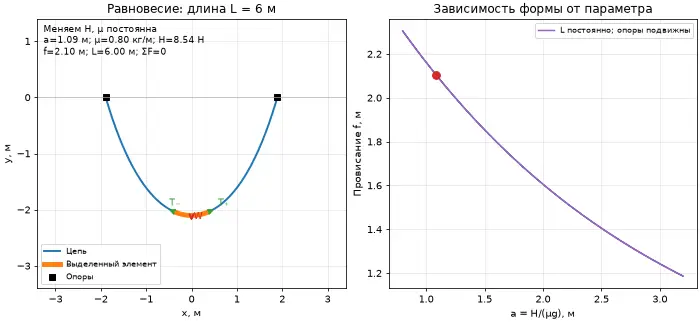
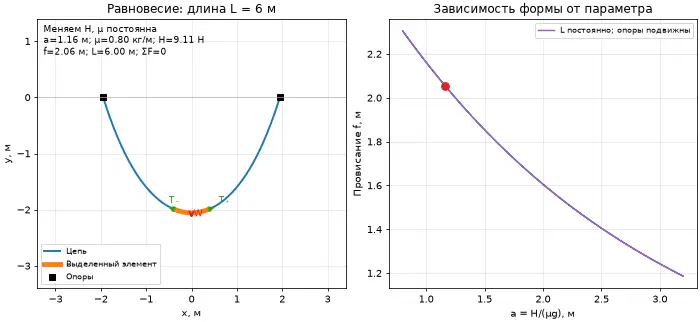
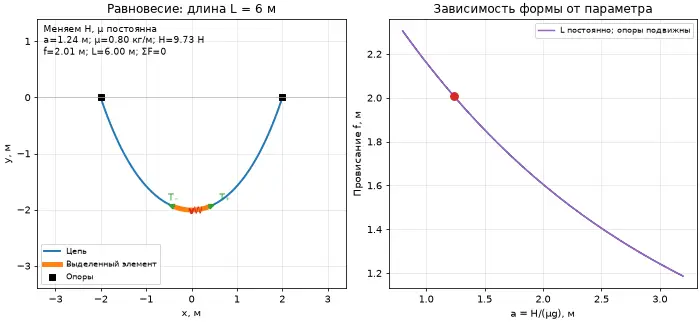
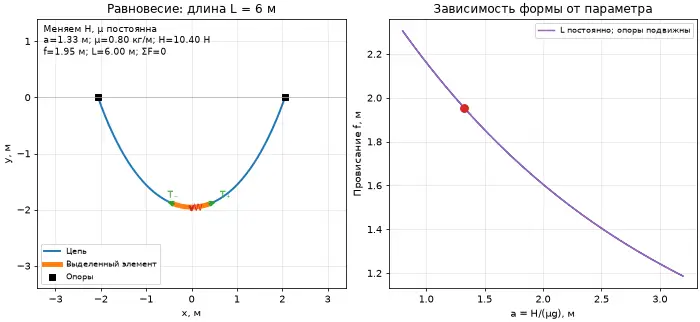
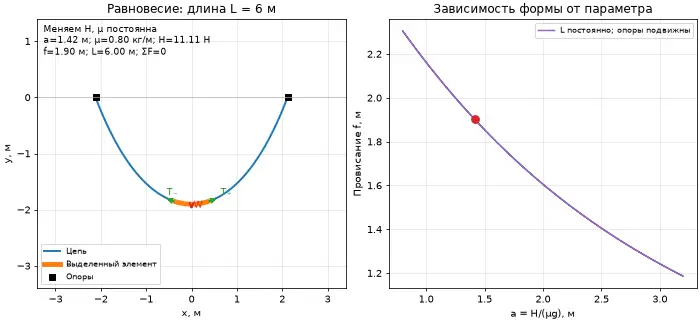
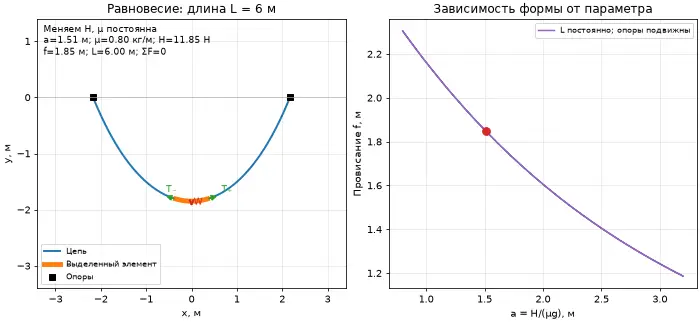
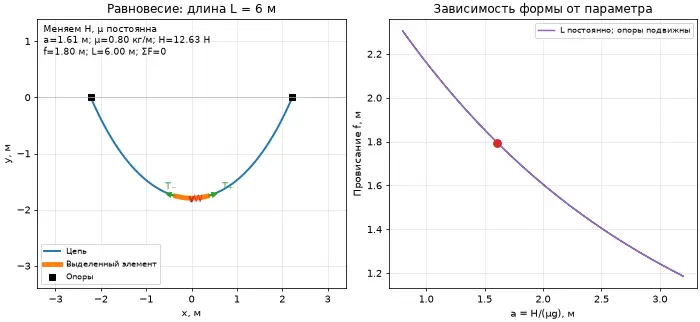
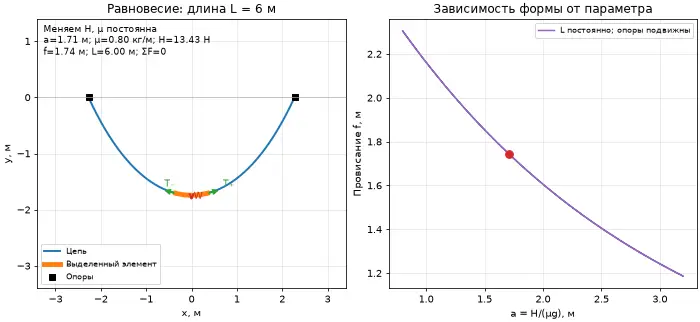
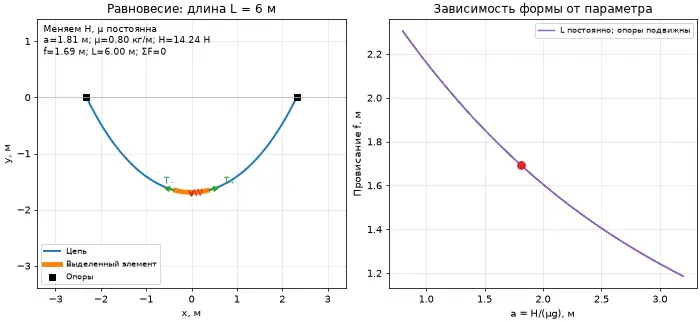
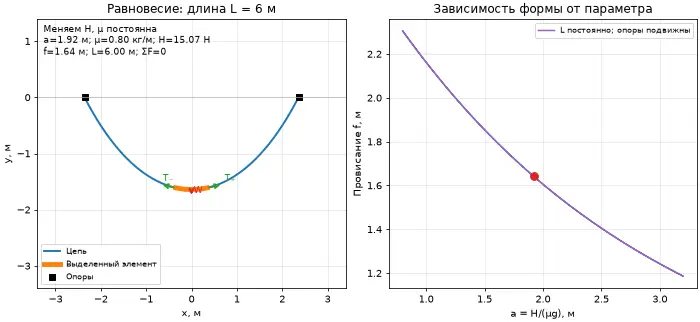
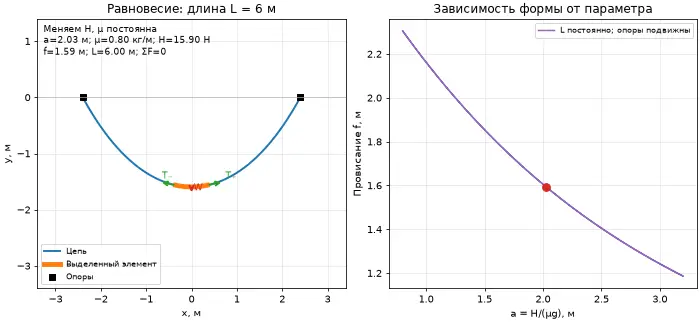
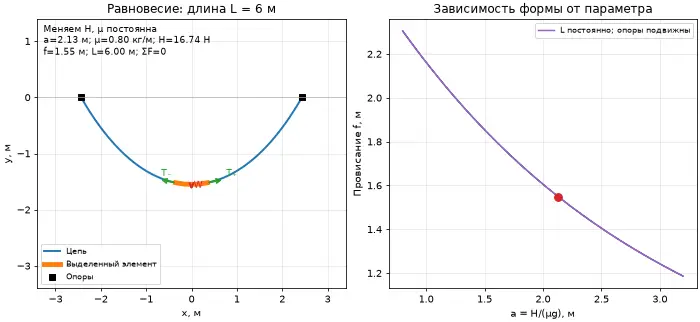
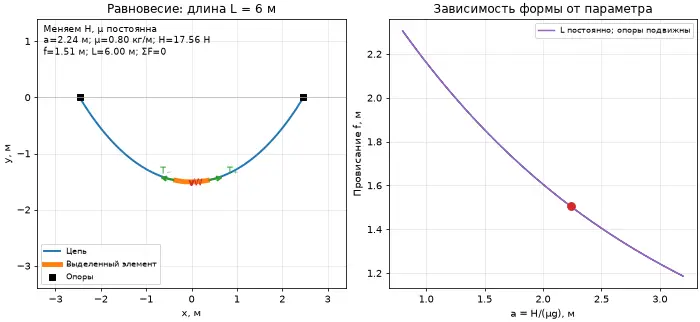
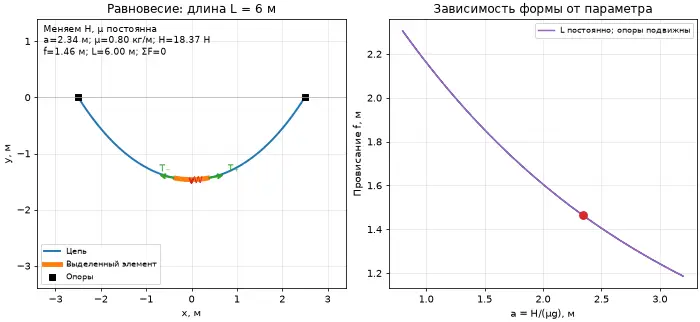
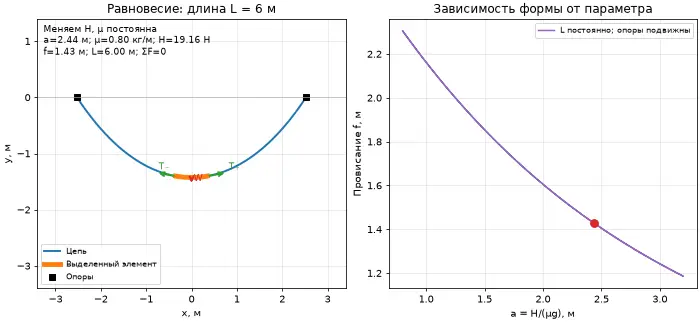
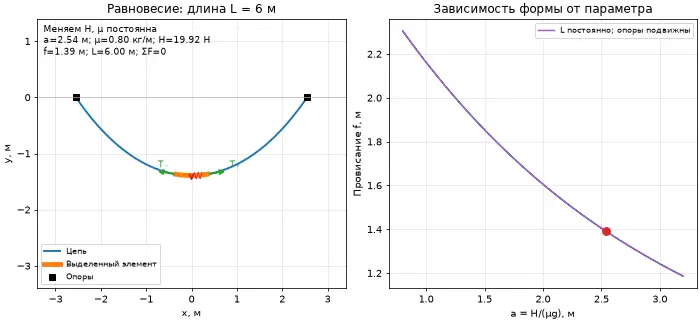
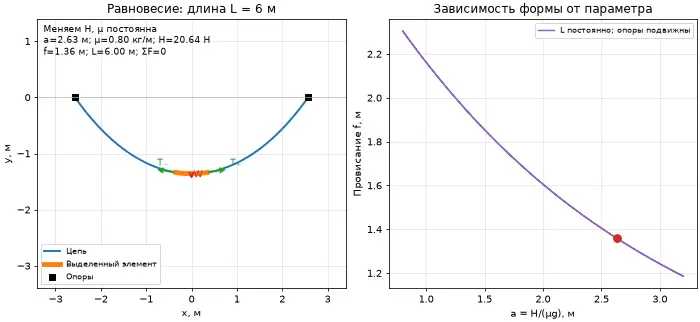
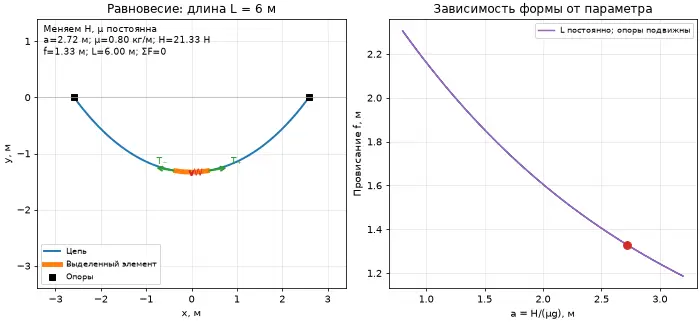
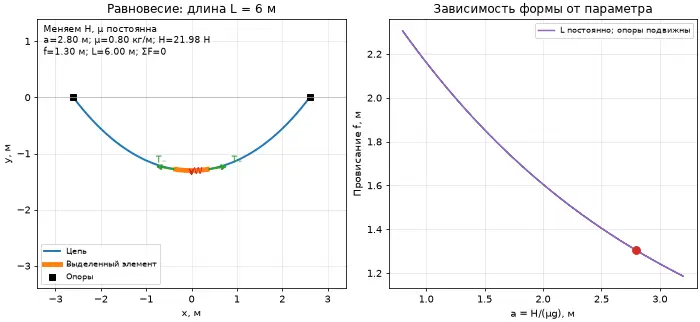
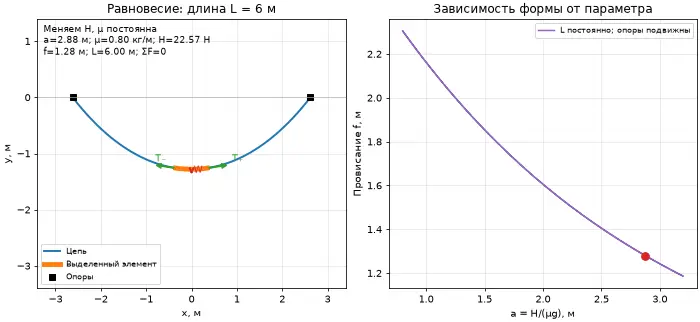
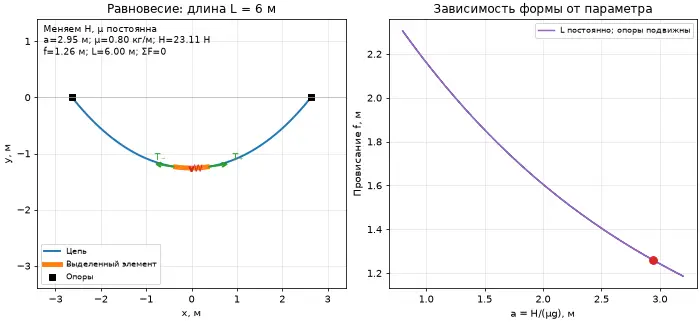
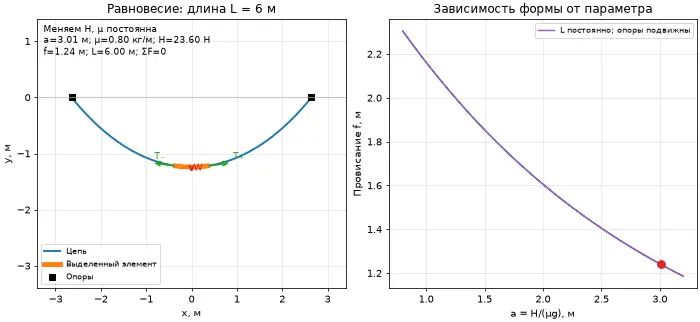
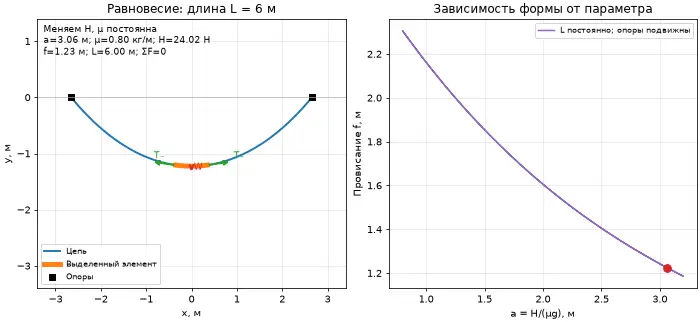
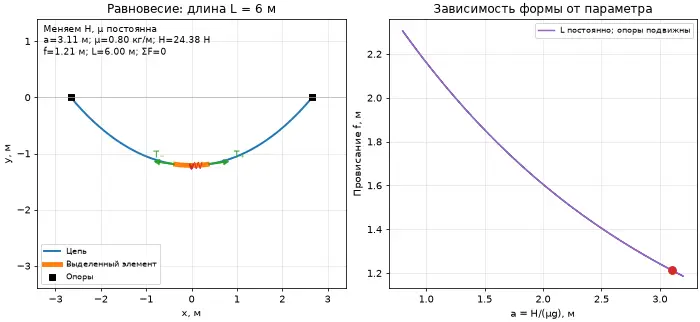
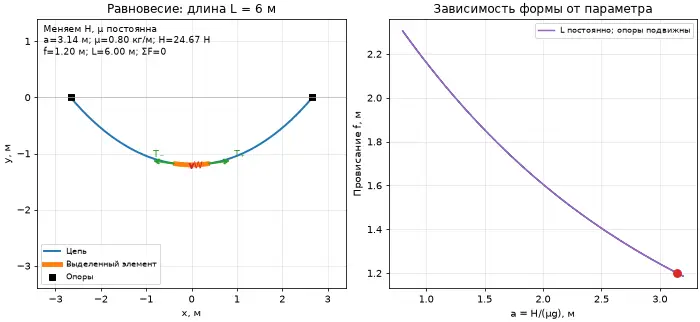
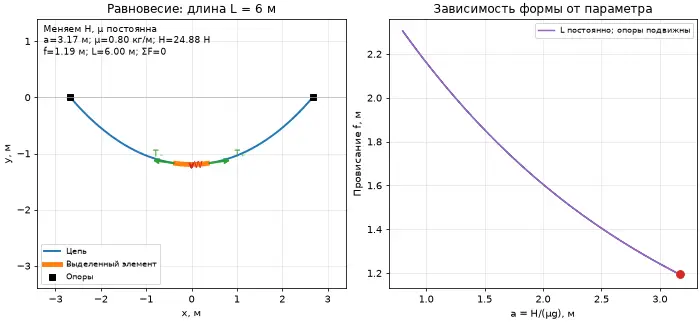
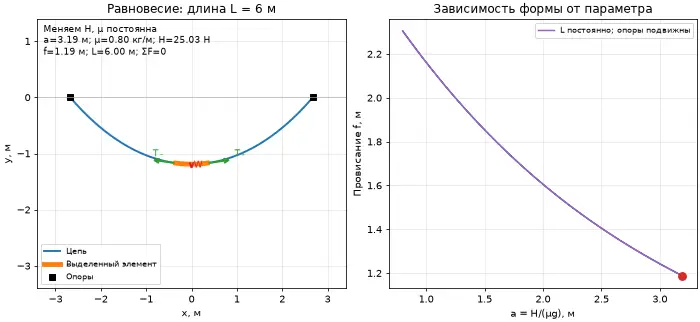
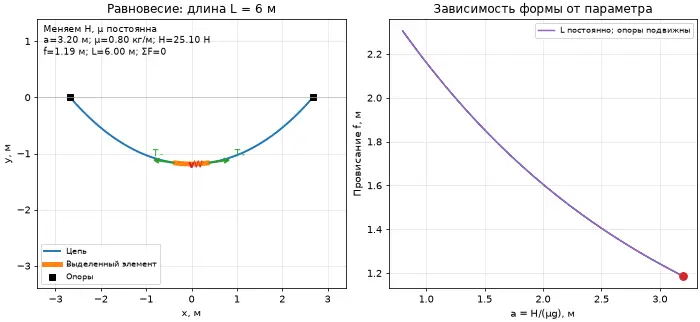
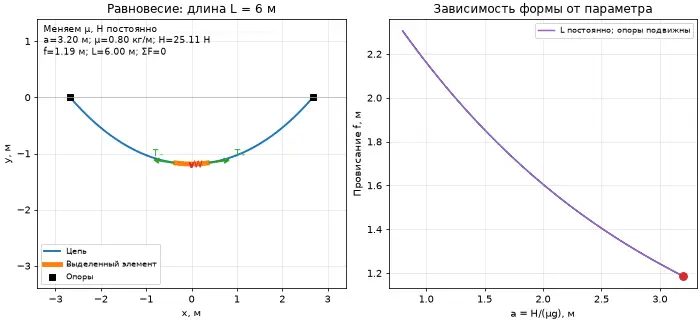
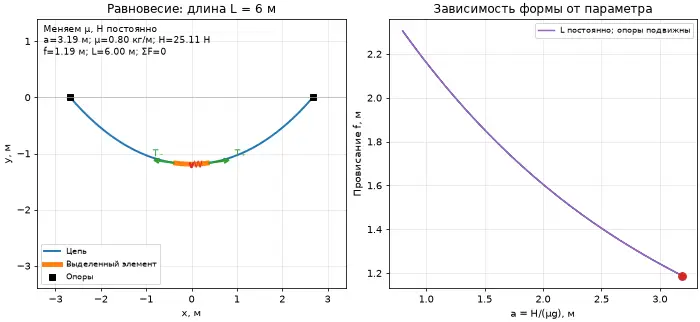
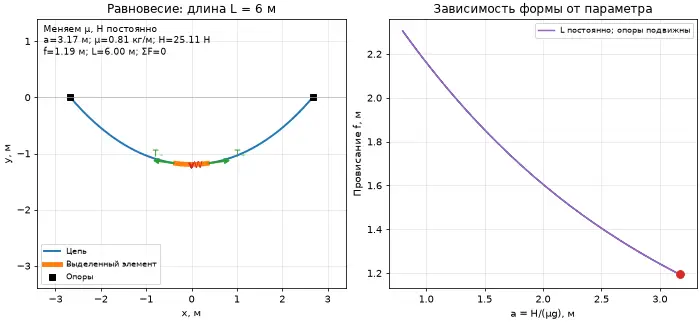
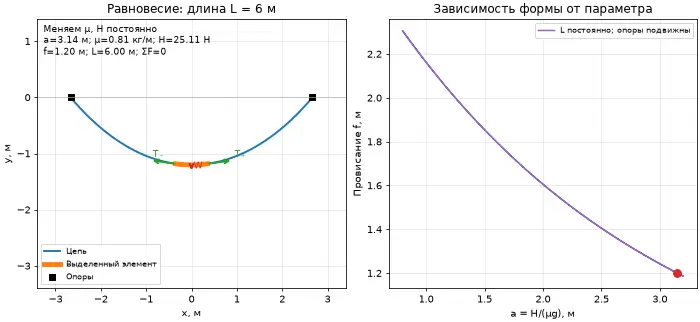
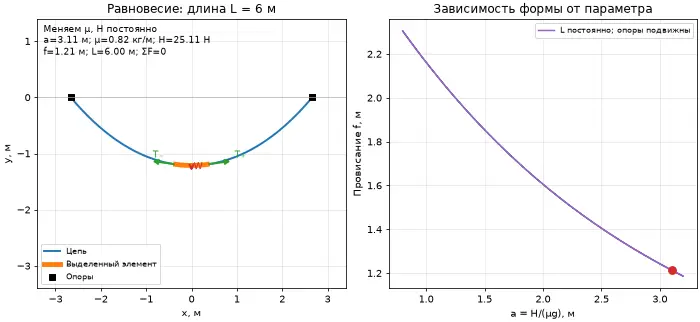
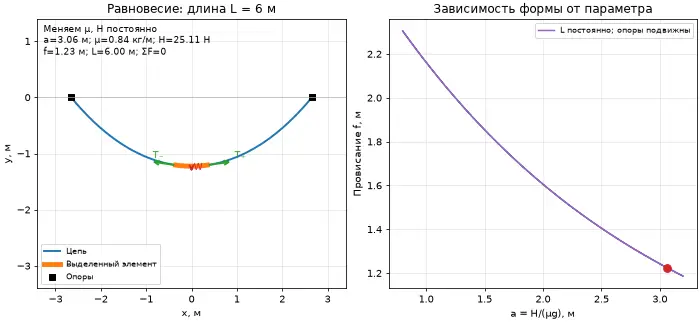
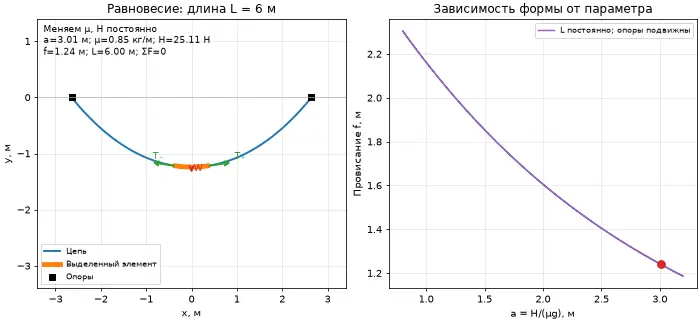
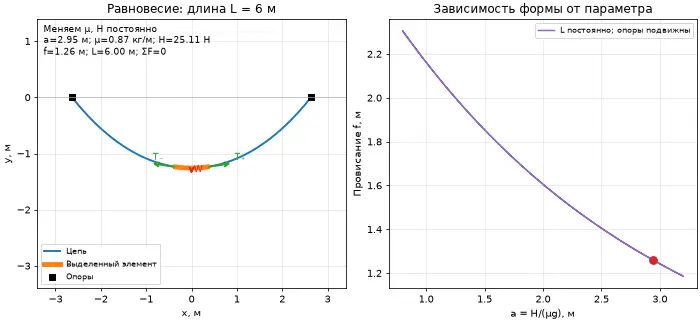
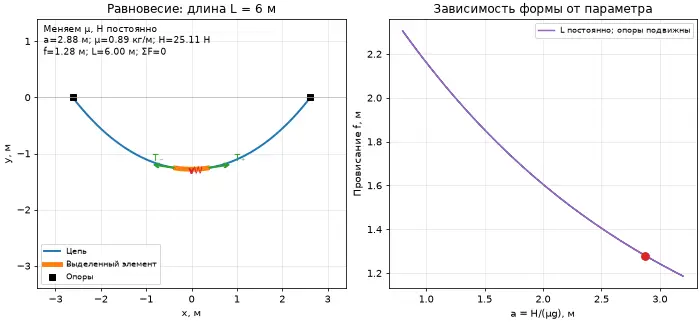
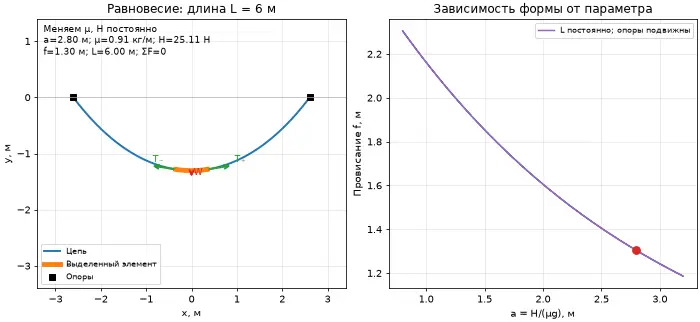
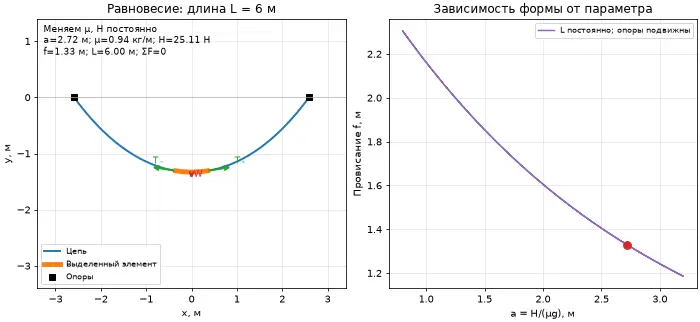
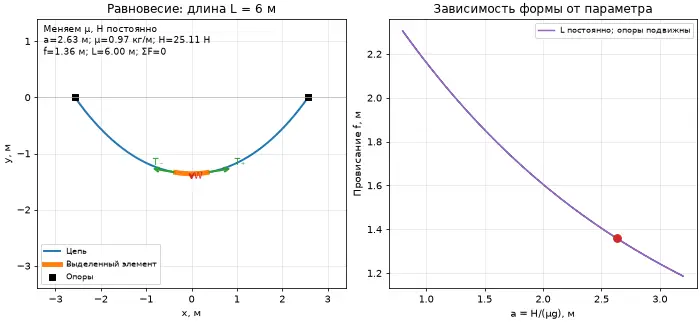
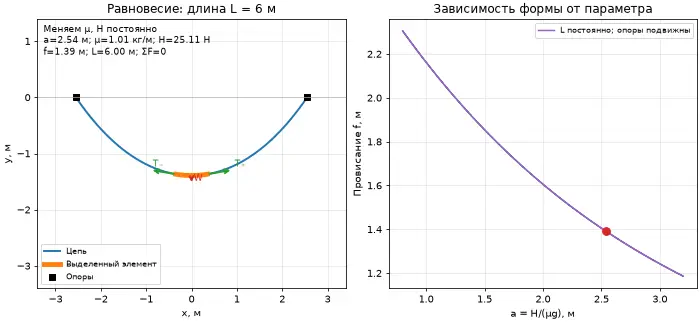
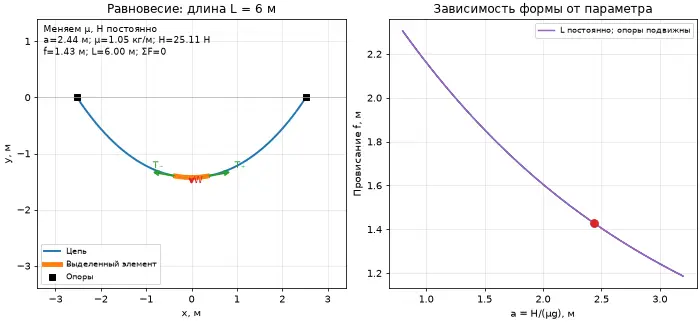
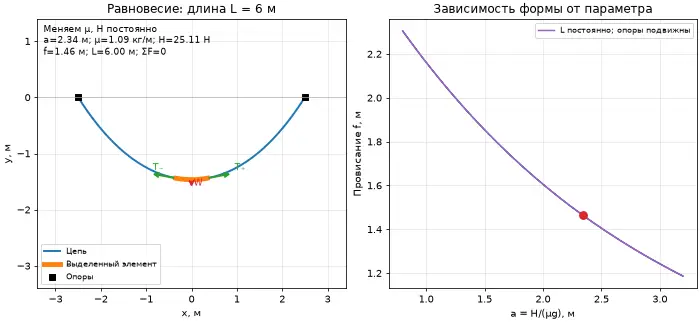
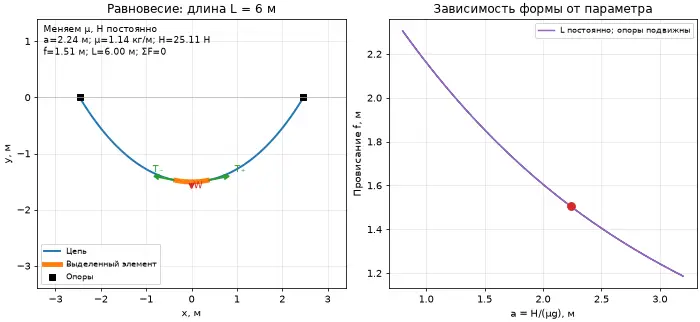
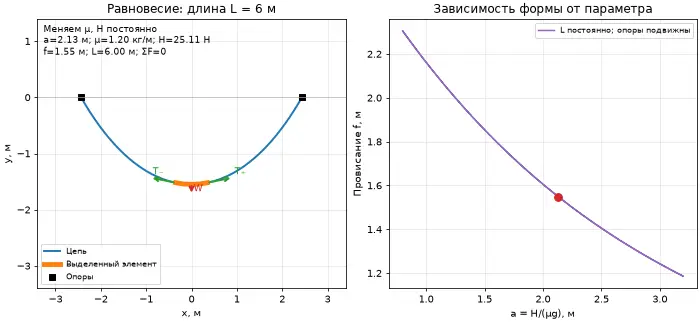
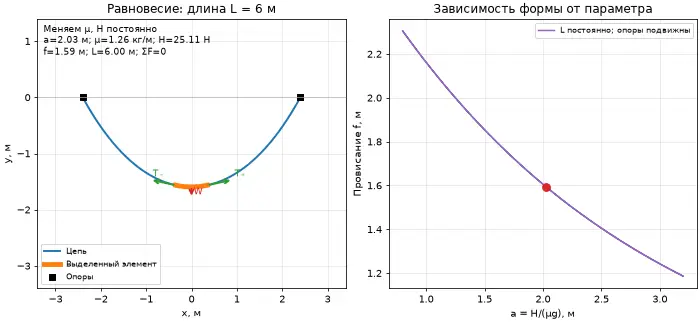
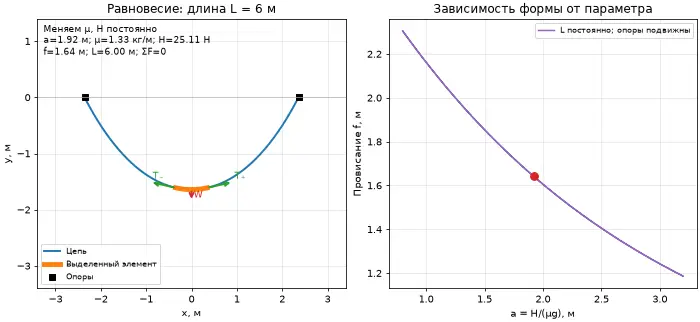
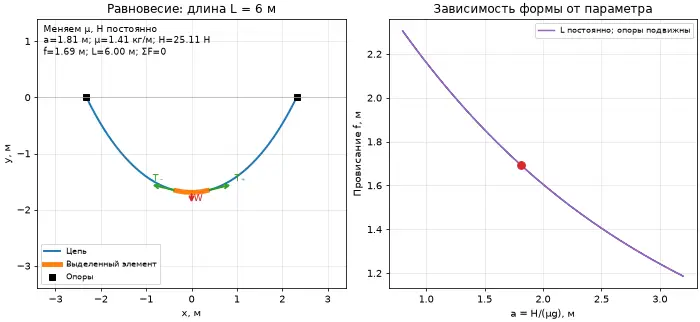
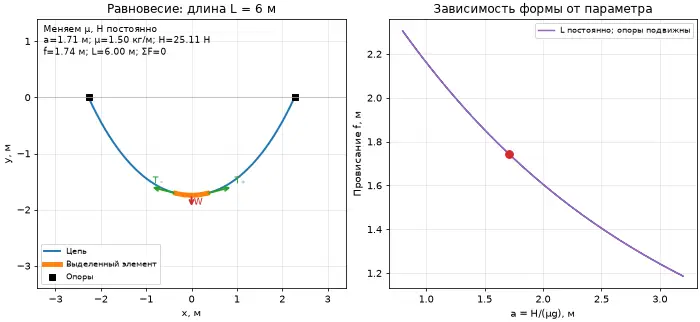
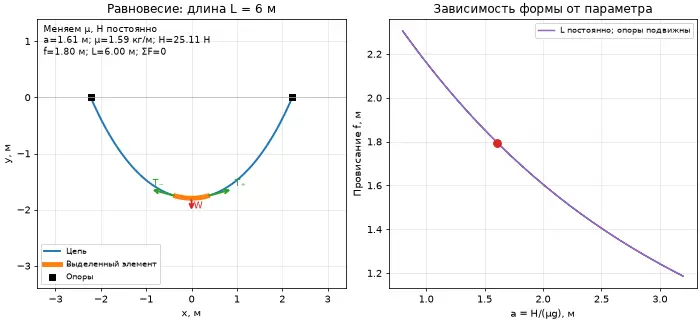
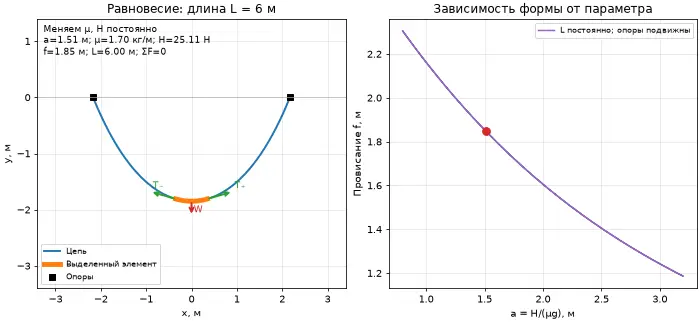
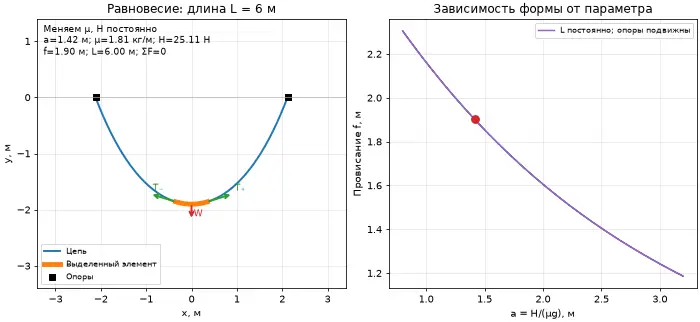
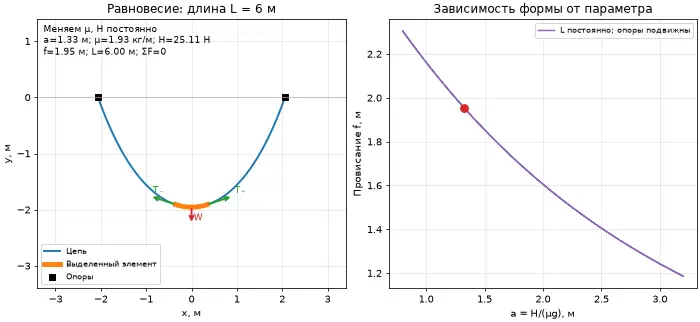
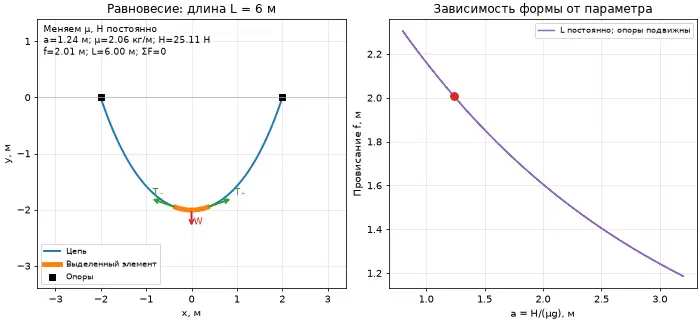
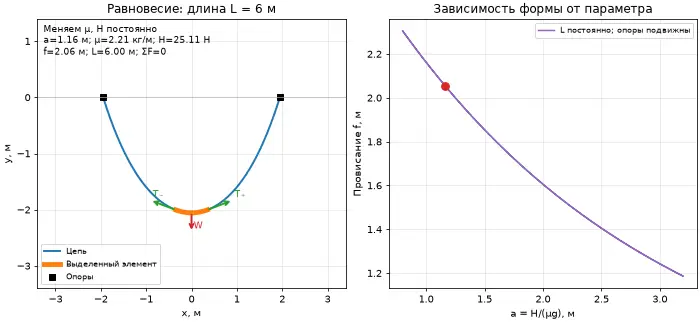
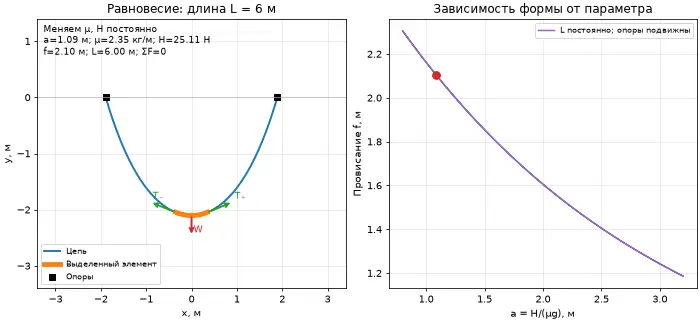
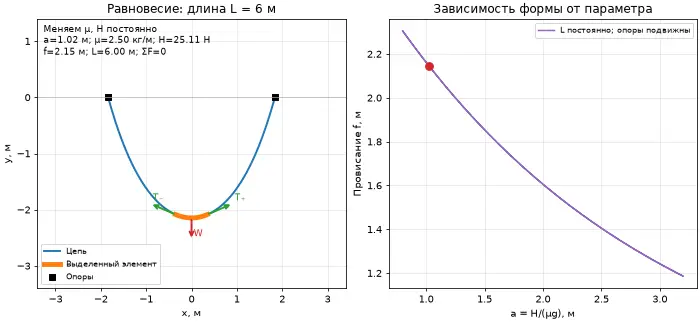
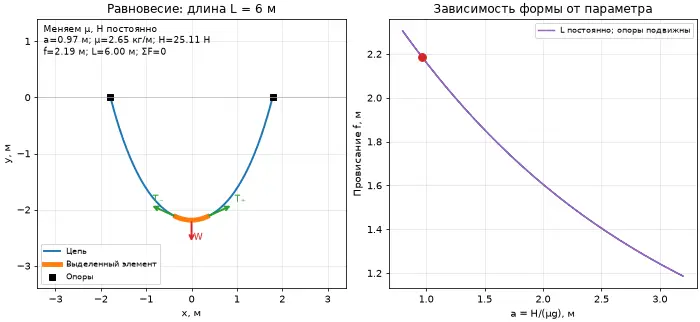
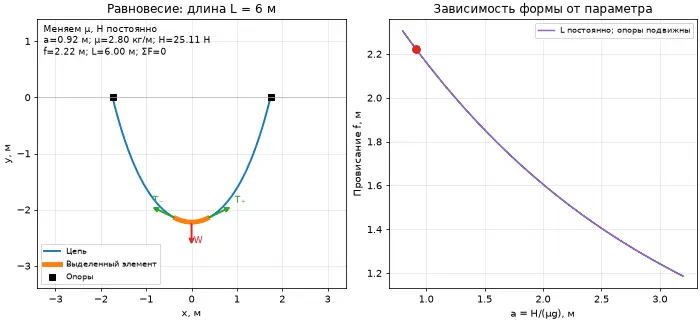
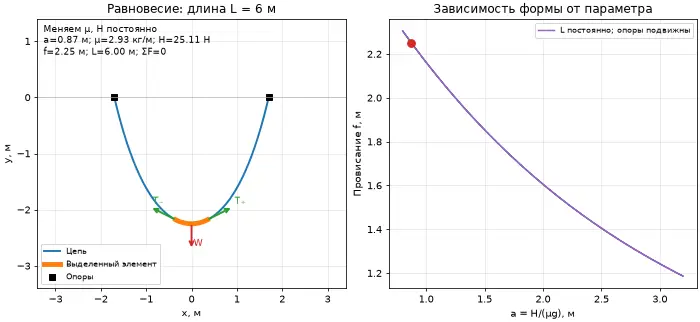
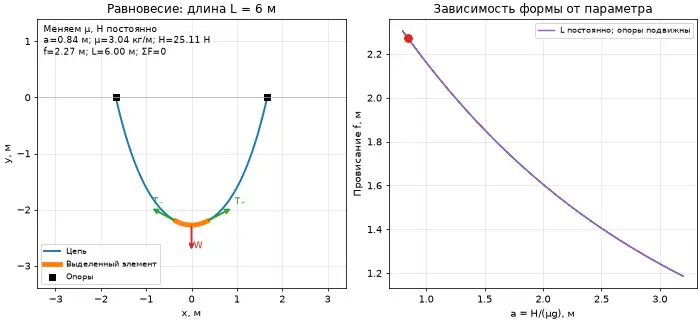
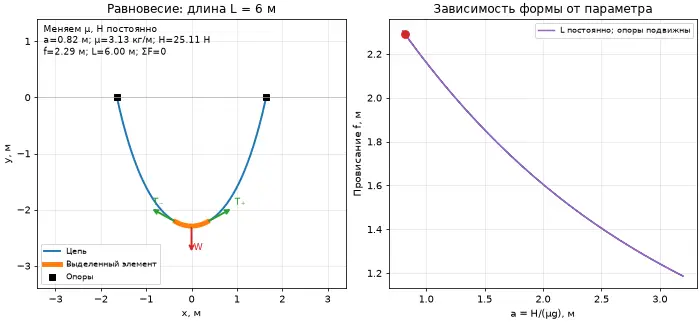
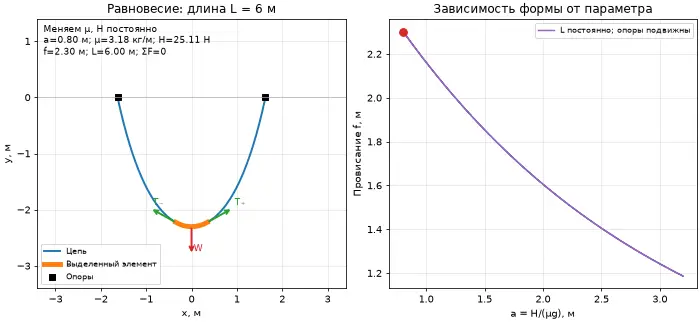
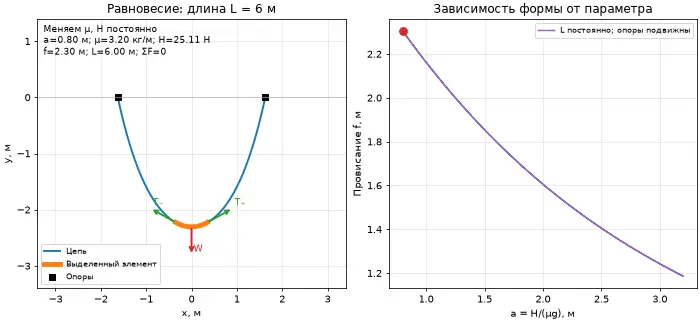

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, HTML
from pathlib import Path
from IPython import get_ipython
from PIL import Image as PILImage
import base64
import io
import re

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 70, 'animation.embed_limit': 100})
Path('figures').mkdir(exist_ok=True)
Path('animations').mkdir(exist_ok=True)


def export_animation(fig, update, name, frames=72):
    # HTML содержит штатные кнопки воспроизведения, паузы и выбора кадра.
    animation = FuncAnimation(fig, update, frames=frames, interval=50,
                              blit=False, repeat=False)
    html = animation.to_jshtml(fps=20, default_mode='once')
    # Компактные кадры сохраняют автономность HTML и уменьшают размер ноутбука.
    def compact_frame(match):
        raw = base64.b64decode(match.group(1).replace('\\', '').replace('\n', ''))
        buffer = io.BytesIO()
        with PILImage.open(io.BytesIO(raw)) as image:
            image.convert('RGB').save(buffer, format='WEBP', quality=72, method=4)
        return 'data:image/webp;base64,'+base64.b64encode(buffer.getvalue()).decode('ascii')
    html = re.sub(r'data:image/png;base64,([A-Za-z0-9+/=\\\n]+)', compact_frame, html)
    Path(f'animations/{name}.html').write_text(
        '<!doctype html><html lang="ru"><meta charset="utf-8">'
        f'<title>{name}</title><body>{html}</body></html>', encoding='utf-8')
    # GIF можно посмотреть прямо в README на GitHub без запуска Python.
    animation.save(f'animations/{name}.gif', writer=PillowWriter(fps=20), dpi=70)
    plt.close(fig)
    display(HTML(html))
    return animation


# 3.3: равновесие цепи и семейство форм с неизменной длиной.
g, mu, d, h = 9.81, 0.8, 2.0, 0.0
x = np.linspace(-d, d, 500)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), constrained_layout=True)
for a_value in [0.9, 1.5, 3.0]:
    y = h+a_value*(np.cosh(x/a_value)-np.cosh(d/a_value))
    H = mu*g*a_value
    axes[0].plot(x, y, label=f'a={a_value:g} м; H={H:.1f} Н')
    axes[1].plot(x, H*np.cosh(x/a_value), label=f'a={a_value:g} м')
axes[0].plot([-d, d], [h, h], 'ks', ms=6, label='Опоры')
axes[0].set(xlabel='x, м', ylabel='y, м', title='Цепные линии: общие опоры')
axes[1].set(xlabel='x, м', ylabel='T, Н', title='Модуль натяжения вдоль цепи')
aa = np.linspace(0.8, 4, 300)
axes[2].plot(mu*g*aa, aa*(np.cosh(d/aa)-1), color='#2ca02c', label='μ=0.8 кг/м')
axes[2].set(xlabel='H, Н', ylabel='Провисание f, м', title='Провисание при разных H')
for ax in axes: ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.savefig('figures/3_3_catenary.png', dpi=170)
plt.show()

# Длина каждой цепи L постоянна; положения опор определяются из L.
L, frames = 6.0, 72
u = np.linspace(0, 1, frames)
# Гладкое увеличение a в первой половине и уменьшение во второй.
profile = 0.5*(1-np.cos(2*np.pi*u))
a_values = 0.8+2.4*profile
mu_values = np.where(u <= 0.5, 0.8, 0.8*3.2/a_values)
H_values = mu_values*g*a_values
d_values = a_values*np.arcsinh(L/(2*a_values))
assert np.allclose(2*a_values*np.sinh(d_values/a_values), L)
assert np.allclose(H_values[u > 0.5], 0.8*g*3.2)
print('3.3: L = 6 м при всех формах; во второй половине H постоянно.')

fig, (ax, ax_dep) = plt.subplots(1, 2, figsize=(10, 4.6), constrained_layout=True)
curve, = ax.plot([], [], lw=2, color='#1f77b4', label='Цепь')
segment, = ax.plot([], [], lw=5, color='#ff7f0e', label='Выделенный элемент')
supports, = ax.plot([], [], 'ks', ms=6, label='Опоры')
ax.axhline(0, color='0.7', lw=0.7)
ax.set(xlim=(-3.4, 3.4), ylim=(-3.4, 1.4), xlabel='x, м', ylabel='y, м',
       title='Равновесие: длина L = 6 м')
ax.grid(alpha=0.3); ax.legend(loc='lower left', fontsize=8)
info = ax.text(0.02, .98, '', va='top', transform=ax.transAxes, fontsize=9)
force_colors = ['#2ca02c', '#2ca02c', '#d62728']
force_arrows = [ax.annotate('', xy=(0, 0), xytext=(0, 0),
                           arrowprops={'arrowstyle': '->', 'color': color, 'lw': 2})
                for color in force_colors]
force_labels = [ax.text(0, 0, text, color=color, fontsize=9)
                for text, color in zip(['T₋', 'T₊', 'W'], force_colors)]
f_values = a_values*(np.cosh(d_values/a_values)-1)
ax_dep.plot(a_values, f_values, color='#9467bd', label='L постоянно; опоры подвижны')
state, = ax_dep.plot([], [], 'o', color='#d62728', ms=8)
ax_dep.set(xlabel='a = H/(μg), м', ylabel='Провисание f, м', title='Зависимость формы от параметра')
ax_dep.grid(alpha=0.3); ax_dep.legend(fontsize=8)
force_scale = 0.022  # м/Н: одинаковый масштаб для всех трёх сил.


def update_33(i):
    av, muv, Hv, dv = a_values[i], mu_values[i], H_values[i], d_values[i]
    x = np.linspace(-dv, dv, 300)
    y = av*(np.cosh(x/av)-np.cosh(dv/av))
    curve.set_data(x, y); supports.set_data([-dv, dv], [0, 0])
    delta = 0.35
    xs = np.linspace(-delta, delta, 30)
    ys = av*(np.cosh(xs/av)-np.cosh(dv/av))
    segment.set_data(xs, ys)
    y_edge, y_bottom = ys[0], av*(1-np.cosh(dv/av))
    forces = [np.array([-Hv, Hv*np.sinh(delta/av)]),
              np.array([Hv, Hv*np.sinh(delta/av)]),
              np.array([0., -2*muv*g*av*np.sinh(delta/av)])]
    assert np.linalg.norm(np.sum(forces, axis=0)) < 1e-10
    origins = [np.array([-delta, y_edge]), np.array([delta, y_edge]), np.array([0., y_bottom])]
    for arrow, label, origin, force in zip(force_arrows, force_labels, origins, forces):
        tip = origin+force_scale*force
        arrow.xy = tip; arrow.set_position(origin)
        label.set_position(tip+np.array([0.05, 0.06]))
    state.set_data([av], [f_values[i]])
    regime = 'Меняем H, μ постоянна' if u[i] <= .5 else 'Меняем μ, H постоянно'
    info.set_text(f'{regime}\na={av:.2f} м; μ={muv:.2f} кг/м; H={Hv:.2f} Н\n'
                  f'f={f_values[i]:.2f} м; L={L:.2f} м; ΣF=0')
    return []


animation_33 = export_animation(fig, update_33, '3_3_catenary', frames)


## 3.4

**Таутохрона.** Точка без трения скользит в однородном поле тяжести по неподвижной кривой, стартуя из покоя. Ось $y$ направлена вверх; нижняя точка имеет $y=0$. На одной монотонной ветви высота начальной точки равна $h>0$, длина дуги от низа до уровня $y$ обозначена $s(y)$, $s(0)=0$.

**Интегральное уравнение.** Из сохранения энергии
$$\frac{mv^2}{2}=mg(h-y),\qquad v=\sqrt{2g(h-y)}.$$
Поэтому время спуска
$$T(h)=\frac1{\sqrt{2g}}\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy.$$
Условие $T(h)=T_0$ приводит к уравнению Абеля:
$$\boxed{\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy=T_0\sqrt{2g}}.$$

**Решение уравнения Абеля.** Умножим уравнение на $(Y-h)^{-1/2}$ и проинтегрируем по $h\in(0,Y)$. Меняя порядок интегрирования, получаем
$$\int_0^Y s'(y)\left[\int_y^Y\frac{dh}{\sqrt{(h-y)(Y-h)}}\right]dy
=2T_0\sqrt{2gY}.$$
Внутренний интеграл равен $\pi$ (подстановка $h=y+(Y-y)\sin^2u$). Значит,
$$\pi s(Y)=2T_0\sqrt{2gY},\qquad
\boxed{s(y)=\frac{2T_0\sqrt{2g}}{\pi}\sqrt y}.$$
Введём $R=gT_0^2/\pi^2$; тогда
$$\boxed{s^2=8Ry},\qquad\boxed{T_0=\pi\sqrt{R/g}}.$$

**Восстановление кривой.** Так как $ds^2=dx^2+dy^2$,
$$\left(\frac{dx}{dy}\right)^2=\left(\frac{ds}{dy}\right)^2-1=\frac{2R-y}{y}.$$
Полагая $y=R(1-\cos\theta)$, $0\le\theta<\pi$, получаем
$$\frac{dx}{d\theta}=R(1+\cos\theta),\qquad
\boxed{x=R(\theta+\sin\theta),\quad y=R(1-\cos\theta)}.$$
Левая ветвь получается при $-\pi<\theta\le0$. Это перевёрнутая арка циклоиды с нижней точкой $(0,0)$; гладкая часть ограничена $|\theta|<\pi$. Высота старта должна удовлетворять $0<h<2R$. Верхние острия рассматриваются только как предельный случай.

**Независимость времени от старта.** Знаковая дуговая координата $s=4R\sin(\theta/2)$ удовлетворяет $y=s^2/(8R)$. Уравнение касательного движения
$$\ddot s=-g\frac{dy}{ds}=-\frac{g}{4R}s.$$
Для старта из покоя $s(0)=s_0\ne0$:
$$s(t)=s_0\cos(\omega t),\quad\omega=\sqrt{\frac{g}{4R}},$$
$$\theta(t)=2\arcsin\left(\frac{s_0}{4R}\cos\omega t\right).$$
Первый приход в нижнюю точку происходит при
$$\boxed{t=\frac{\pi}{2\omega}=\pi\sqrt{R/g}},$$
независимо от $s_0$. Полный период колебаний равен $4T_0$. Начальное положение непосредственно внизу исключается: там точка остаётся в покое.

**Геометрическое построение.** Для окружности радиуса $R$, катящейся без скольжения по горизонтали $y=2R$, центр и отмеченная точка имеют координаты
$$C=(R\theta,R),\qquad
P=C+(R\sin\theta,-R\cos\theta).$$
Это даёт ту же циклоиду; центр проходит $R\,d\theta$, а окружность поворачивается на $d\theta$. На рисунке и в правой части анимации показаны окружность, её радиус и след отмеченной точки. Слева три точки из покоя стартуют на одной ветви с разных высот и достигают низа одновременно. После первого прихода анимация удерживает их внизу для наглядности; физическое продолжение было бы колебательным.


3.4: теоретическое время спуска T₀ = 1.0030333404 с
θ₀=0.65 рад; h=0.203916 м; T=1.0030333403 с
θ₀=1.40 рад; h=0.830033 м; T=1.0030333404 с
θ₀=2.50 рад; h=1.801144 м; T=1.0030333404 с


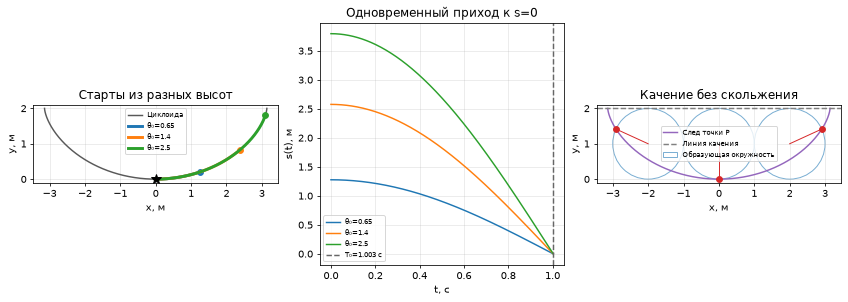


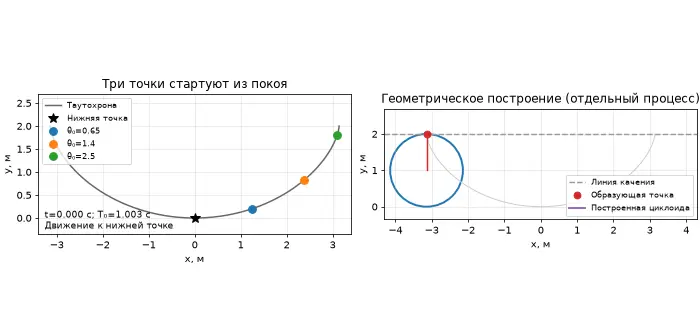
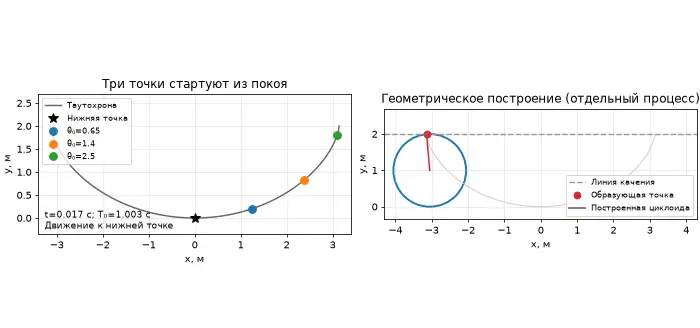
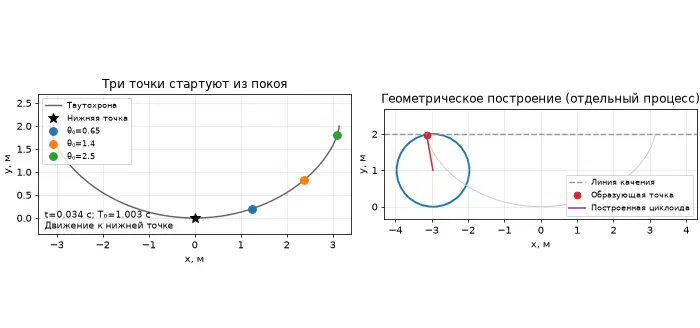
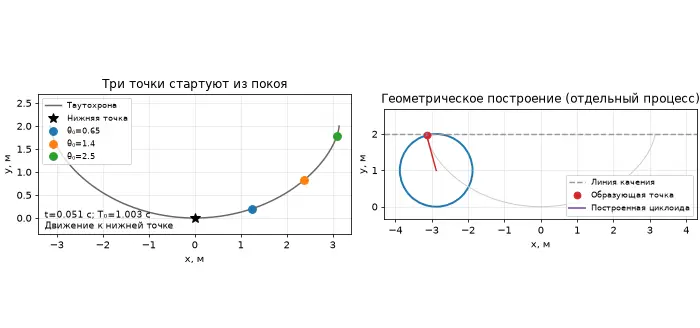
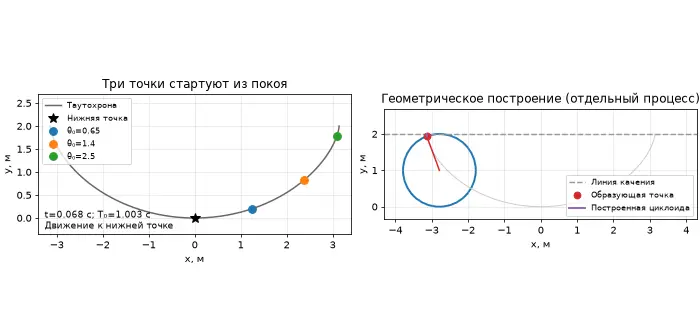
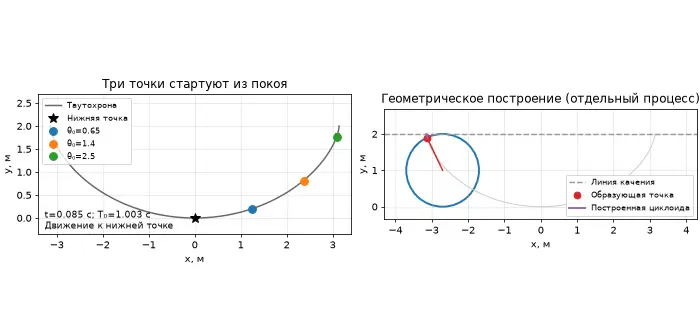
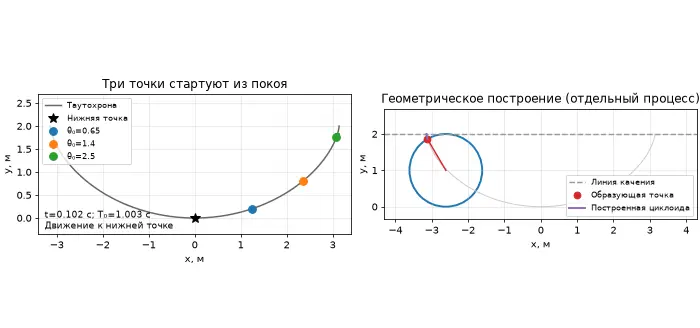
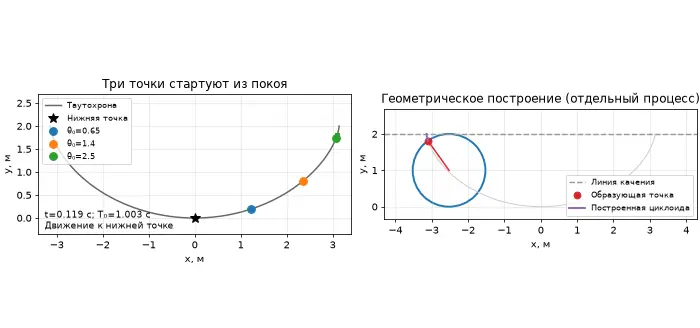
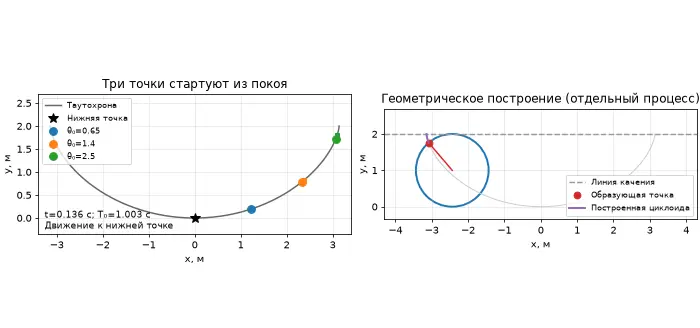
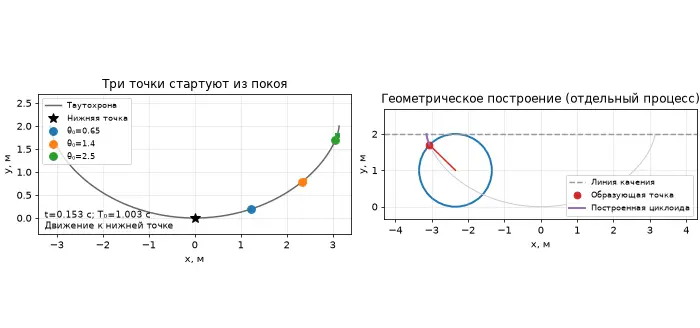
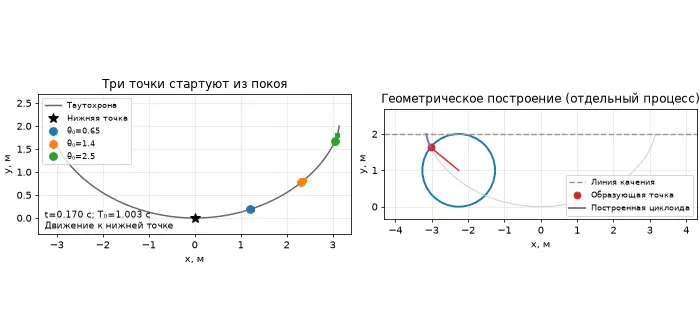
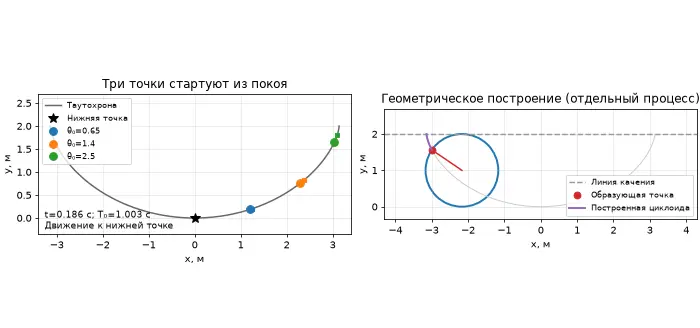
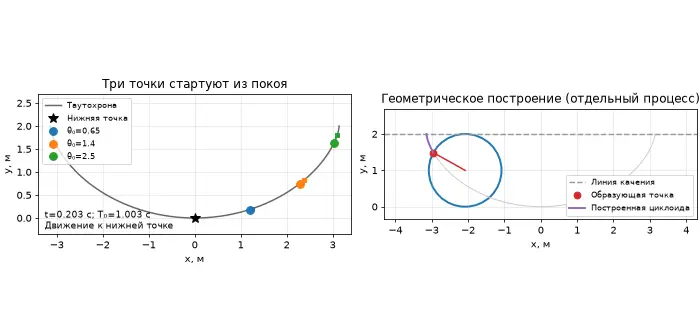
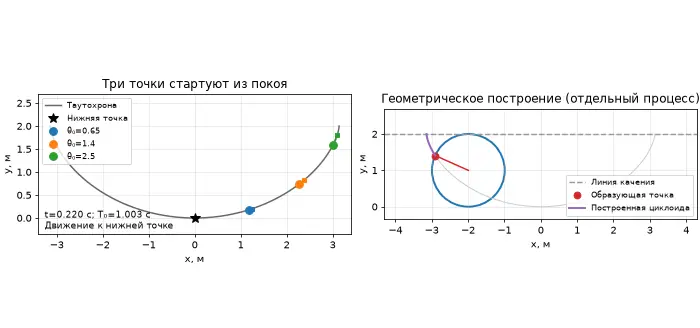
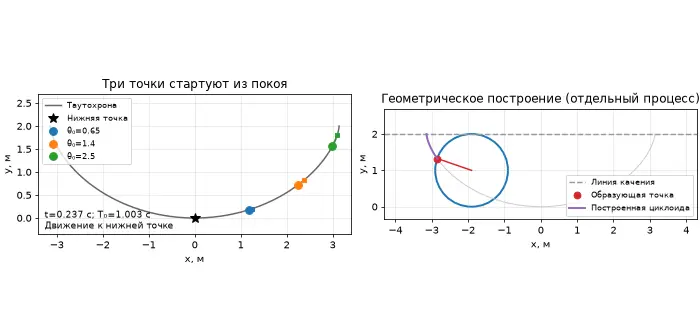
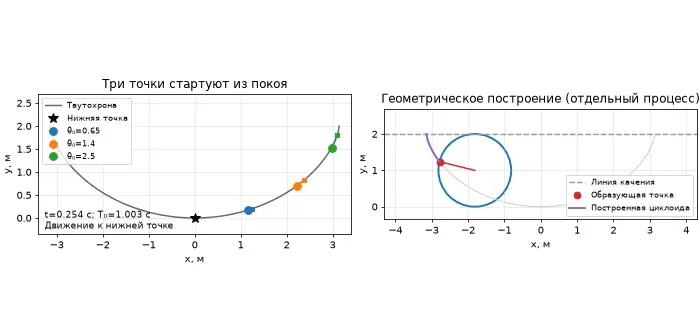
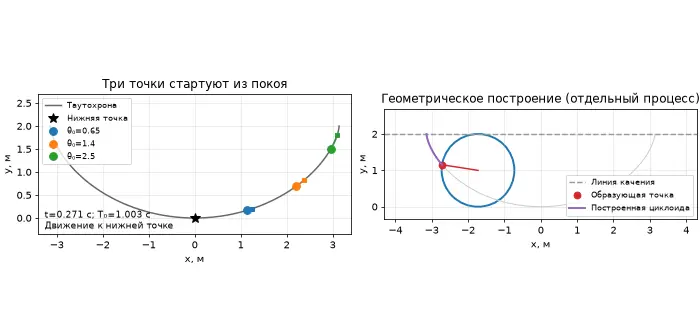
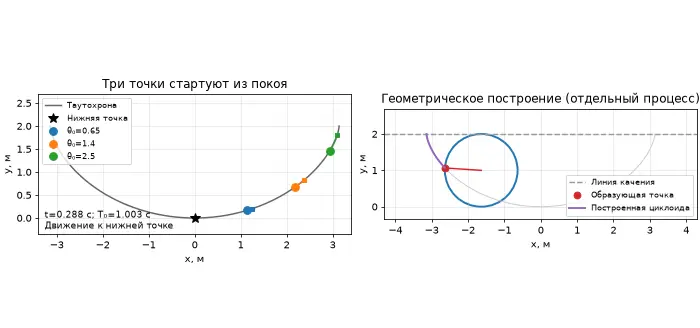
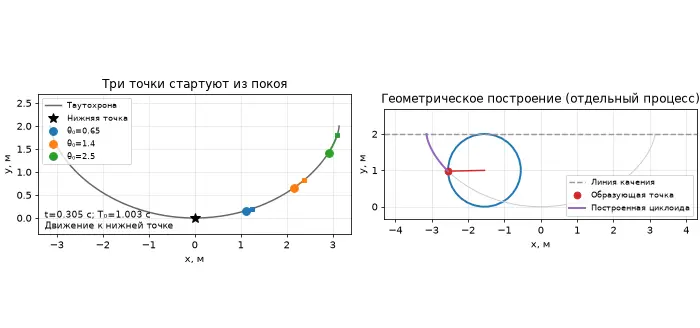
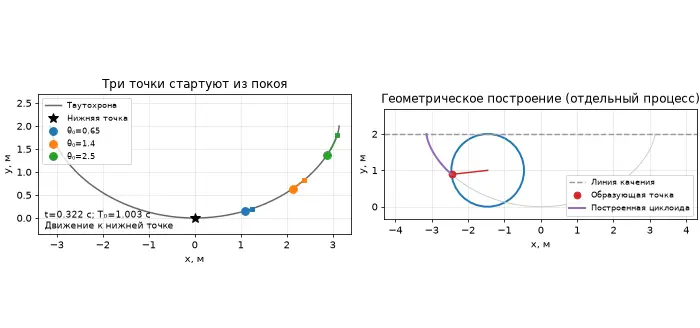
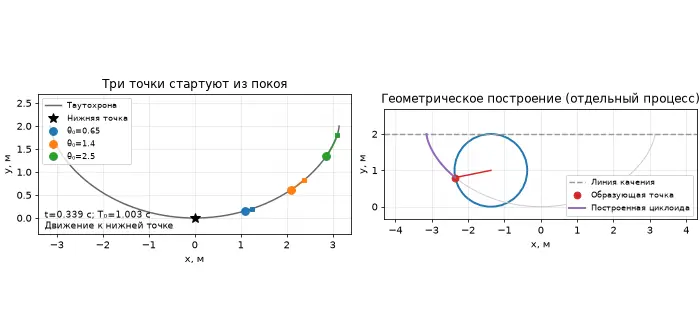
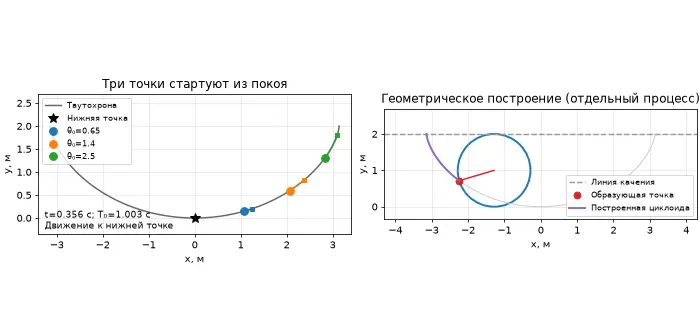
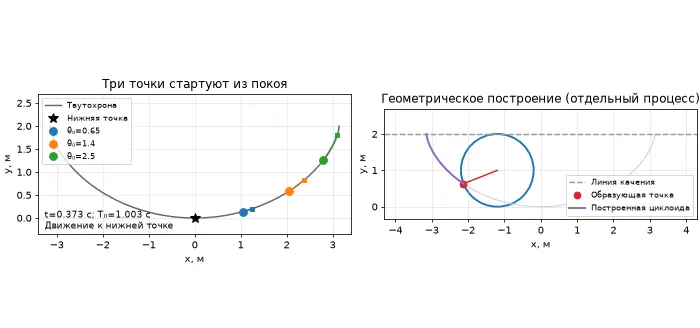
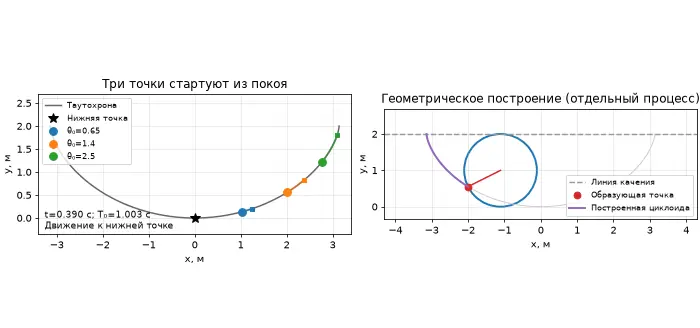
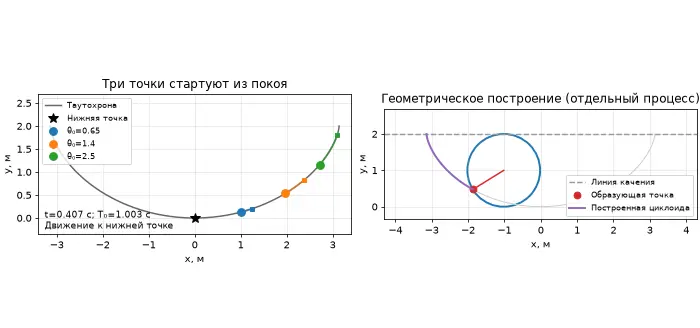
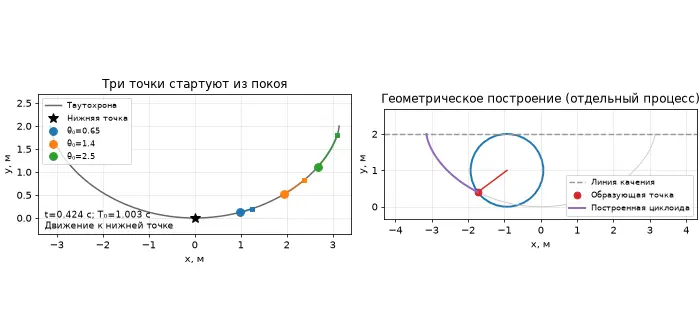
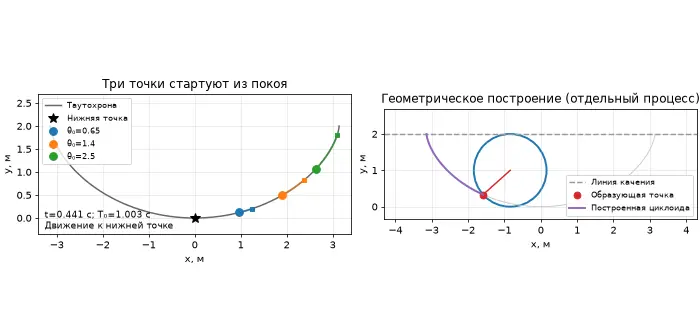
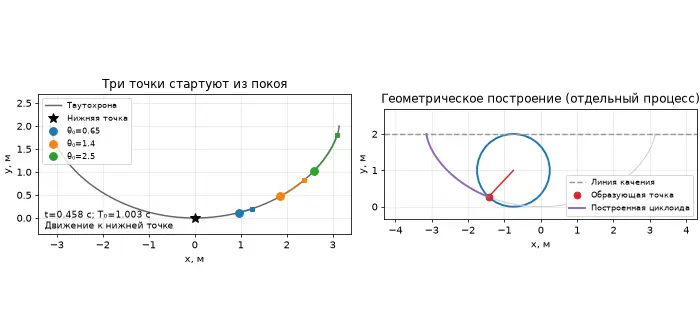
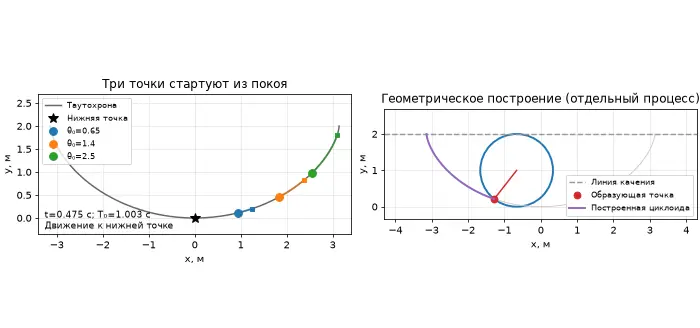
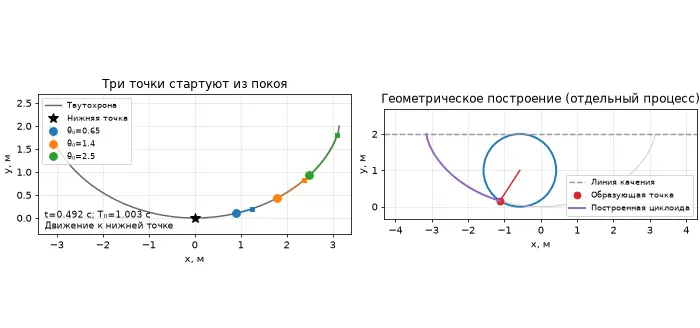
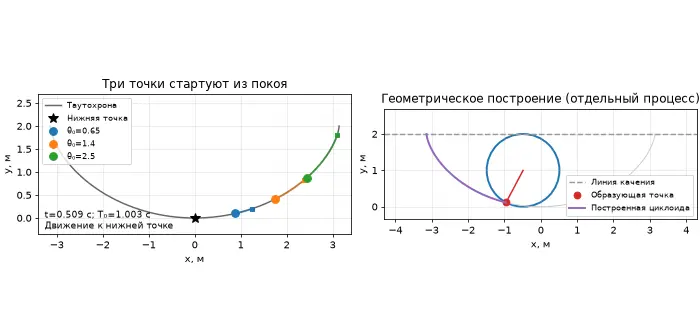
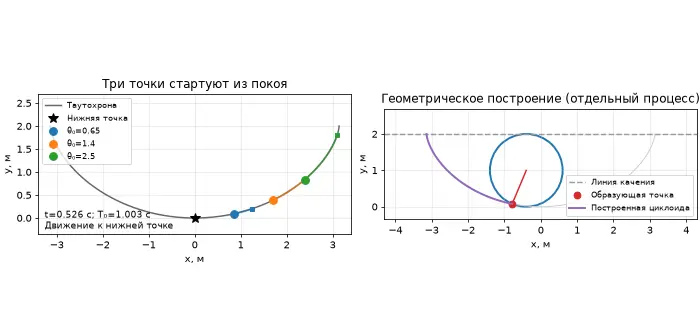
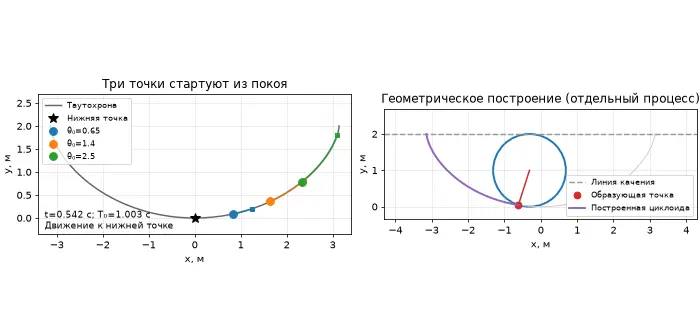
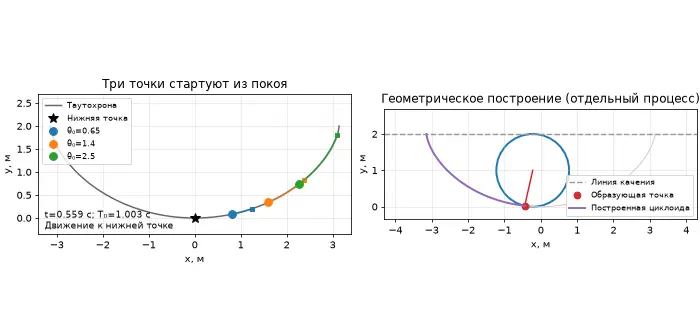
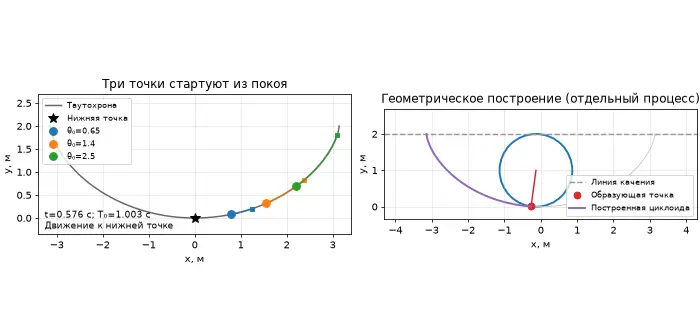
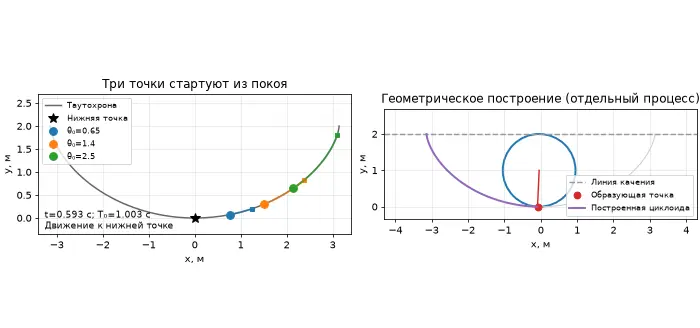
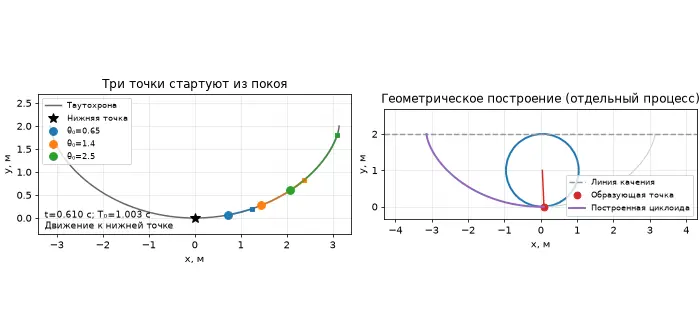
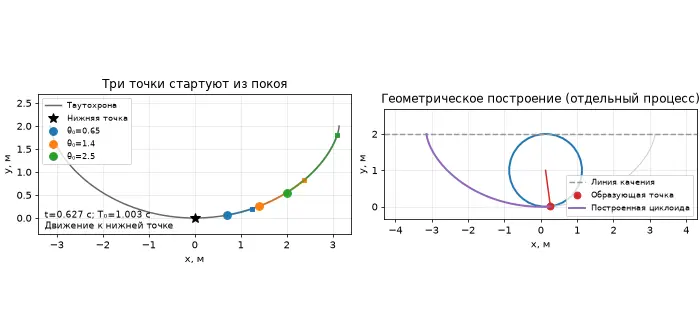
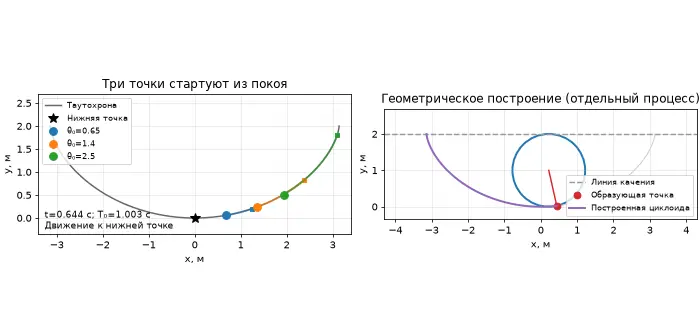
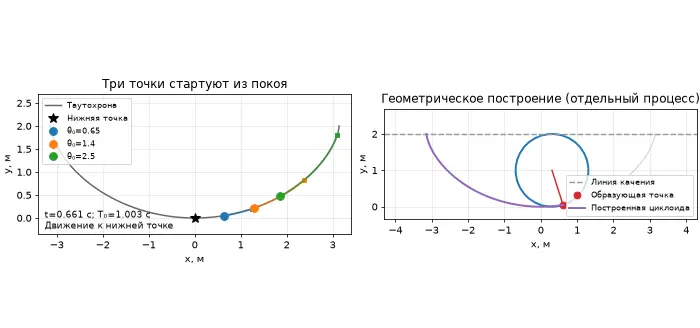
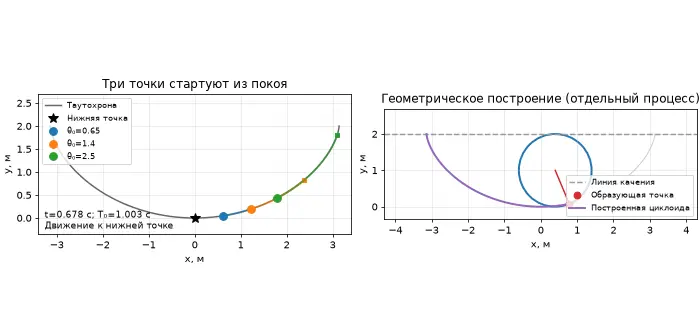
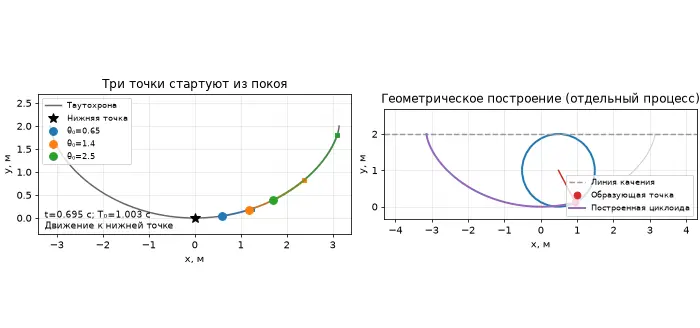
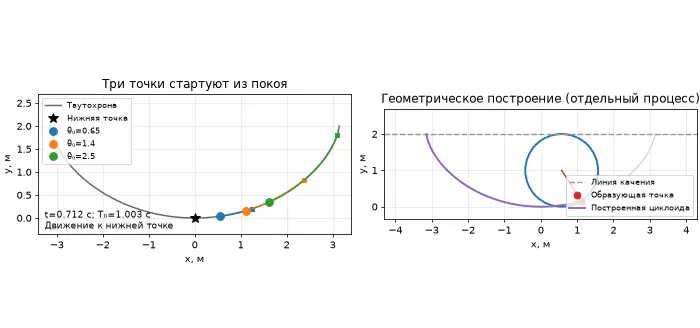
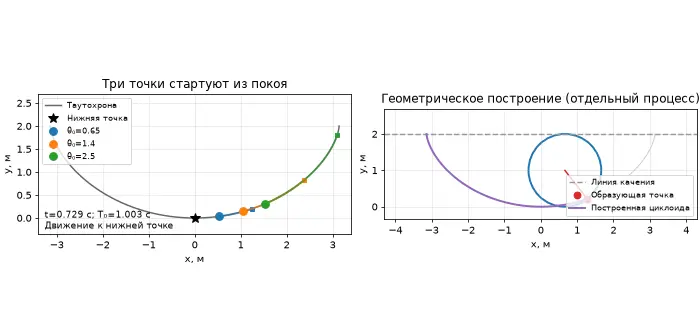
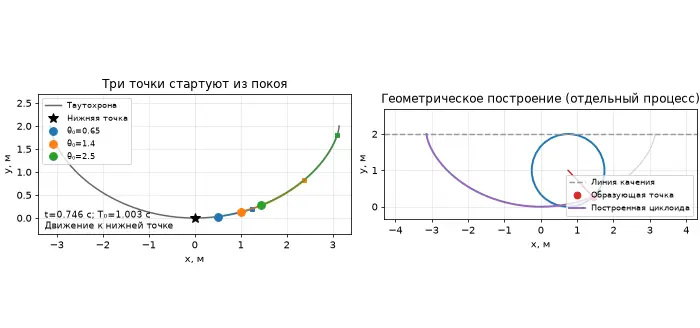
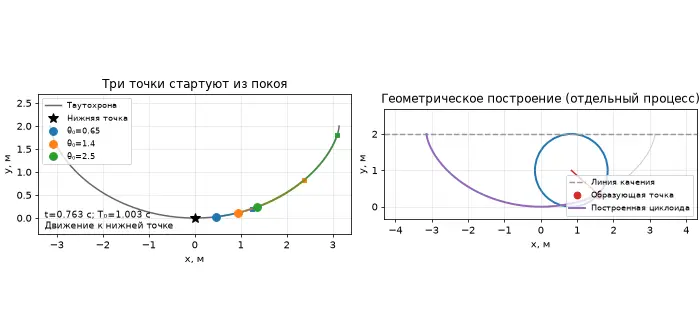
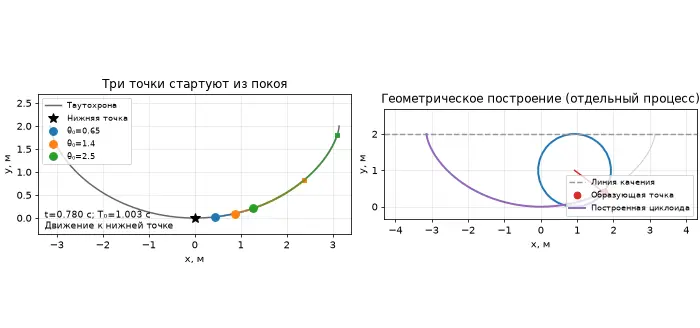
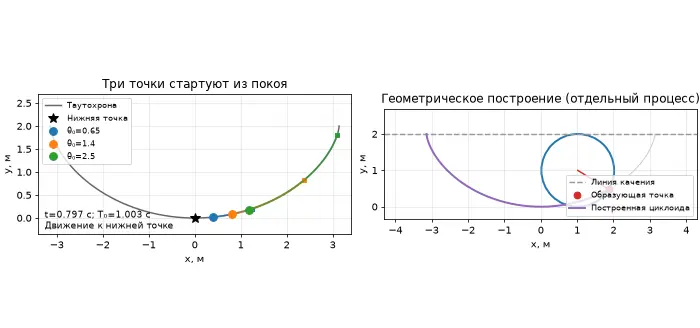
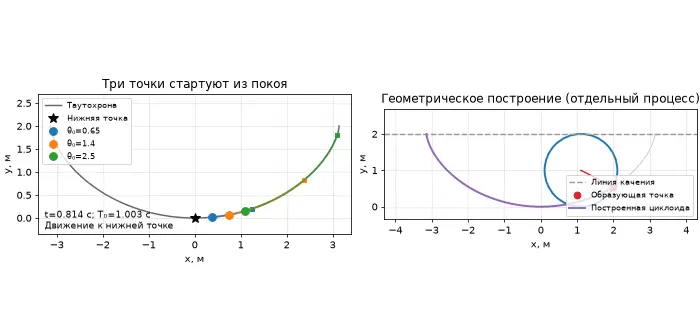
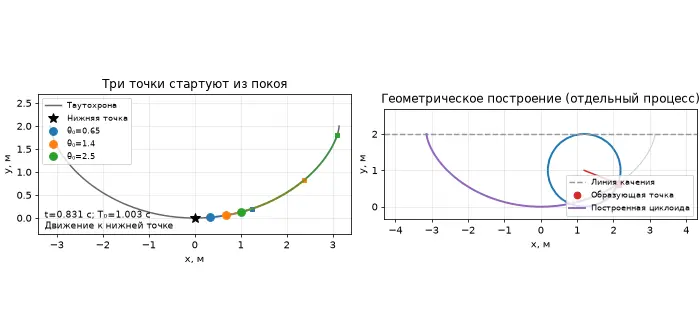
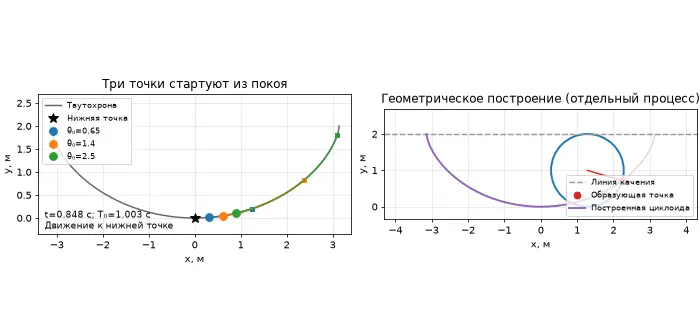
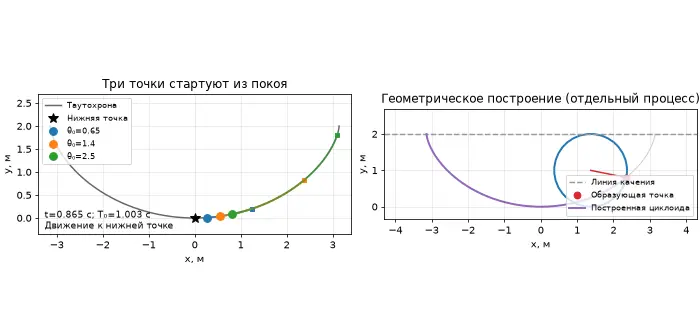
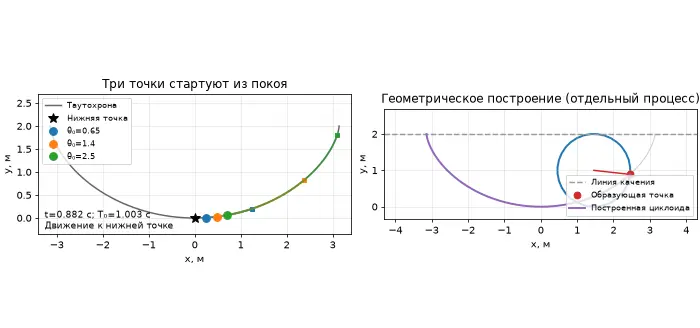
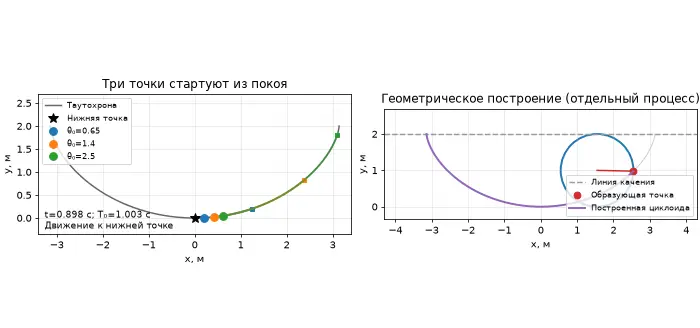
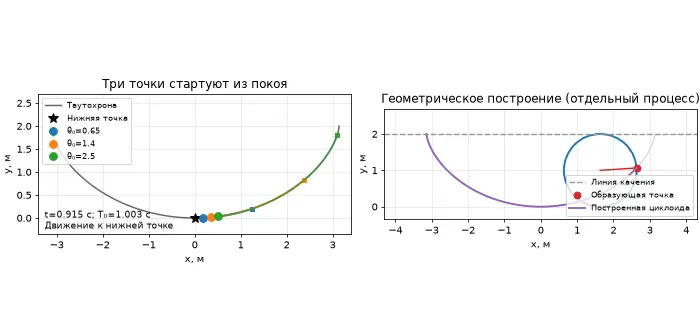
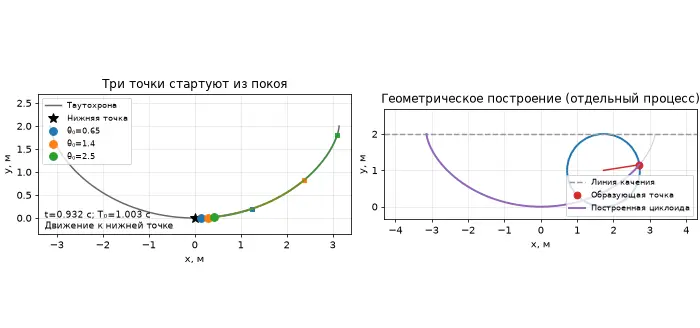
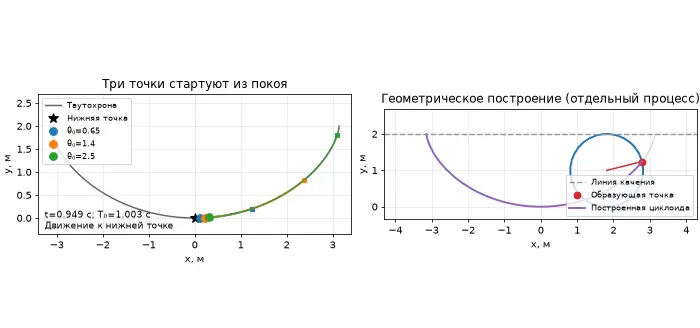
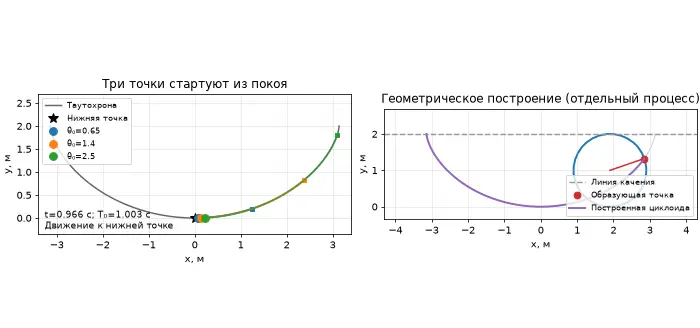
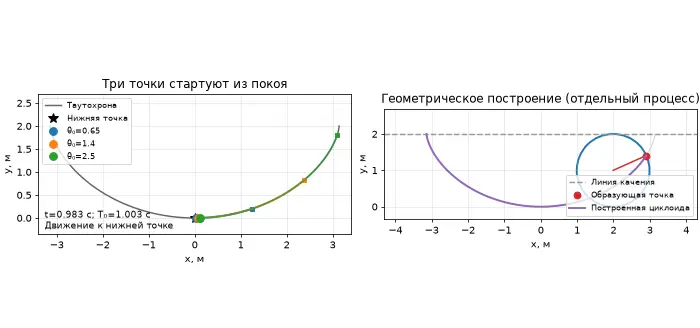
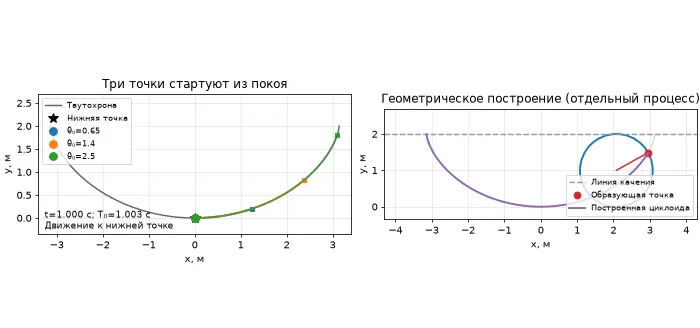
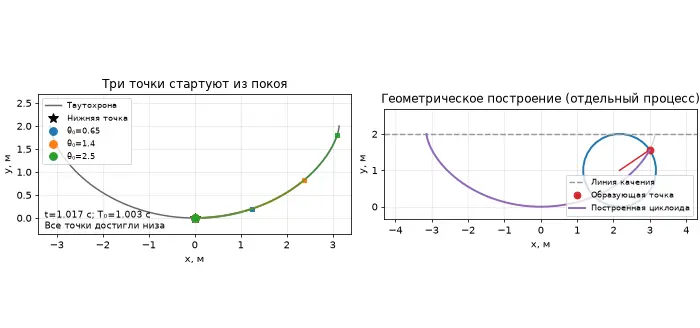
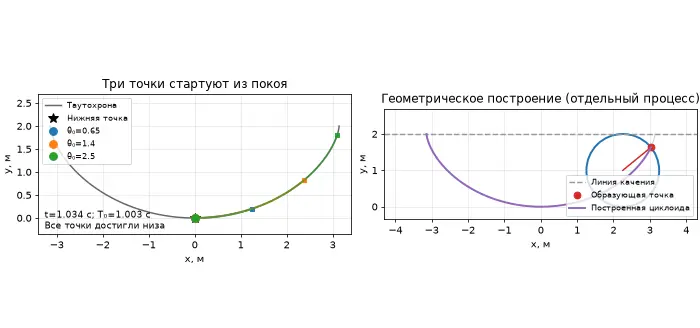
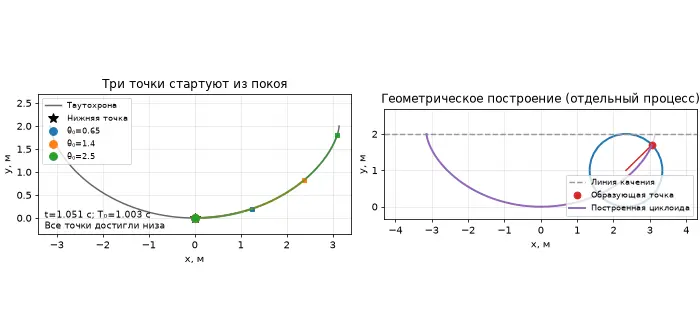
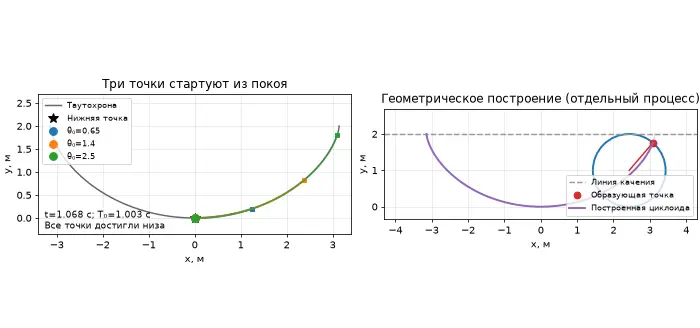
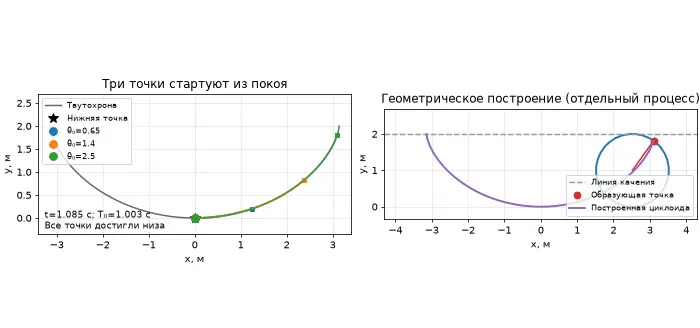
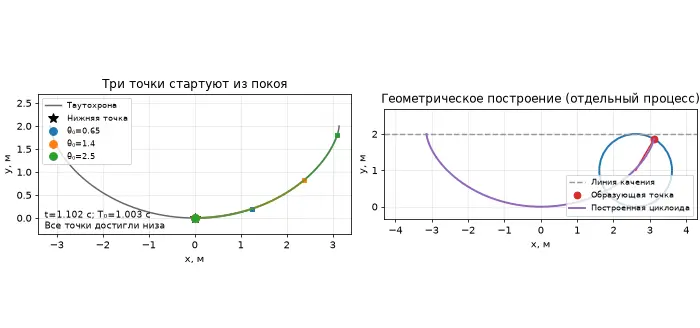
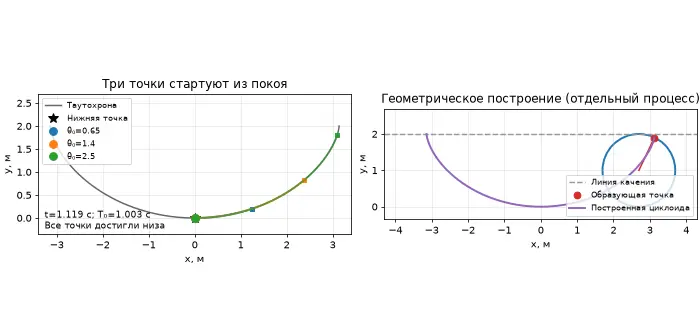
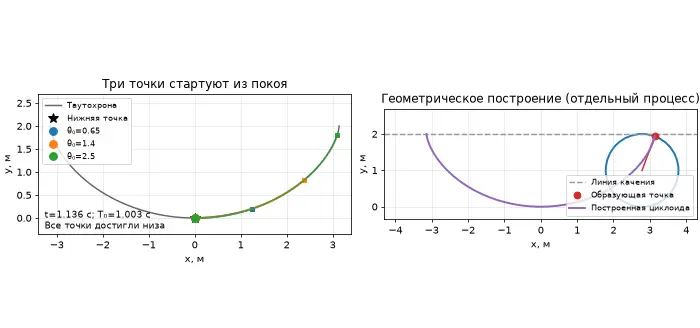
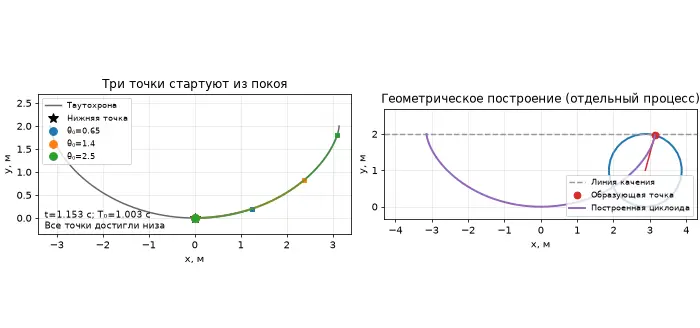
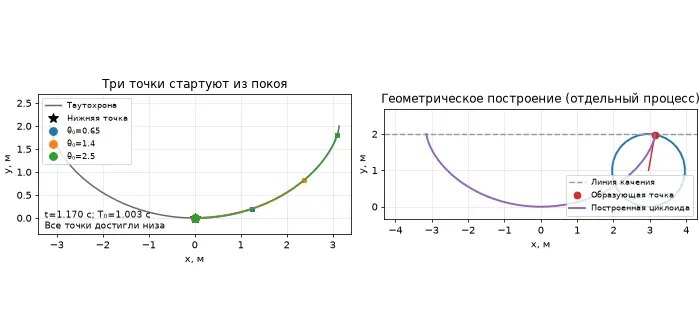
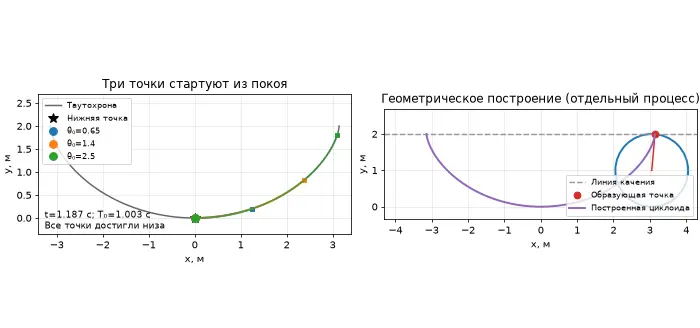
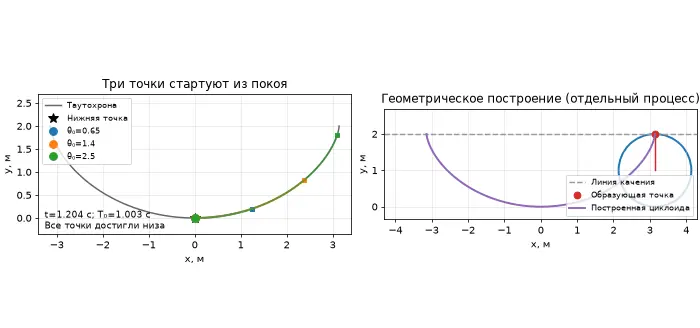

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, HTML
from pathlib import Path
from IPython import get_ipython
from PIL import Image as PILImage
import base64
import io
import re

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 70, 'animation.embed_limit': 100})
Path('figures').mkdir(exist_ok=True)
Path('animations').mkdir(exist_ok=True)


def export_animation(fig, update, name, frames=72):
    # HTML содержит штатные кнопки воспроизведения, паузы и выбора кадра.
    animation = FuncAnimation(fig, update, frames=frames, interval=50,
                              blit=False, repeat=False)
    html = animation.to_jshtml(fps=20, default_mode='once')
    # Компактные кадры сохраняют автономность HTML и уменьшают размер ноутбука.
    def compact_frame(match):
        raw = base64.b64decode(match.group(1).replace('\\', '').replace('\n', ''))
        buffer = io.BytesIO()
        with PILImage.open(io.BytesIO(raw)) as image:
            image.convert('RGB').save(buffer, format='WEBP', quality=72, method=4)
        return 'data:image/webp;base64,'+base64.b64encode(buffer.getvalue()).decode('ascii')
    html = re.sub(r'data:image/png;base64,([A-Za-z0-9+/=\\\n]+)', compact_frame, html)
    Path(f'animations/{name}.html').write_text(
        '<!doctype html><html lang="ru"><meta charset="utf-8">'
        f'<title>{name}</title><body>{html}</body></html>', encoding='utf-8')
    # GIF можно посмотреть прямо в README на GitHub без запуска Python.
    animation.save(f'animations/{name}.gif', writer=PillowWriter(fps=20), dpi=70)
    plt.close(fig)
    display(HTML(html))
    return animation


# 3.4: точная таутохрона и геометрическое построение циклоиды.
from scipy.integrate import quad

g, R = 9.81, 1.0
omega = np.sqrt(g/(4*R))
T0 = np.pi*np.sqrt(R/g)
theta = np.linspace(-np.pi, np.pi, 700)


def cycloid(theta):
    return R*(theta+np.sin(theta)), R*(1-np.cos(theta))


initial_angles = np.array([0.65, 1.4, 2.5])
s0 = 4*R*np.sin(initial_angles/2)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
print(f'3.4: теоретическое время спуска T₀ = {T0:.10f} с')
for angle, length in zip(initial_angles, s0):
    height = R*(1-np.cos(angle))
    # Независимая квадратура времени вдоль исходной циклоиды.
    numeric_time = quad(lambda th: 2*R*np.cos(th/2)/np.sqrt(
        2*g*(height-R*(1-np.cos(th)))), 0, angle, epsabs=1e-10)[0]
    assert abs(numeric_time-T0) < 2e-8
    print(f'θ₀={angle:.2f} рад; h={height:.6f} м; T={numeric_time:.10f} с')

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), constrained_layout=True)
xx, yy = cycloid(theta)
axes[0].plot(xx, yy, color='0.35', label='Циклоида')
for angle, color in zip(initial_angles, colors):
    th = np.linspace(0, angle, 150)
    x, y = cycloid(th)
    axes[0].plot(x, y, lw=3, color=color, label=f'θ₀={angle:g}')
    axes[0].plot(x[-1], y[-1], 'o', color=color)
axes[0].plot(0, 0, 'k*', ms=10)
axes[0].set(xlabel='x, м', ylabel='y, м', title='Старты из разных высот')
axes[0].set_aspect('equal')
tt = np.linspace(0, T0, 300)
for length, color, angle in zip(s0, colors, initial_angles):
    axes[1].plot(tt, length*np.cos(omega*tt), color=color, label=f'θ₀={angle:g}')
axes[1].axvline(T0, color='0.4', ls='--', label=f'T₀={T0:.3f} с')
axes[1].set(xlabel='t, с', ylabel='s(t), м', title='Одновременный приход к s=0')
ax = axes[2]
ax.plot(xx, yy, color='#9467bd', label='След точки P')
ax.axhline(2*R, color='0.5', ls='--', label='Линия качения')
for j, th in enumerate([-2.0, 0.0, 2.0]):
    cx, cy = R*th, R
    ax.add_patch(plt.Circle((cx, cy), R, fill=False, alpha=.6, color='#1f77b4',
                            label='Образующая окружность' if j == 0 else None))
    px, py = cycloid(th)
    ax.plot([cx, px], [cy, py], color='#d62728', lw=1)
    ax.plot(px, py, 'o', color='#d62728')
ax.set(xlabel='x, м', ylabel='y, м', title='Качение без скольжения')
ax.set_aspect('equal')
for ax in axes: ax.grid(alpha=.3); ax.legend(fontsize=7)
fig.savefig('figures/3_4_tautochrone.png', dpi=170)
plt.show()

frames = 72
times = np.linspace(0, 1.2*T0, frames)
fig, (ax, ax_roll) = plt.subplots(1, 2, figsize=(10, 4.7), constrained_layout=True)
ax.plot(xx, yy, color='0.4', label='Таутохрона')
ax.plot(0, 0, 'k*', ms=10, label='Нижняя точка')
points, trails = [], []
for angle, color in zip(initial_angles, colors):
    xstart, ystart = cycloid(angle)
    ax.plot(xstart, ystart, 's', color=color, ms=4)
    point, = ax.plot([], [], 'o', color=color, ms=8, label=f'θ₀={angle:g}')
    trail, = ax.plot([], [], color=color, lw=2, alpha=.6)
    points.append(point); trails.append(trail)
ax.set(xlim=(-3.4, 3.4), ylim=(-.35, 2.7), xlabel='x, м', ylabel='y, м',
       title='Три точки стартуют из покоя')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='upper left')
info = ax.text(.02, .04, '', transform=ax.transAxes, fontsize=9)
ax_roll.axhline(2*R, color='0.6', ls='--', label='Линия качения')
ax_roll.plot(xx, yy, color='0.8', lw=1)
wheel = plt.Circle((-np.pi*R, R), R, fill=False, color='#1f77b4', lw=2)
ax_roll.add_patch(wheel)
radius, = ax_roll.plot([], [], color='#d62728')
marker, = ax_roll.plot([], [], 'o', color='#d62728', ms=7, label='Образующая точка')
wheel_trail, = ax_roll.plot([], [], color='#9467bd', lw=2, label='Построенная циклоида')
ax_roll.set(xlim=(-4.3, 4.3), ylim=(-.35, 2.7), xlabel='x, м', ylabel='y, м',
            title='Геометрическое построение (отдельный процесс)')
ax_roll.set_aspect('equal'); ax_roll.grid(alpha=.3); ax_roll.legend(fontsize=8, loc='lower right')


def update_34(i):
    clipped_t = np.minimum(times[:i+1], T0)
    for length, point, trail in zip(s0, points, trails):
        s = length*np.cos(omega*clipped_t)
        th = 2*np.arcsin(np.clip(s/(4*R), -1, 1))
        x, y = cycloid(th)
        point.set_data([x[-1]], [y[-1]]); trail.set_data(x, y)
    status = 'Все точки достигли низа' if times[i] >= T0 else 'Движение к нижней точке'
    info.set_text(f't={times[i]:.3f} с; T₀={T0:.3f} с\n{status}')
    rolling_theta = np.linspace(-np.pi, -np.pi+2*np.pi*i/(frames-1), max(2, 5*i+1))
    px, py = cycloid(rolling_theta)
    center = (R*rolling_theta[-1], R)
    wheel.center = center
    radius.set_data([center[0], px[-1]], [center[1], py[-1]])
    marker.set_data([px[-1]], [py[-1]]); wheel_trail.set_data(px, py)
    return []


animation_34 = export_animation(fig, update_34, '3_4_tautochrone', frames)


## 3.5

**Математический маятник.** Точечная масса $m$ закреплена на невесомом нерастяжимом стержне длины $\ell$; трения нет. Угол $\theta$ отсчитываем от вертикали вниз. Координаты груза $(\ell\sin\theta,-\ell\cos\theta)$.

**Уравнение движения.** Касательная составляющая силы тяжести равна $-mg\sin\theta$, а натяжение направлено радиально:
$$m\ell\ddot\theta=-mg\sin\theta,\qquad
\boxed{\ddot\theta+\omega_0^2\sin\theta=0},\quad \omega_0=\sqrt{g/\ell}.$$
Умножение на $m\ell^2\dot\theta$ даёт интеграл энергии
$$\boxed{E=\frac{m\ell^2\dot\theta^2}{2}+mg\ell(1-\cos\theta)}.$$
В переменных $(\theta,p)$, $p=m\ell^2\dot\theta$, гамильтониан равен $H=p^2/(2m\ell^2)+mg\ell(1-\cos\theta)$.

**Малые колебания.** При $|\theta|\ll1$ заменяем $\sin\theta$ на $\theta$:
$$\theta_{\mathrm{lin}}(t)=\theta_0\cos\omega_0t+
\frac{\dot\theta_0}{\omega_0}\sin\omega_0t,\qquad
\boxed{T_{\mathrm{lin}}=2\pi\sqrt{\ell/g}}.$$
При больших амплитудах линейная модель завышает частоту, и её фаза постепенно расходится с нелинейным решением.

**Точное решение при колебаниях.** Пусть старт из покоя происходит при $\theta(0)=A$, $0<A<\pi$. Введём $k=\sin(A/2)$ и определим полный эллиптический интеграл с параметром $m_e$:
$$K(m_e)=\int_0^{\pi/2}\frac{du}{\sqrt{1-m_e\sin^2u}}.$$
Из энергии
$$\dot\theta^2=4\omega_0^2\left(k^2-\sin^2\frac\theta2\right).$$
Замена $\sin(\theta/2)=k\sin\varphi$ даёт для первой четверти движения
$$\omega_0t=K(k^2)-F(\varphi\mid k^2),\quad
F(\varphi\mid m_e)=\int_0^\varphi\frac{du}{\sqrt{1-m_e\sin^2u}}.$$
Обращая этот интеграл через функцию Якоби $\operatorname{sn}$, получаем решение на всём колебательном режиме:
$$\boxed{\theta(t)=2\arcsin\left[k\operatorname{sn}\bigl(K(k^2)-\omega_0t\mid k^2\bigr)\right]},$$
$$\boxed{T(A)=4\sqrt{\ell/g}\,K\!\left(\sin^2\frac A2\right)}.$$
Здесь $K$ принимает **параметр $k^2$**, что соответствует `scipy.special.ellipk` и `ellipj`. При $A\to0$ получаем $T\to T_{\mathrm{lin}}$, а при $A\to\pi$ период стремится к бесконечности. Для малых $A$ в радианах:
$$T(A)=T_{\mathrm{lin}}\left(1+\frac{A^2}{16}+\frac{11A^4}{3072}+O(A^6)\right).$$

**Фазовый портрет.** В координатах $\Omega=\dot\theta$:
$$\dot\theta=\Omega,\qquad \dot\Omega=-\omega_0^2\sin\theta.$$
Точки $(2\pi n,0)$ являются устойчивыми центрами, $((2n+1)\pi,0)$ — неустойчивыми седлами. При $0<E<2mg\ell$ получаются замкнутые колебательные орбиты; $E=0$ соответствует покою внизу. При $E>2mg\ell$ угол монотонно возрастает или убывает: это вращения стержневого маятника.

Сепаратриса имеет энергию $E_s=2mg\ell$:
$$\boxed{\Omega^2=4\omega_0^2\cos^2(\theta/2)},\qquad
\Omega=\pm2\omega_0|\cos(\theta/2)|.$$
За исключением самого неустойчивого равновесия, движение на ней асимптотически приближается к верхнему положению. На $-\pi<\theta<\pi$ один из её вариантов:
$$\theta_s(t)=4\arctan e^{\omega_0(t-t_*)}-\pi.$$

Для вращений удобно ввести $\varepsilon=E/(mg\ell)>2$. Точное неявное решение задаётся эллиптической квадратурой
$$t-t_0=\pm\frac1{\omega_0}\int_{\theta_0}^{\theta}
\frac{d\eta}{\sqrt{2(\varepsilon-1+\cos\eta)}}.$$
Время полного оборота:
$$T_{\mathrm{rot}}=\frac{4}{\omega_0\sqrt{2\varepsilon}}K(2/\varepsilon).$$
Угол понимается на цилиндре $\theta\bmod2\pi$, поэтому вращательные орбиты на плоском портрете пересекают края окна.

Код сравнивает численное решение `solve_ivp` с точной формулой и линейной моделью, проверяет сохранение энергии, строит фазовые орбиты и зависимость периода от амплитуды. Анимация синхронно показывает малые колебания ($10^\circ$), большие колебания ($120^\circ$) и вращение при $\dot\theta(0)=2.4\omega_0$.


3.5: линейный период Tлин = 2.0060666807 с
A=10°: T=2.00989263 с; ошибка точной формулы=2.47e-15 рад; Δε=4.44e-16
A=60°: T=2.15287467 с; ошибка точной формулы=6.47e-14 рад; Δε=9.25e-14
A=120°: T=2.75408983 с; ошибка точной формулы=7.81e-13 рад; Δε=9.52e-13
A=170°: T=4.89352427 с; ошибка точной формулы=1.43e-11 рад; Δε=1.60e-12
Вращение: ε=2.880>2; максимальный дрейф ε=4.14e-12.


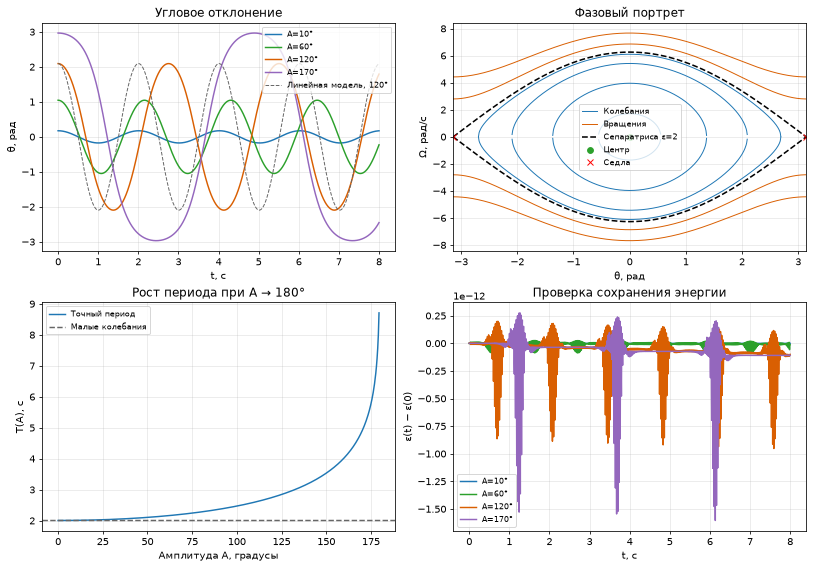


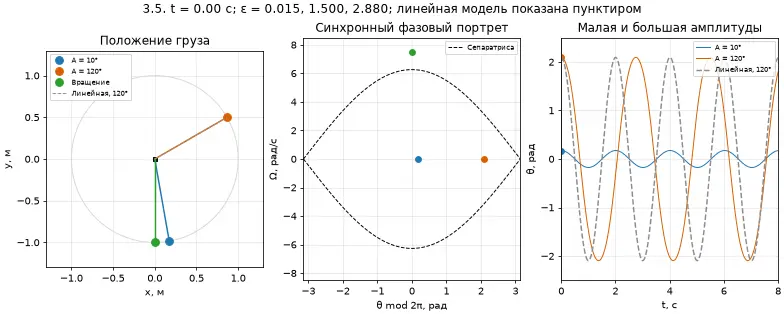
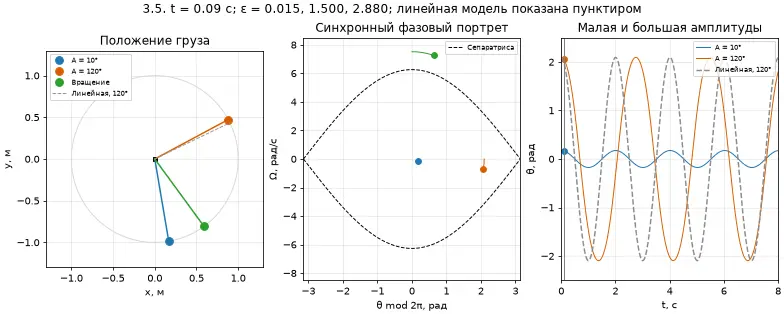
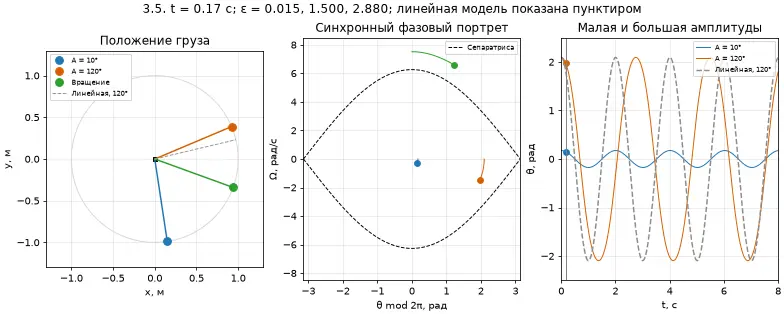
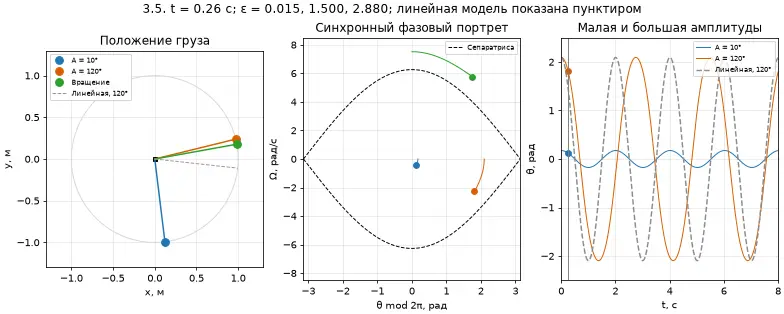
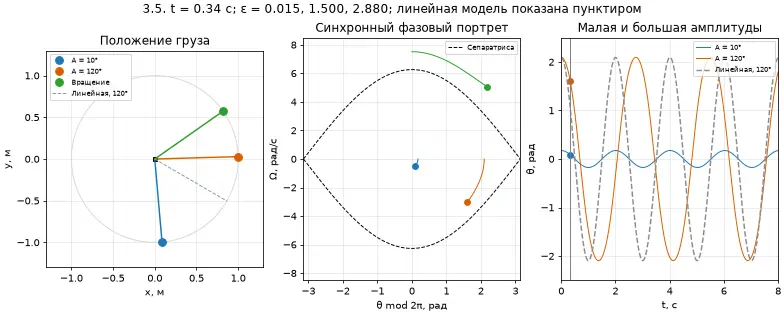
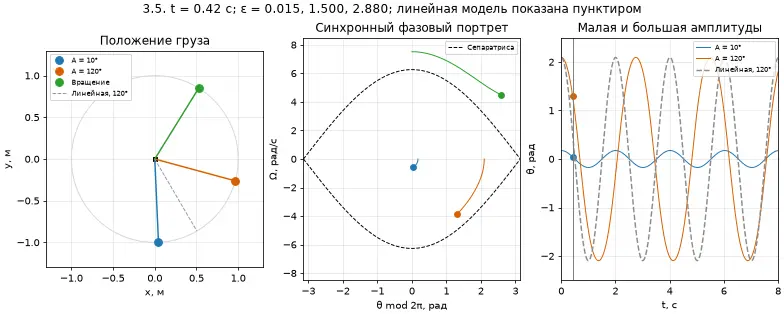
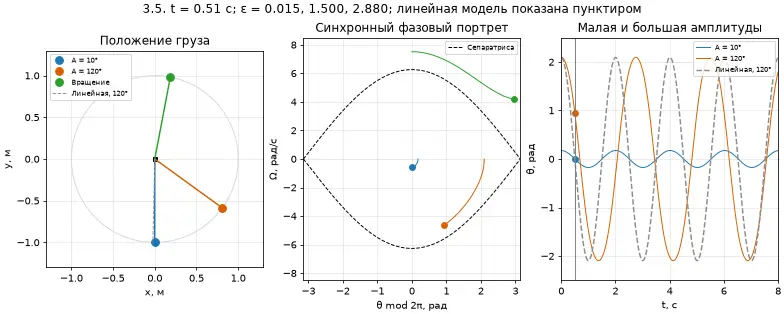
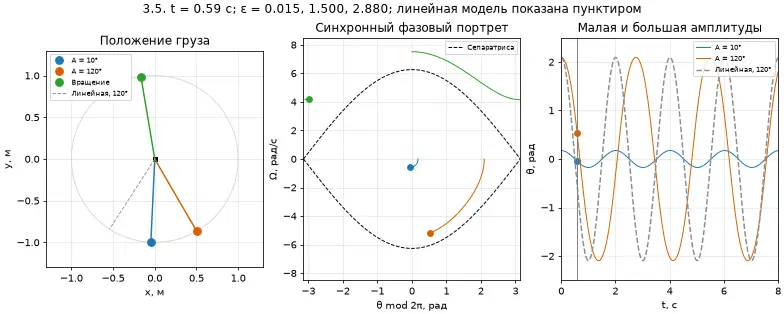
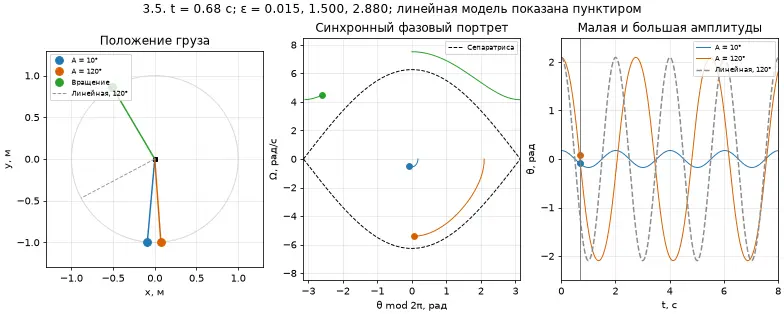
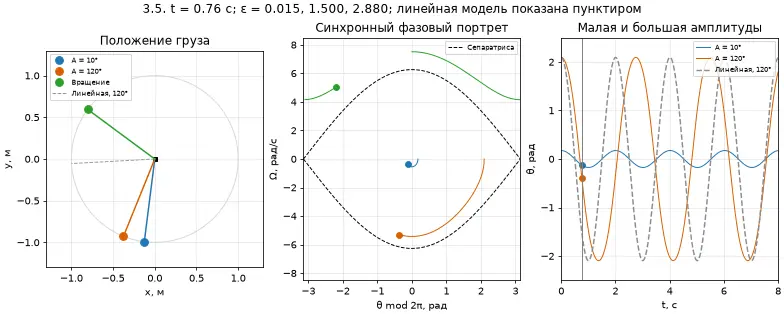
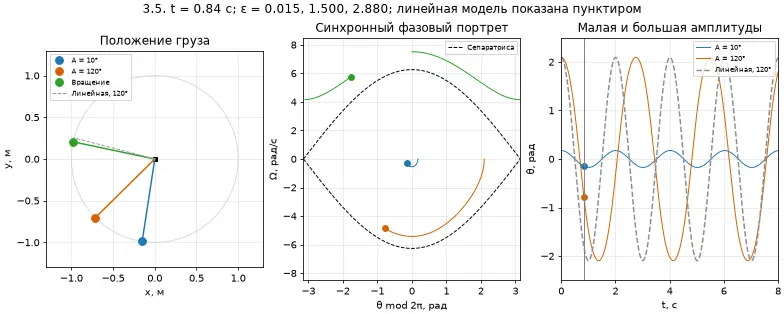
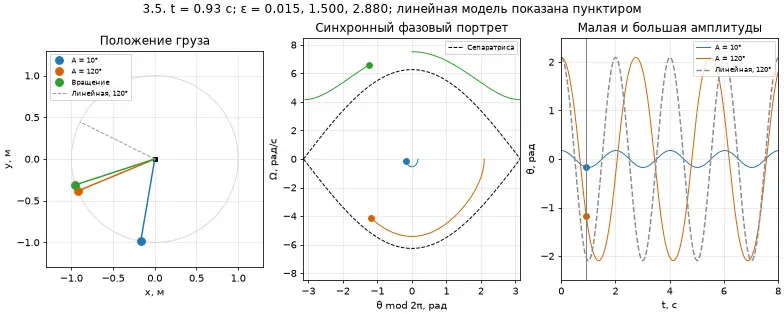
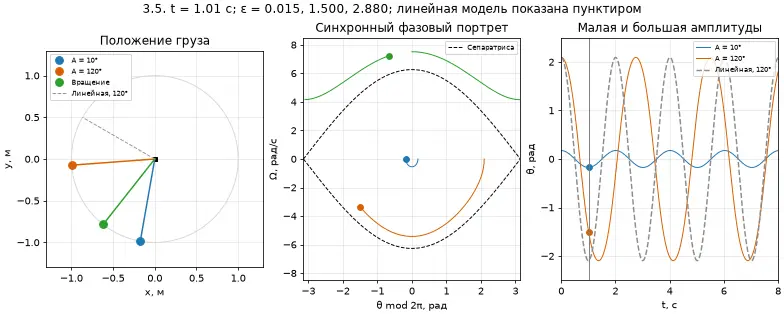
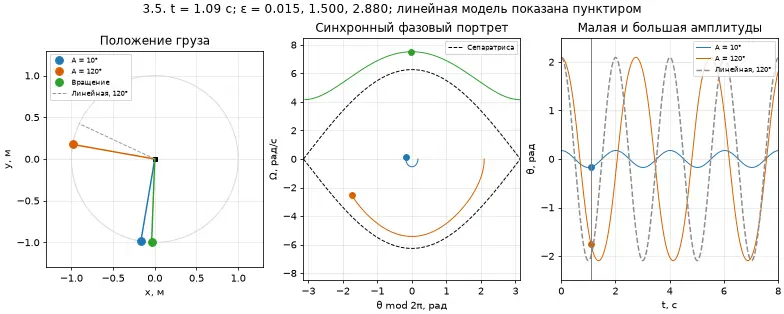
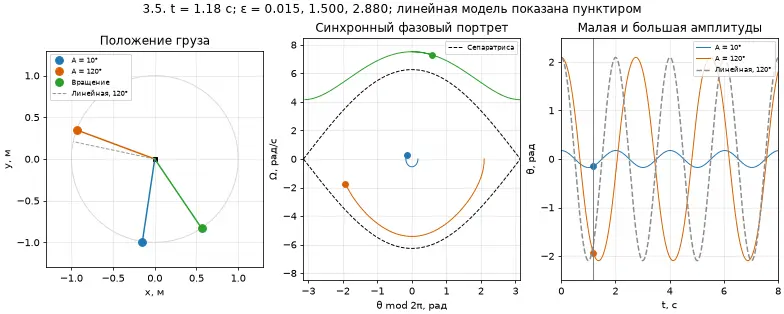
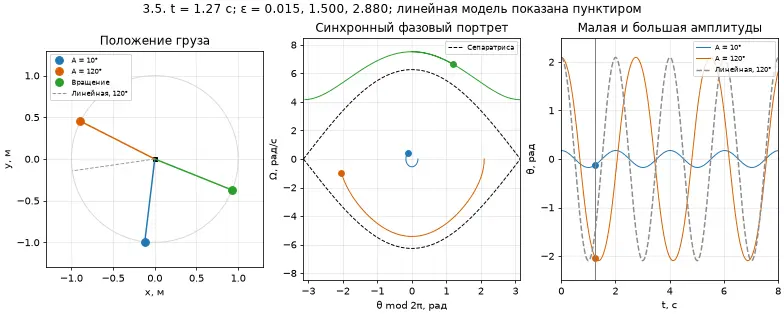
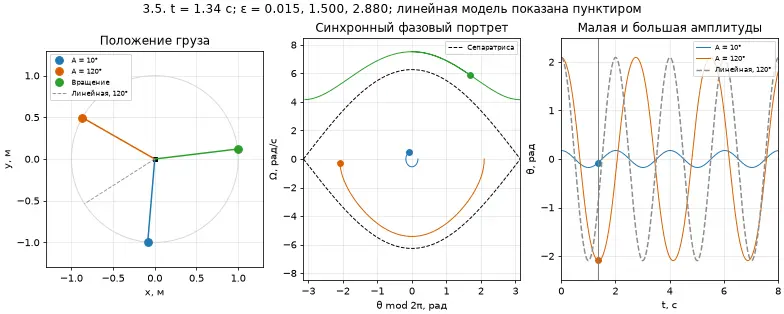
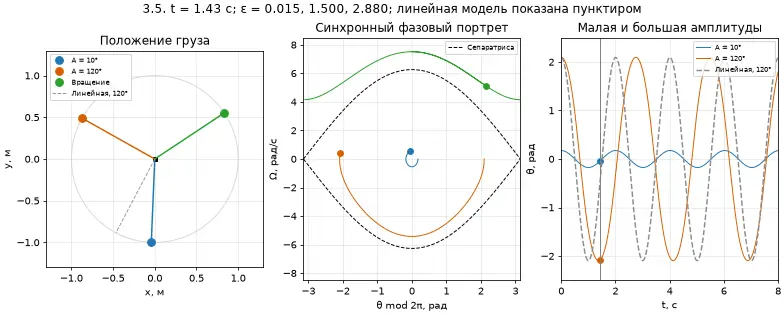
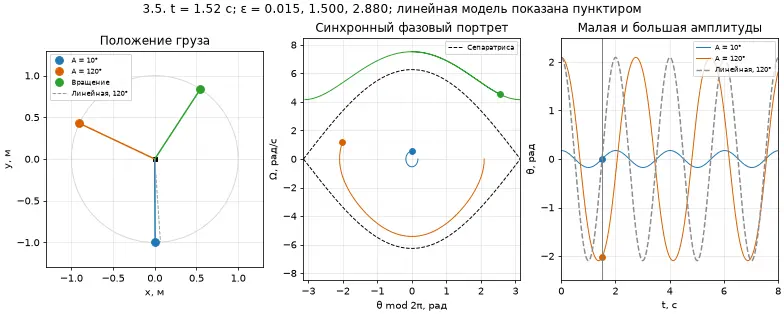
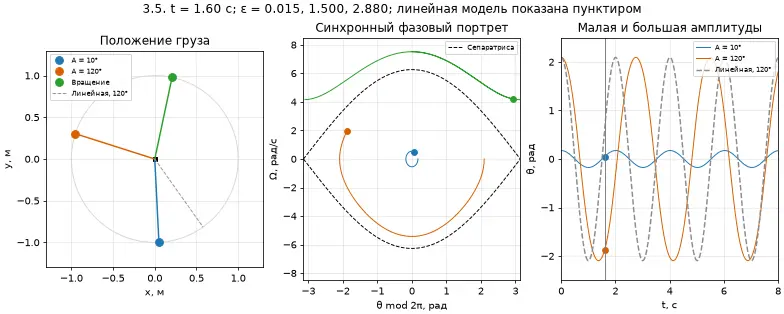
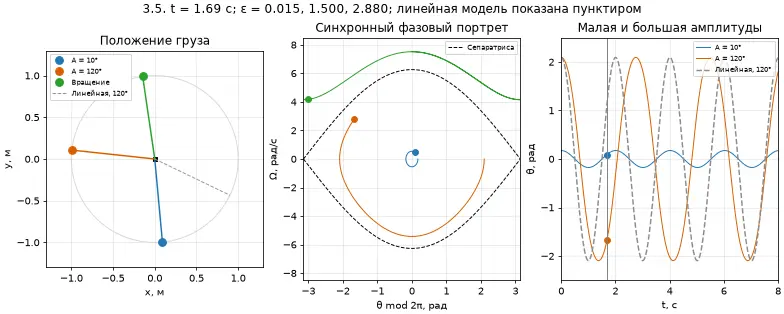
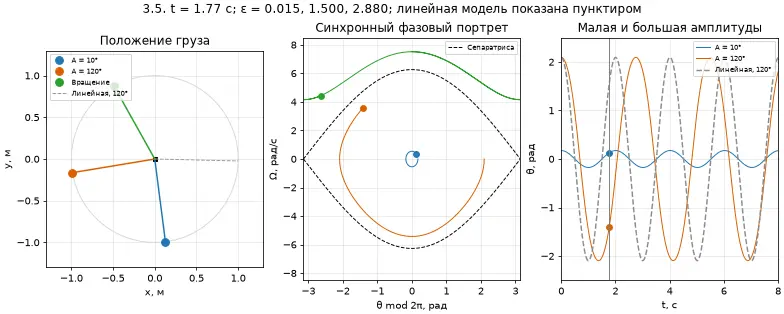
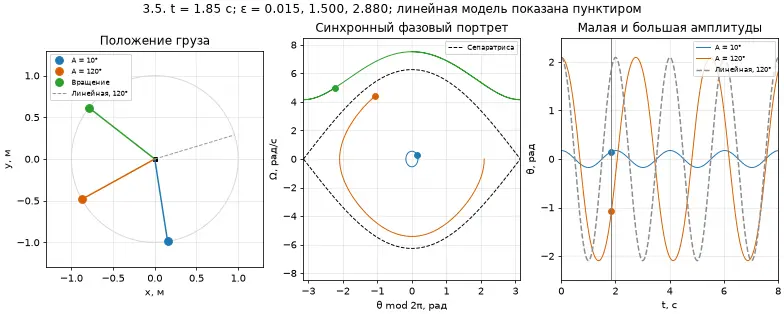
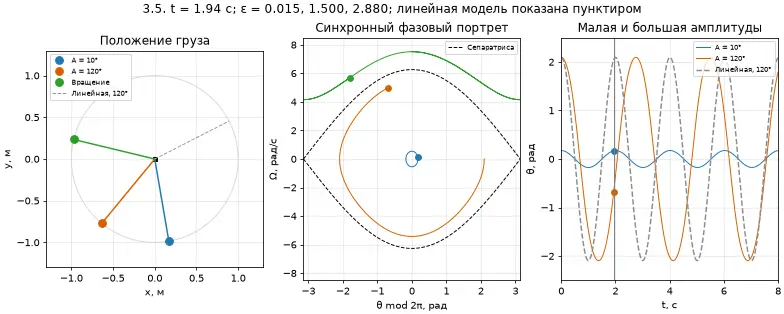
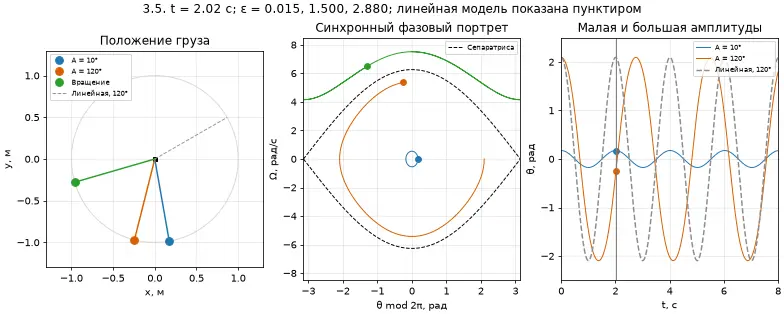
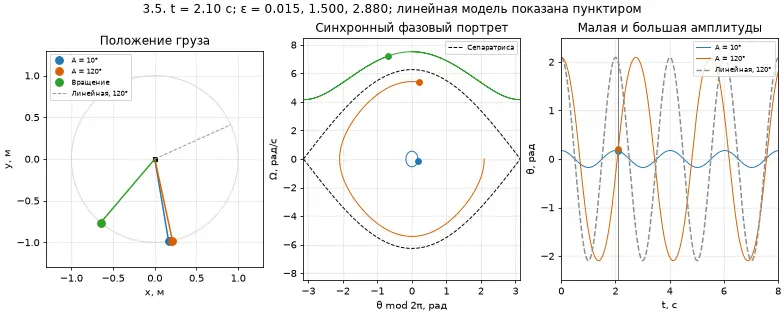
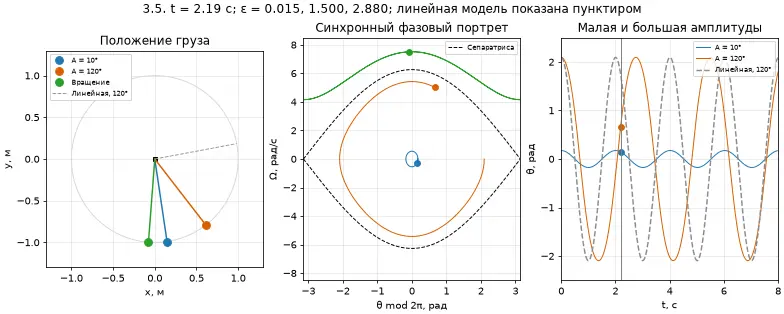
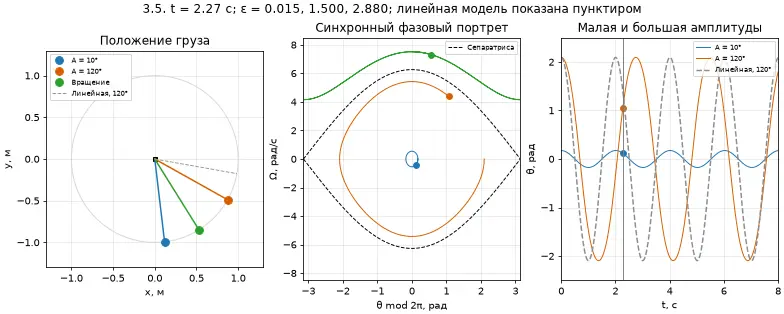
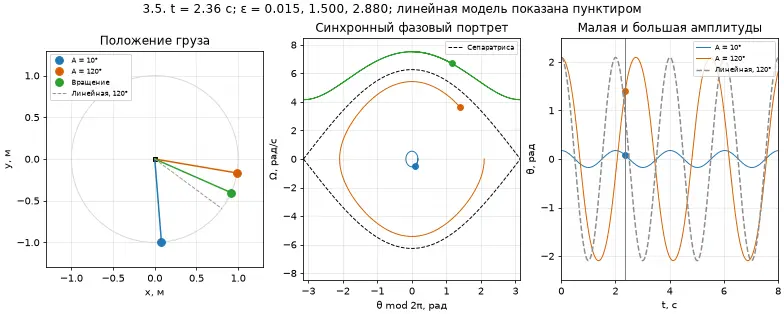
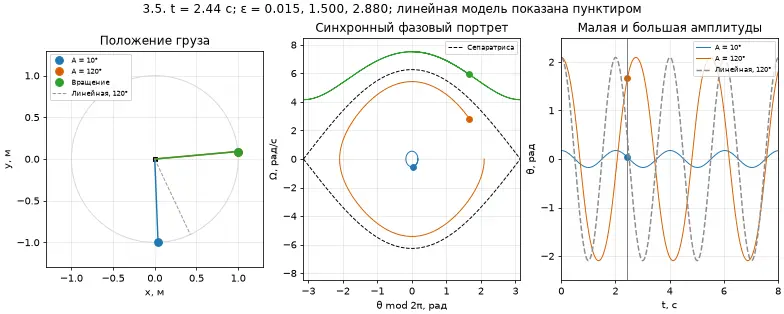
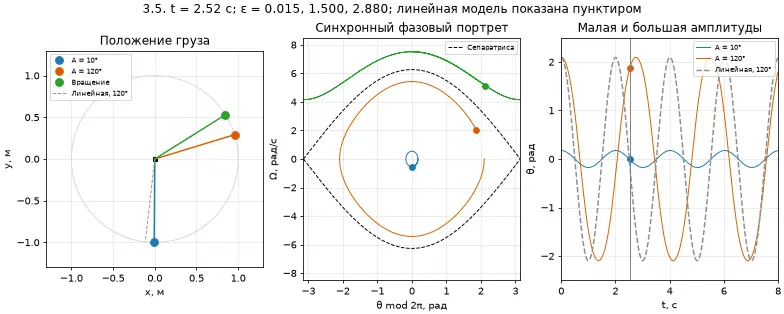
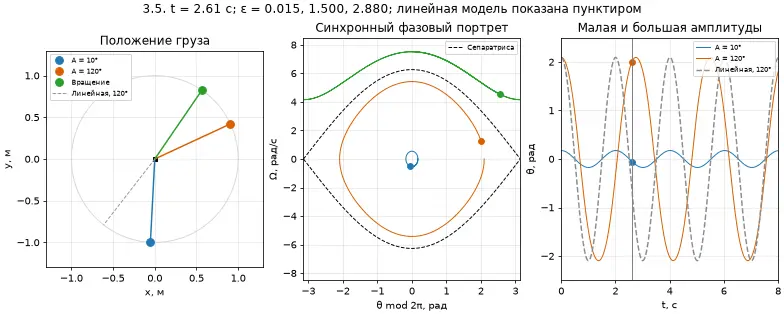
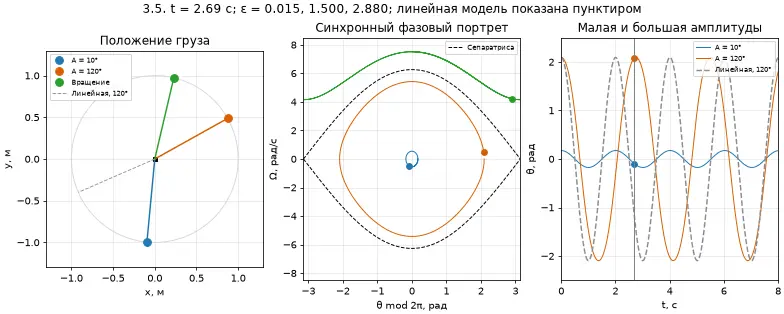
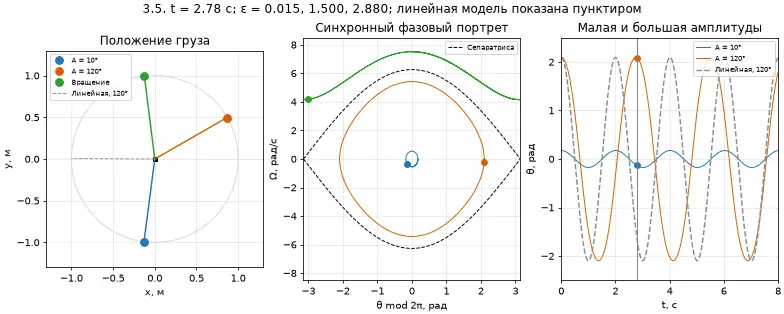
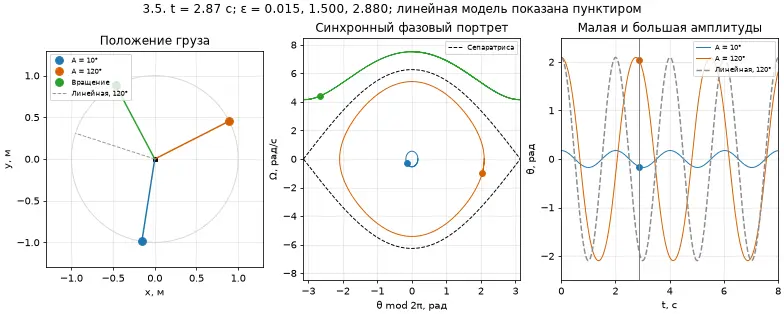
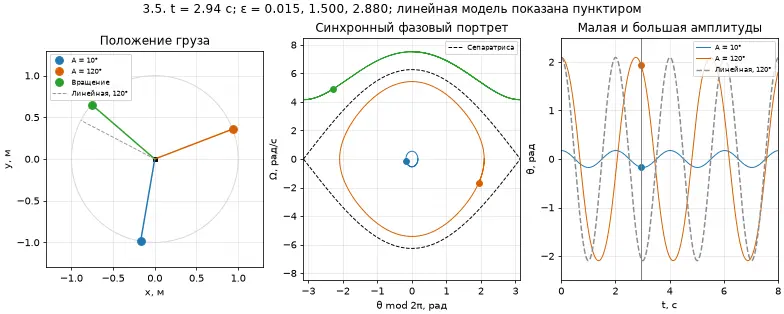
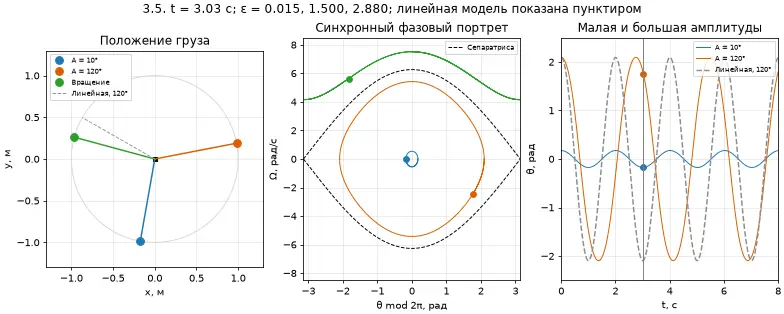
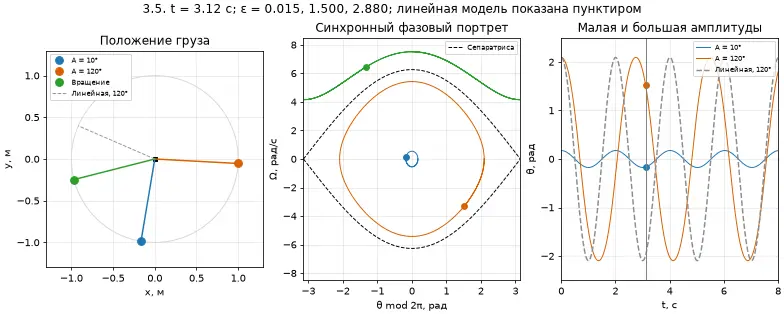
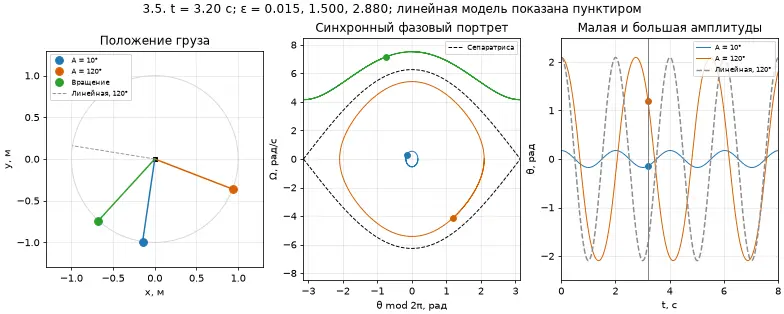
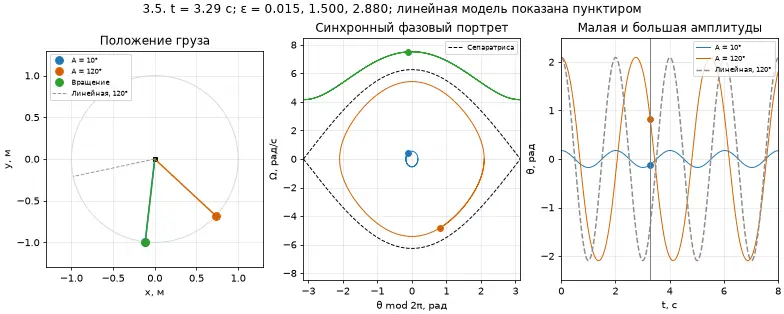
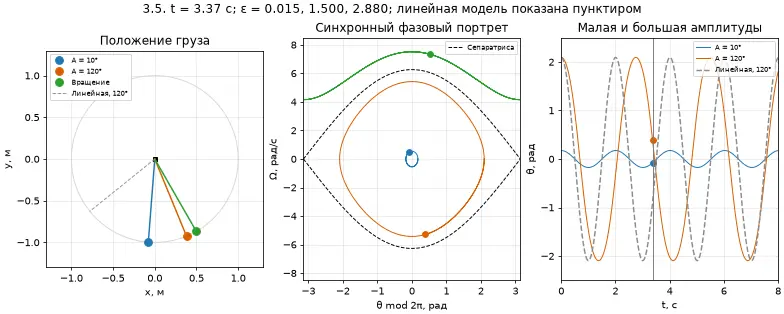
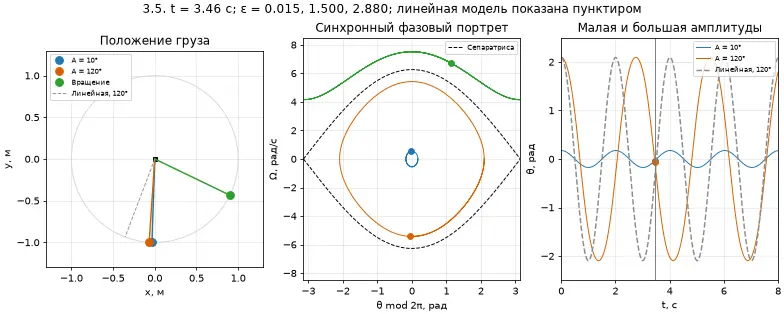
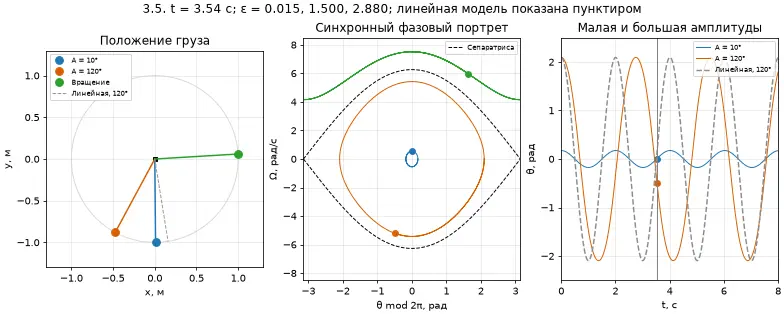
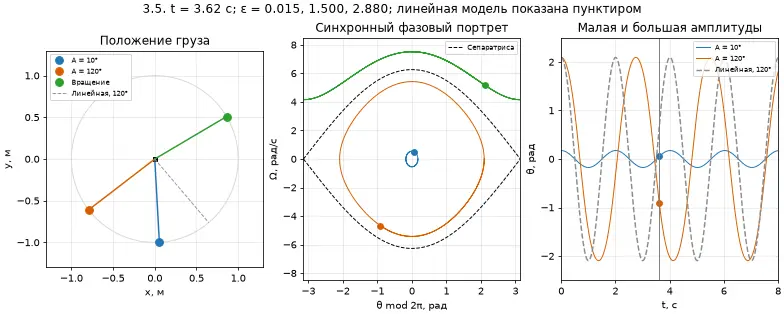
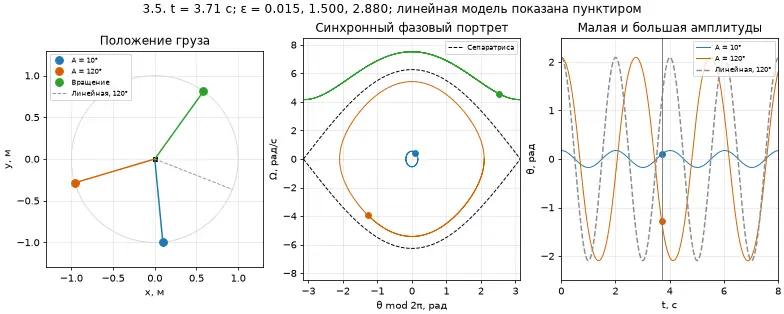
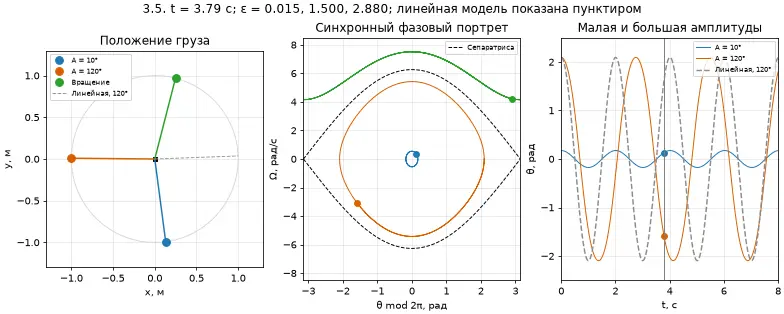
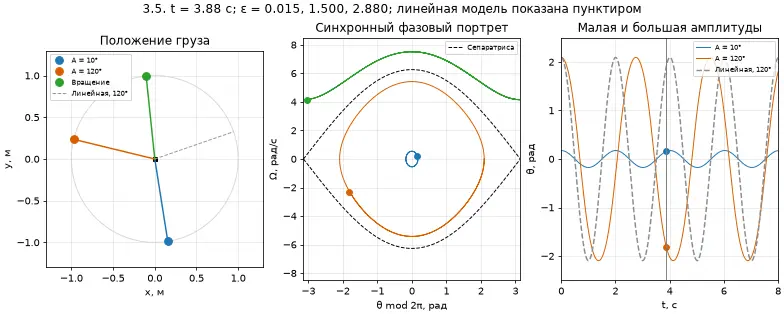
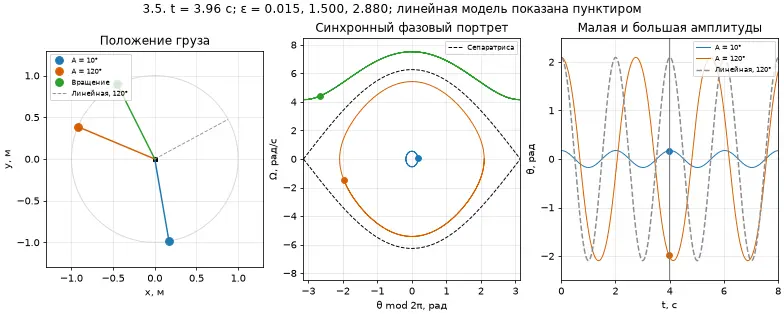
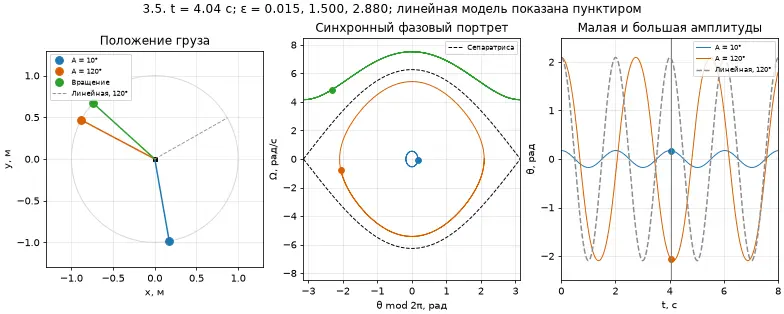
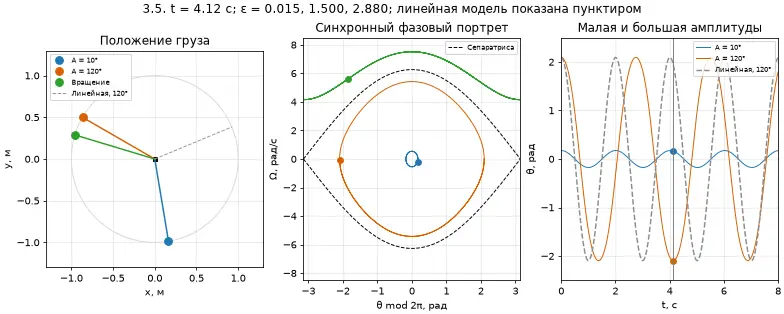
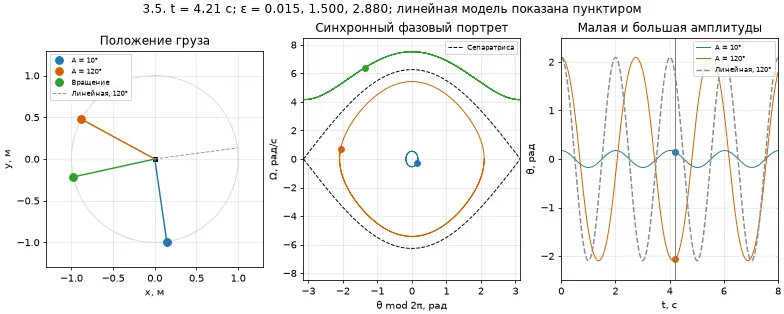
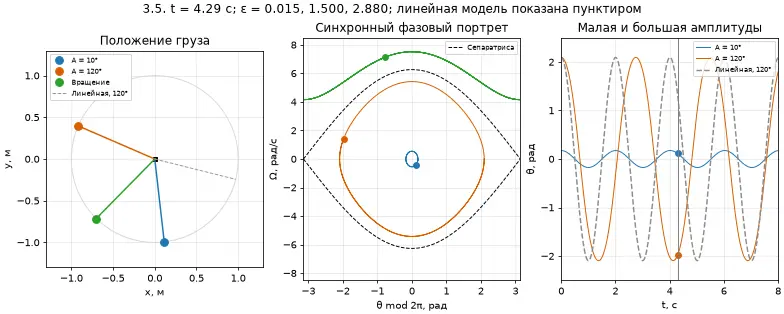
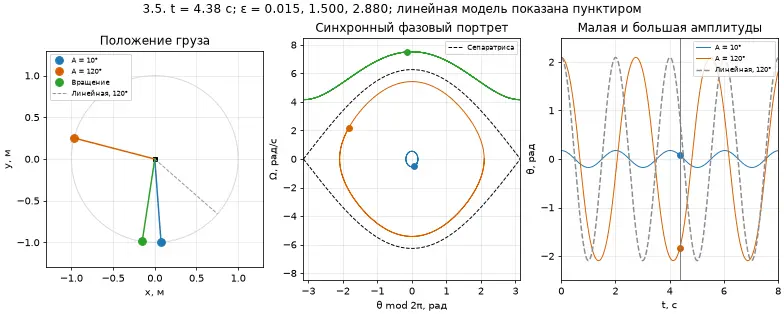
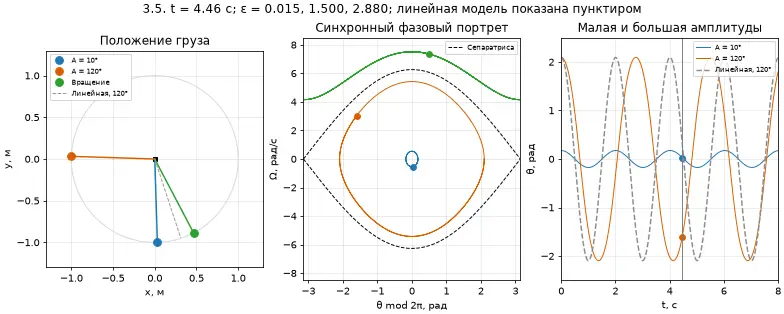
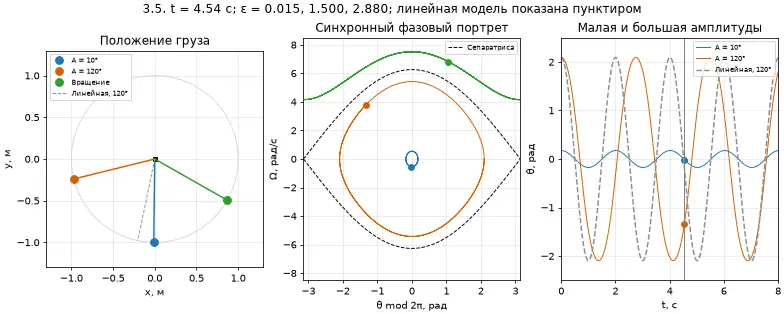
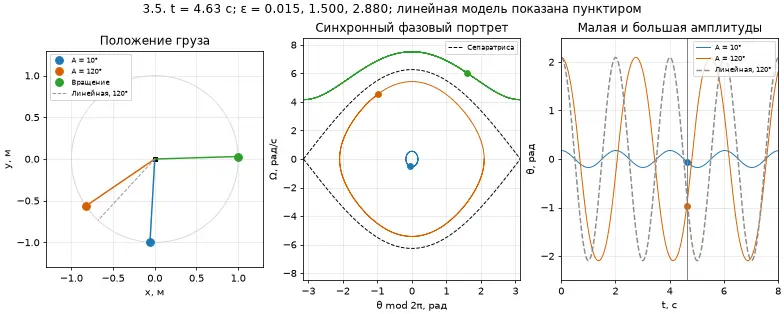
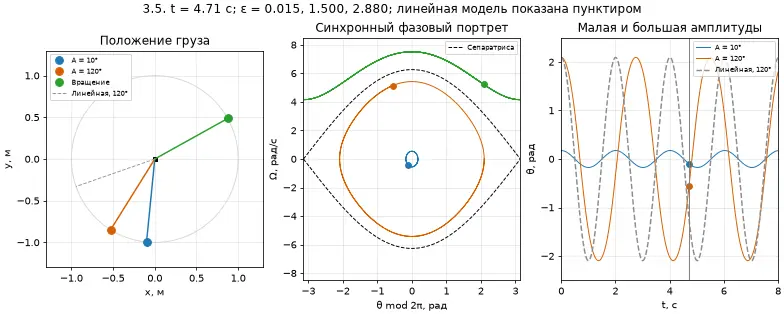
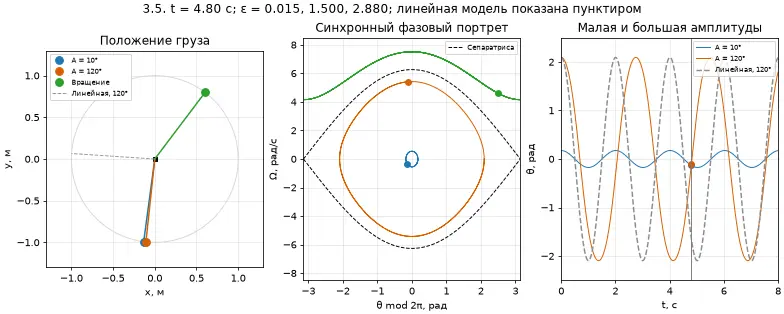
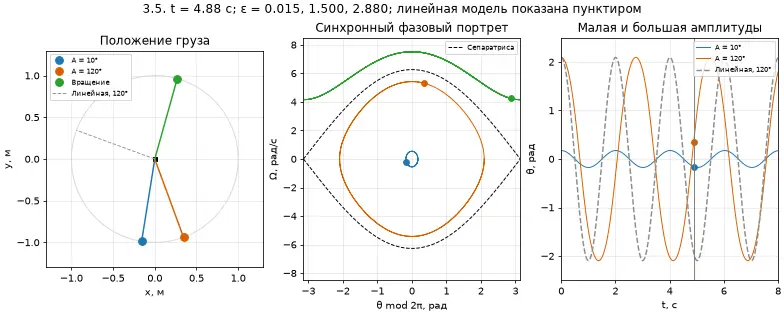
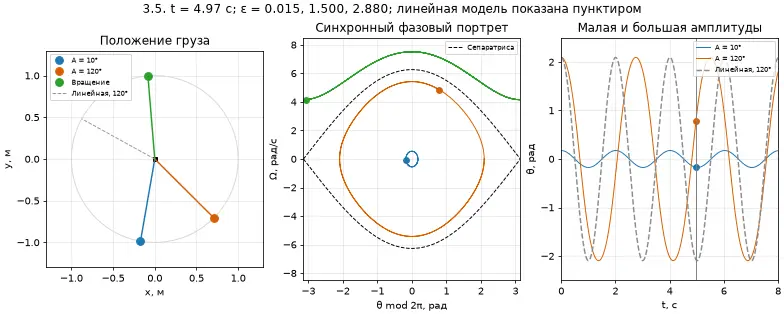
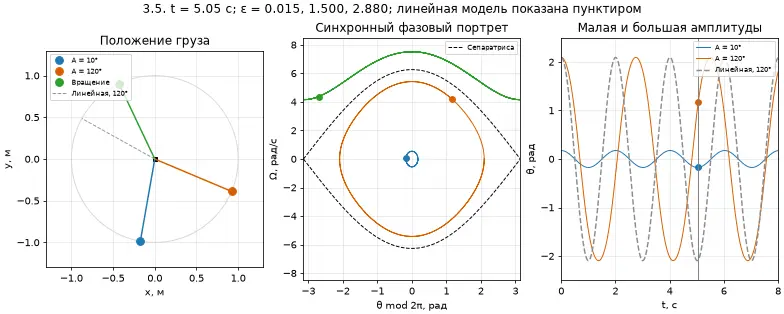
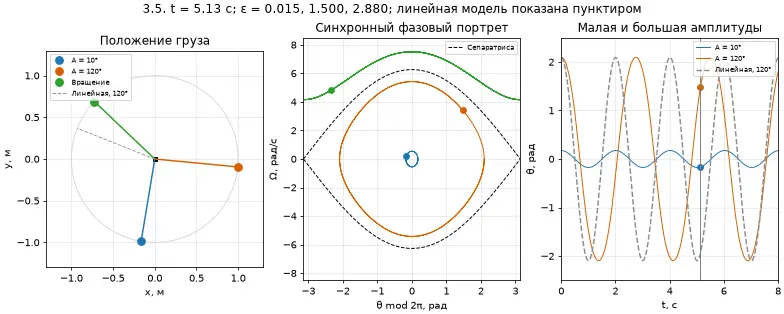
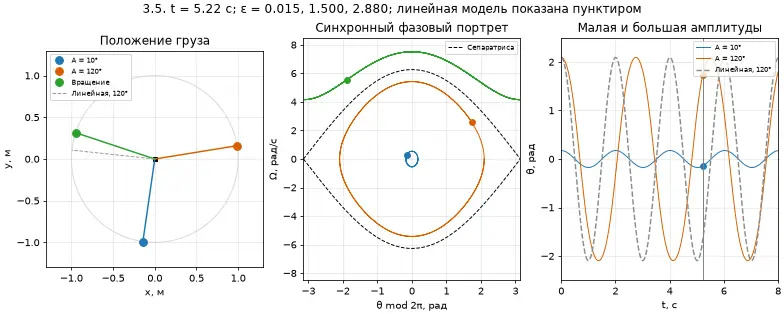
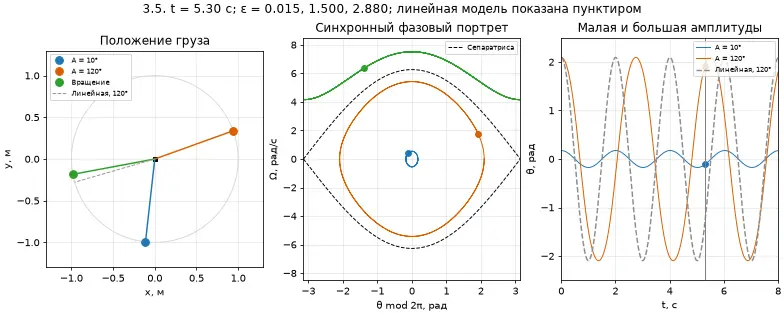
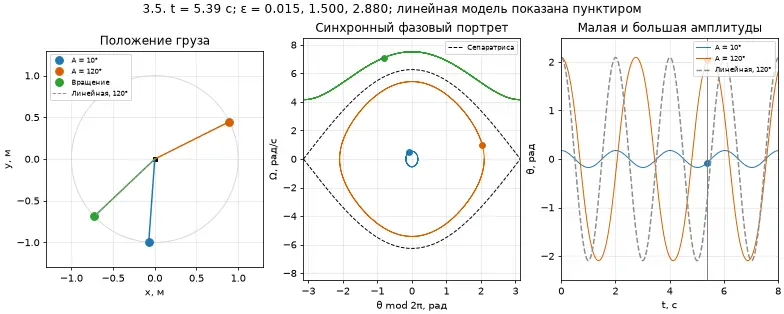
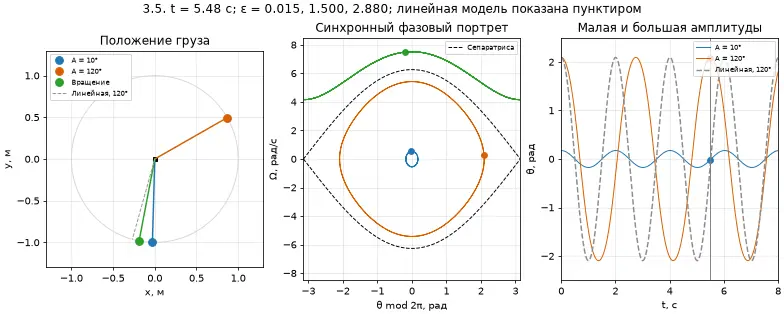
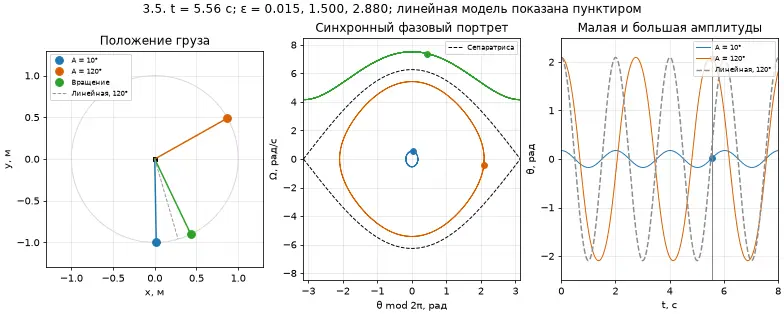
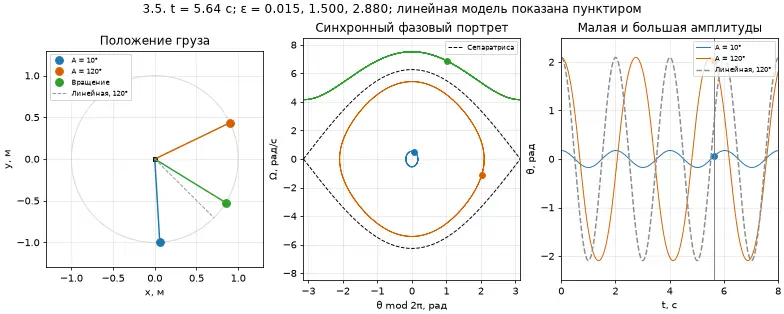
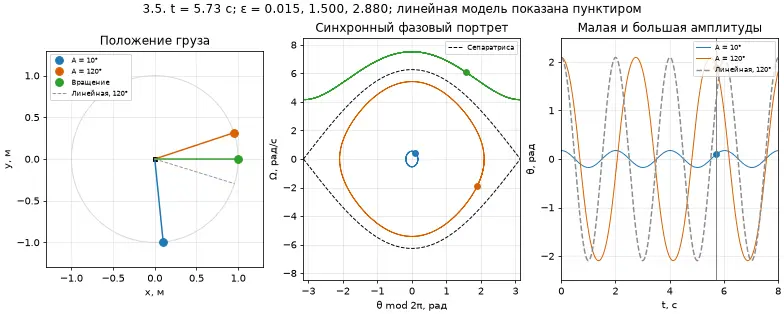
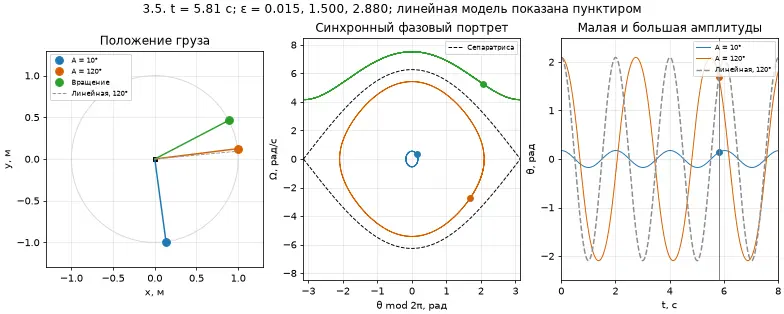
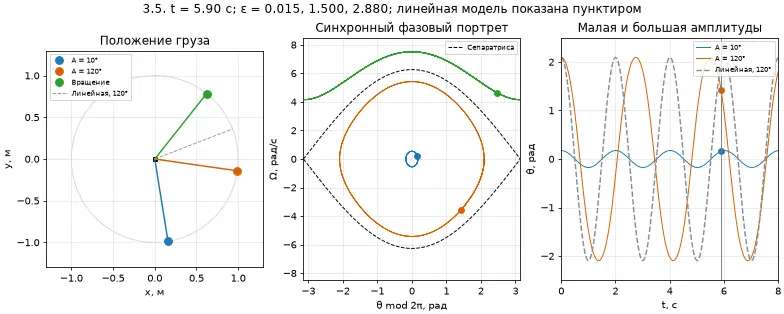
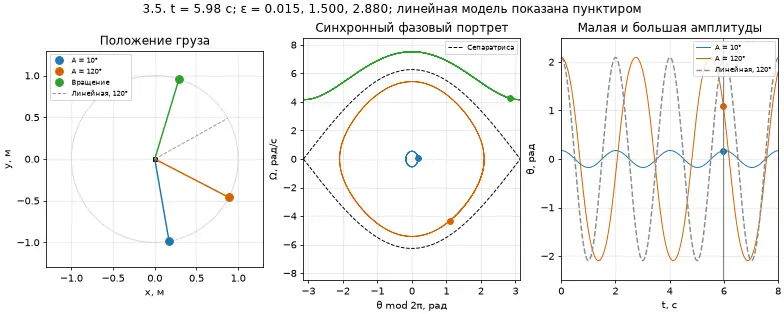
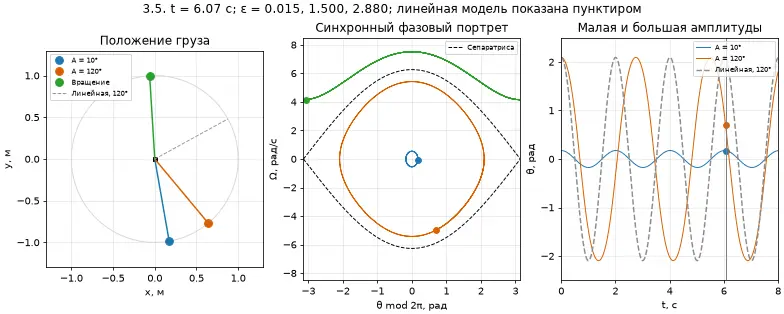
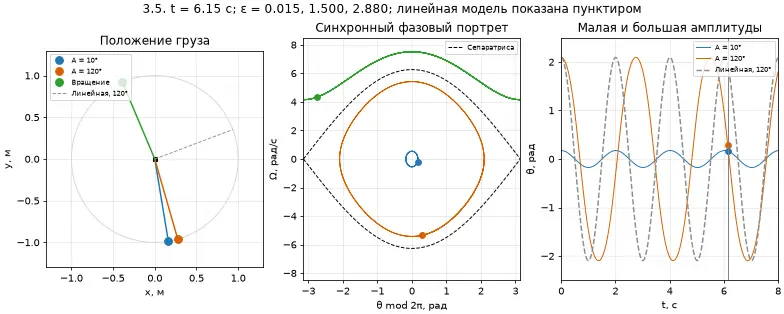
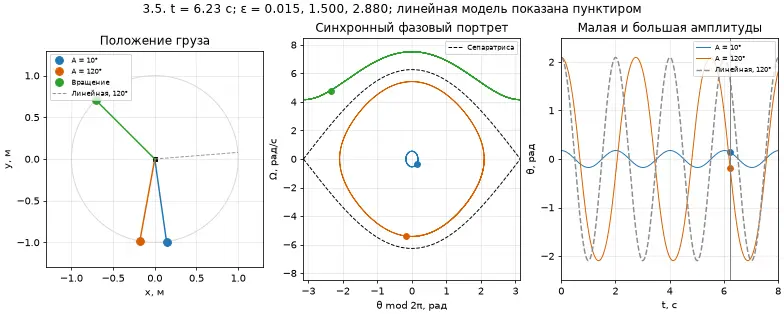
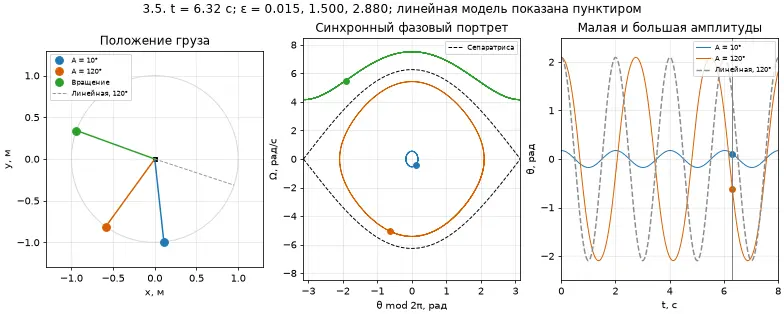
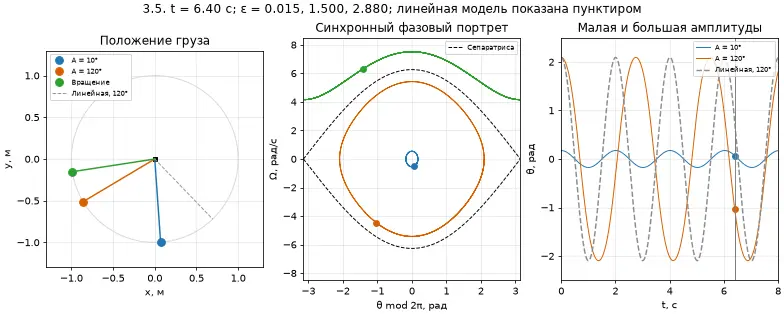
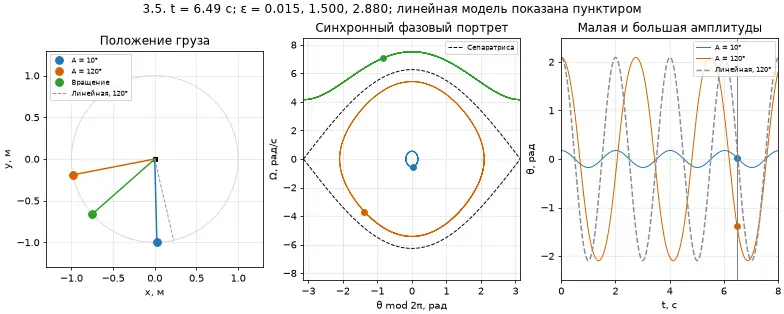
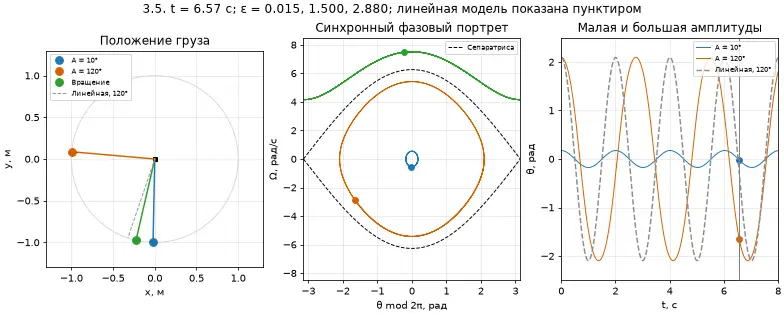
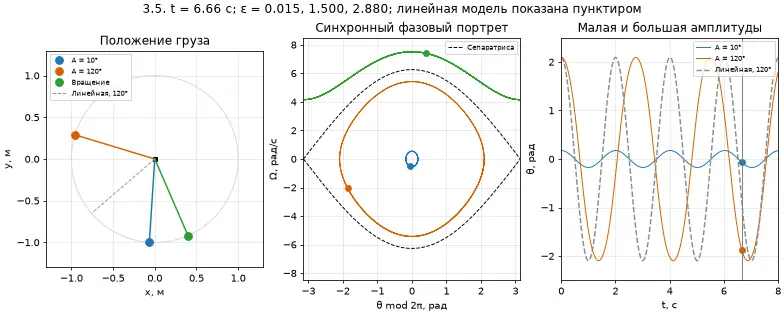
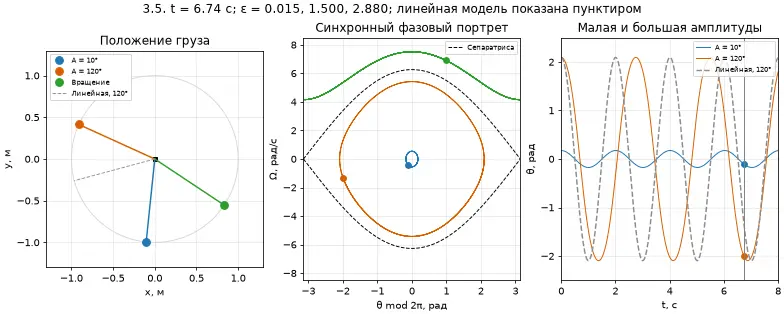
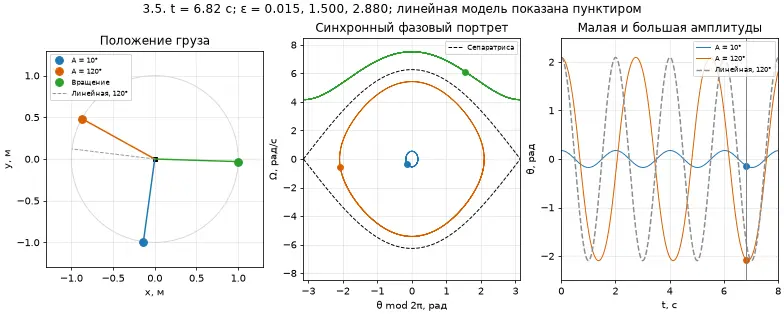
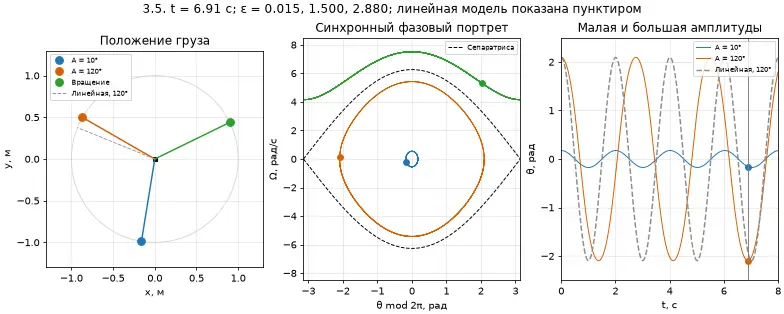
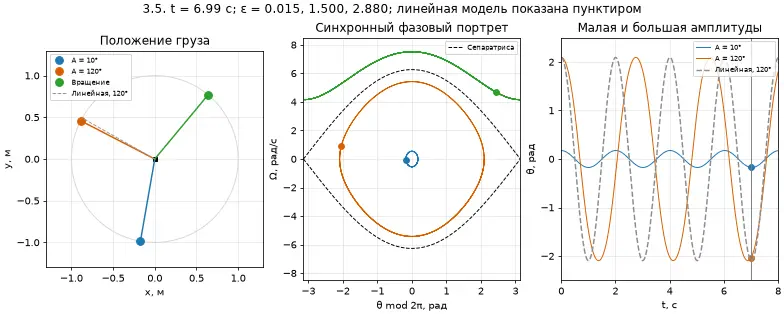
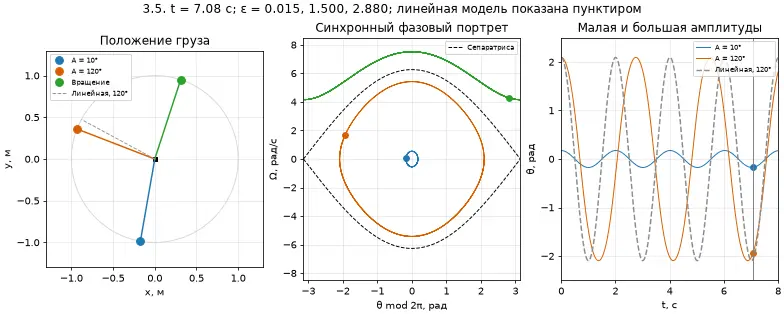
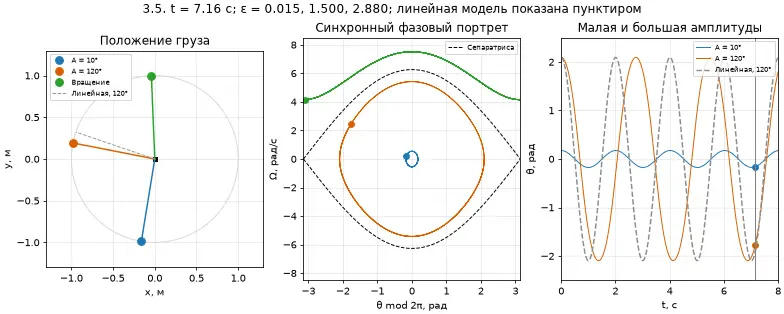
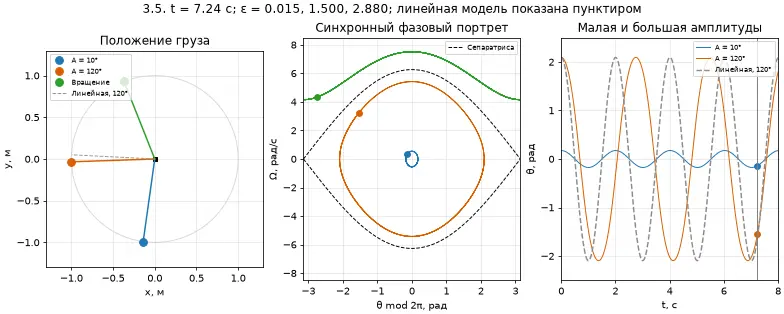
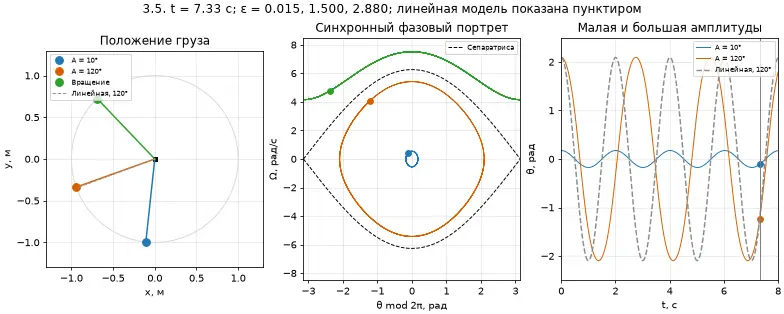
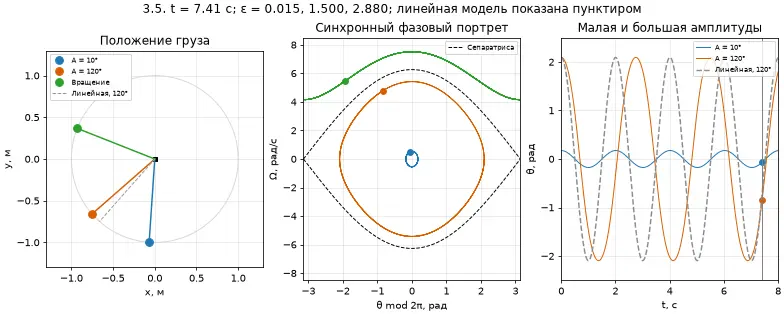
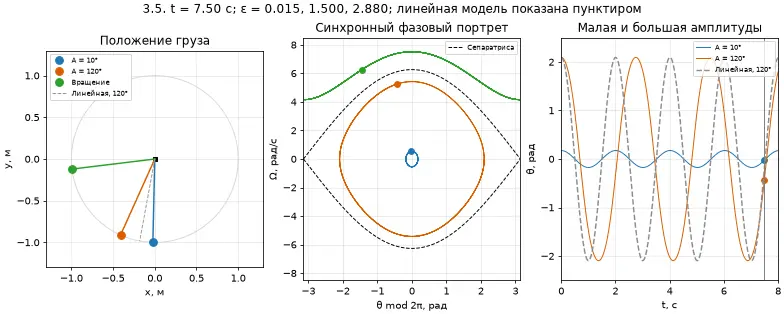
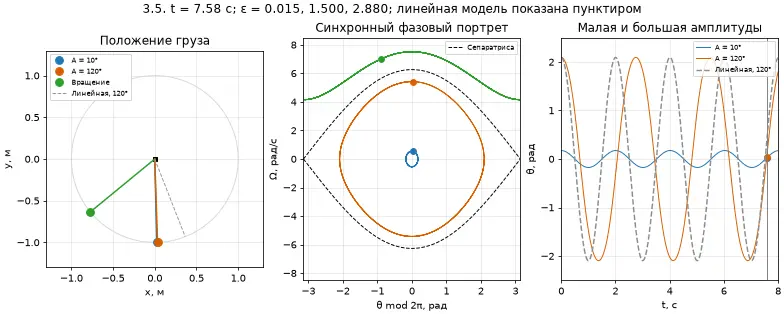
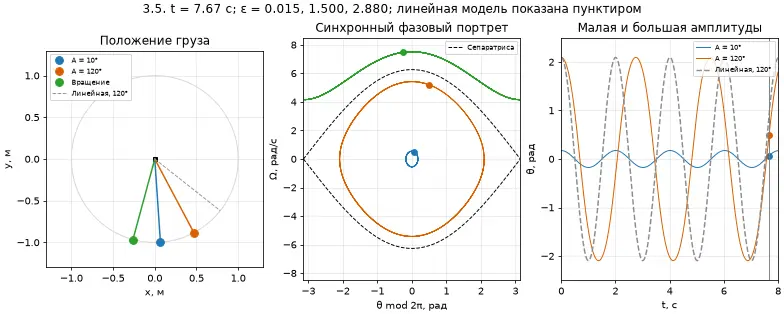
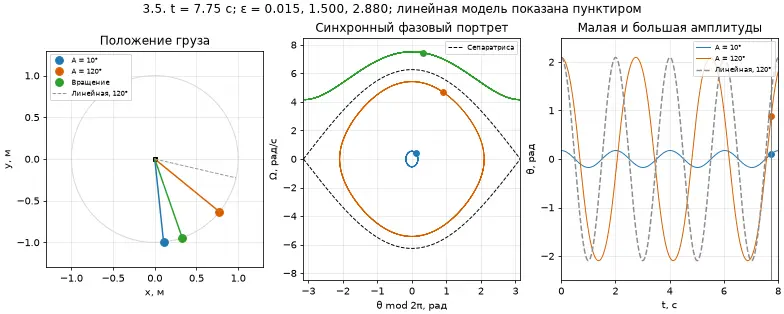
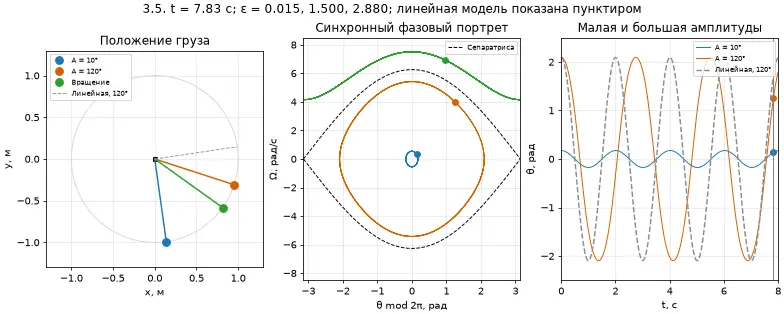
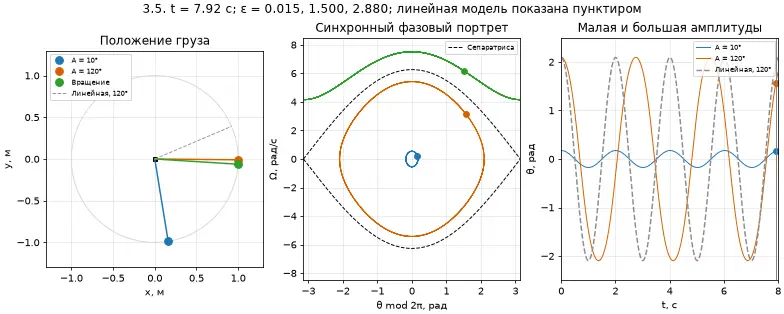
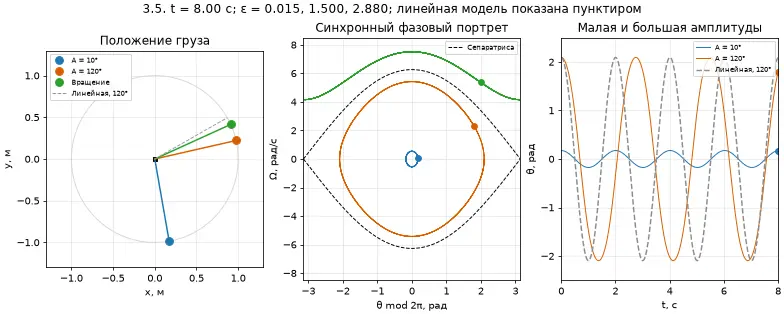

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, HTML
from pathlib import Path
from IPython import get_ipython
from PIL import Image as PILImage
import base64
import io
import re

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.dpi': 70, 'animation.embed_limit': 100})
Path('figures').mkdir(exist_ok=True)
Path('animations').mkdir(exist_ok=True)


def export_animation(fig, update, name, frames=72):
    # HTML содержит штатные кнопки воспроизведения, паузы и выбора кадра.
    animation = FuncAnimation(fig, update, frames=frames, interval=50,
                              blit=False, repeat=False)
    html = animation.to_jshtml(fps=20, default_mode='once')
    # Компактные кадры сохраняют автономность HTML и уменьшают размер ноутбука.
    def compact_frame(match):
        raw = base64.b64decode(match.group(1).replace('\\', '').replace('\n', ''))
        buffer = io.BytesIO()
        with PILImage.open(io.BytesIO(raw)) as image:
            image.convert('RGB').save(buffer, format='WEBP', quality=72, method=4)
        return 'data:image/webp;base64,'+base64.b64encode(buffer.getvalue()).decode('ascii')
    html = re.sub(r'data:image/png;base64,([A-Za-z0-9+/=\\\n]+)', compact_frame, html)
    Path(f'animations/{name}.html').write_text(
        '<!doctype html><html lang="ru"><meta charset="utf-8">'
        f'<title>{name}</title><body>{html}</body></html>', encoding='utf-8')
    # GIF можно посмотреть прямо в README на GitHub без запуска Python.
    animation.save(f'animations/{name}.gif', writer=PillowWriter(fps=20), dpi=70)
    plt.close(fig)
    display(HTML(html))
    return animation


# 3.5: нелинейный маятник, точная формула и фазовый портрет.
from scipy.integrate import solve_ivp
from scipy.special import ellipk, ellipj

g, ell = 9.81, 1.0
omega0 = np.sqrt(g/ell)
Tlin = 2*np.pi/omega0
t = np.linspace(0, 8, 1601)


def rhs(time, state):
    return [state[1], -omega0**2*np.sin(state[0])]


def integrate(initial):
    solution = solve_ivp(rhs, [t[0], t[-1]], initial, t_eval=t,
                         method='DOP853', rtol=2e-11, atol=2e-12,
                         max_step=0.03)
    assert solution.success
    return solution.y


def exact_libration(time, amplitude):
    k = np.sin(amplitude/2)
    sn, cn, dn, phase = ellipj(ellipk(k*k)-omega0*np.asarray(time), k*k)
    return 2*np.arcsin(np.clip(k*sn, -1, 1))


amplitudes = np.deg2rad([10, 60, 120, 170])
solutions = [integrate([A, 0]) for A in amplitudes]
rotation = integrate([0, 2.4*omega0])
max_energy_error = 0.0
max_exact_error = 0.0
print(f'3.5: линейный период Tлин = {Tlin:.10f} с')
for A, solution in zip(amplitudes, solutions):
    angle, speed = solution
    energy = .5*(speed/omega0)**2+1-np.cos(angle)  # E/(mgℓ)
    energy_error = np.max(np.abs(energy-energy[0]))
    exact_error = np.max(np.abs(angle-exact_libration(t, A)))
    max_energy_error = max(max_energy_error, energy_error)
    max_exact_error = max(max_exact_error, exact_error)
    assert energy_error < 1e-8 and exact_error < 2e-8
    period = 4*ellipk(np.sin(A/2)**2)/omega0
    print(f'A={np.rad2deg(A):.0f}°: T={period:.8f} с; '
          f'ошибка точной формулы={exact_error:.2e} рад; Δε={energy_error:.2e}')
rotation_energy = .5*(rotation[1]/omega0)**2+1-np.cos(rotation[0])
assert np.max(np.abs(rotation_energy-rotation_energy[0])) < 1e-8
print(f'Вращение: ε={rotation_energy[0]:.3f}>2; '
      f'максимальный дрейф ε={np.ptp(rotation_energy):.2e}.')

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8), constrained_layout=True)
colors = ['#1f77b4', '#2ca02c', '#d95f02', '#9467bd']
for A, solution, color in zip(amplitudes, solutions, colors):
    axes[0, 0].plot(t, solution[0], color=color, label=f'A={np.rad2deg(A):.0f}°')
axes[0, 0].plot(t, amplitudes[2]*np.cos(omega0*t), '--', color='0.4', lw=1,
                label='Линейная модель, 120°')
axes[0, 0].set(xlabel='t, с', ylabel='θ, рад', title='Угловое отклонение')
theta_grid = np.linspace(-np.pi, np.pi, 600)
for energy_level in [.15, .8, 1.5, 1.9, 2.4, 3.0]:
    speed2 = 2*omega0**2*(energy_level-1+np.cos(theta_grid))
    speeds = np.sqrt(np.maximum(speed2, 0))
    speeds[speed2 < 0] = np.nan
    color = '#1f77b4' if energy_level < 2 else '#d95f02'
    label = ('Колебания' if energy_level < 2 else 'Вращения') if energy_level in [.15, 2.4] else None
    axes[0, 1].plot(theta_grid, speeds, color=color, lw=1, label=label)
    axes[0, 1].plot(theta_grid, -speeds, color=color, lw=1)
sep = 2*omega0*np.cos(theta_grid/2)
axes[0, 1].plot(theta_grid, sep, 'k--', lw=1.6, label='Сепаратриса ε=2')
axes[0, 1].plot(theta_grid, -sep, 'k--', lw=1.6)
axes[0, 1].plot(0, 0, 'o', color='#2ca02c', label='Центр')
axes[0, 1].plot([-np.pi, np.pi], [0, 0], 'rx', label='Седла')
axes[0, 1].set(xlabel='θ, рад', ylabel='Ω, рад/с', title='Фазовый портрет', xlim=(-np.pi, np.pi))
angle_deg = np.linspace(.01, 179.5, 500)
periods = 4*ellipk(np.sin(np.deg2rad(angle_deg)/2)**2)/omega0
axes[1, 0].plot(angle_deg, periods, label='Точный период')
axes[1, 0].axhline(Tlin, color='0.4', ls='--', label='Малые колебания')
axes[1, 0].set(xlabel='Амплитуда A, градусы', ylabel='T(A), с', title='Рост периода при A → 180°')
for A, solution, color in zip(amplitudes, solutions, colors):
    energy = .5*(solution[1]/omega0)**2+1-np.cos(solution[0])
    axes[1, 1].plot(t, energy-energy[0], color=color, label=f'A={np.rad2deg(A):.0f}°')
axes[1, 1].set(xlabel='t, с', ylabel='ε(t) − ε(0)', title='Проверка сохранения энергии')
axes[1, 1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
for ax in axes.flat: ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.savefig('figures/3_5_pendulum.png', dpi=170)
plt.show()

frames = 96
indices = np.round(np.linspace(0, len(t)-1, frames)).astype(int)
motion = [solutions[0], solutions[2], rotation]
motion_colors = ['#1f77b4', '#d95f02', '#2ca02c']
labels = ['A = 10°', 'A = 120°', 'Вращение']
fig, axes = plt.subplots(1, 3, figsize=(11.2, 4.5), constrained_layout=True)
ax_config, ax_phase, ax_time = axes
circle_t = np.linspace(0, 2*np.pi, 300)
ax_config.plot(ell*np.sin(circle_t), -ell*np.cos(circle_t), color='0.85', lw=1)
ax_config.plot(0, 0, 'ks', ms=5)
rods, masses, phase_points, phase_trails, time_points = [], [], [], [], []
for solution, color, label in zip(motion, motion_colors, labels):
    rod, = ax_config.plot([], [], color=color, lw=1.5)
    mass, = ax_config.plot([], [], 'o', color=color, ms=8, label=label)
    phase_trail, = ax_phase.plot([], [], color=color, lw=1)
    phase_point, = ax_phase.plot([], [], 'o', color=color, ms=6)
    if label != 'Вращение':
        ax_time.plot(t, solution[0], color=color, lw=1, label=label)
    time_point, = ax_time.plot([], [], 'o', color=color, ms=6)
    rods.append(rod); masses.append(mass)
    phase_points.append(phase_point); phase_trails.append(phase_trail); time_points.append(time_point)
linear_theta = amplitudes[2]*np.cos(omega0*t)
ax_time.plot(t, linear_theta, '--', color='0.55', label='Линейная, 120°')
linear_rod, = ax_config.plot([], [], '--', color='0.6', lw=1, label='Линейная, 120°')
ax_config.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), xlabel='x, м', ylabel='y, м', title='Положение груза')
ax_config.set_aspect('equal'); ax_config.legend(fontsize=7, loc='upper left')
ax_phase.plot(theta_grid, sep, 'k--', lw=1, label='Сепаратриса')
ax_phase.plot(theta_grid, -sep, 'k--', lw=1)
ax_phase.set(xlim=(-np.pi, np.pi), ylim=(-8.5, 8.5), xlabel='θ mod 2π, рад', ylabel='Ω, рад/с',
             title='Синхронный фазовый портрет')
ax_phase.legend(fontsize=7)
ax_time.set(xlim=(0, 8), ylim=(-2.5, 2.5), xlabel='t, с', ylabel='θ, рад', title='Малая и большая амплитуды')
time_cursor = ax_time.axvline(0, color='0.5', lw=1)
ax_time.legend(fontsize=7, loc='upper right')
for ax in axes: ax.grid(alpha=.3)
title = fig.suptitle('')


def update_35(i):
    k = indices[i]
    for j, solution in enumerate(motion):
        angle, speed = solution[:, k]
        x, y = ell*np.sin(angle), -ell*np.cos(angle)
        rods[j].set_data([0, x], [0, y]); masses[j].set_data([x], [y])
        wrapped = (solution[0, :k+1]+np.pi) % (2*np.pi)-np.pi
        speeds = solution[1, :k+1].copy()
        # Разрываем след при переходе через край фазового цилиндра.
        jumps = np.flatnonzero(np.abs(np.diff(wrapped)) > np.pi)+1
        wrapped = wrapped.copy(); wrapped[jumps] = np.nan
        phase_trails[j].set_data(wrapped, speeds)
        phase_points[j].set_data([(angle+np.pi) % (2*np.pi)-np.pi], [speed])
        if j < 2: time_points[j].set_data([t[k]], [angle])
    xl, yl = ell*np.sin(linear_theta[k]), -ell*np.cos(linear_theta[k])
    linear_rod.set_data([0, xl], [0, yl]); time_cursor.set_xdata([t[k], t[k]])
    title.set_text(f'3.5. t = {t[k]:.2f} с; ε = 0.015, 1.500, 2.880; '
                   'линейная модель показана пунктиром')
    return []


animation_35 = export_animation(fig, update_35, '3_5_pendulum', frames)
